<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** uRNA structures of the mouse brain ROI: DRVI embedding, clustering, annotation, parent cell and neighborhood scores.
> - **Manuscript panels:** Fig. 2D-H, ED Fig. 3C-G
> - **Inputs:** Annotated xenium_msbrain_5k zarr with `structure_table`
> - **Outputs:** Structure-annotated zarr and figures
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

We employ this notebook to perform DRVI on segmented structures 

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

from typing import Any

import anndata
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import seaborn as sns
from anndata import AnnData
from matplotlib import gridspec, rcParams
from spatialdata import SpatialData  # Assuming SpatialData is from scverse
from troutpy.pl.colors import get_colormap
import numpy as np
import sys
import seaborn as sns
from pathlib import Path




#import hotspot

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_te

In [ ]:
import anndata as ad
import scanpy as sc
from matplotlib import pyplot as plt
from IPython.display import display
#from gprofiler import GProfiler

import drvi
from drvi.model import DRVI
from drvi.utils.misc import hvg_batch

In [ ]:
import sys
import os 


In [ ]:
# Import local pipeline submodules directly
from troutpy import pl
from troutpy import tl
from troutpy import pp

In [ ]:
# Define base directories
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k")



# Do first steps

In [6]:
# Read spatial data using the / operator for clean path joining
sdata = sd.read_zarr(data_dir / "data_annotated.zarr")

sdata['table'].obs['cell_area']
sdata['structure_table'].obs['area']

struct_0        192746.835571
struct_1          2259.617920
struct_2           170.305908
struct_3           294.953857
struct_4        681020.874390
                    ...      
struct_39253              NaN
struct_39254              NaN
struct_39255              NaN
struct_39256              NaN
struct_39257              NaN
Name: area, Length: 39258, dtype: float64

In [7]:
sdata['image_intensity_per_transcript'].obs

,gene
0,Apc
1,Dlg4
2,Csde1
3,Snrpn
4,Runx2
...,...
23790751,Snrpn
23790752,Cdc42bpb
23790753,Ppp1r7
23790754,Runx2


# Structure composition

═══════════════════════════════════════════════════════
  CELLS  (n = 9,185)
═══════════════════════════════════════════════════════
  range    n       pct
    0–9    0  0.000000
  10–24    0  0.000000
  25–49    0  0.000000
  50–99    2  0.021775
100–249  183  1.992379
250–499 3166 34.469243
500–999 5834 63.516603
  ≥1000    0  0.000000
  median=538  mean=517.1  p10=376  p90=622

═══════════════════════════════════════════════════════
  FRAGMENTS  (n = 39,258)
═══════════════════════════════════════════════════════
  range     n       pct
    0–9 29755 75.793469
  10–24  4546 11.579805
  25–49  1764  4.493352
  50–99  1158  2.949717
100–249   984  2.506495
250–499   525  1.337307
500–999   298  0.759081
  ≥1000   228  0.580773
  median=3  mean=96.9  p10=1  p90=35

KS two-sample test: D = 0.962, p = 0.00e+00



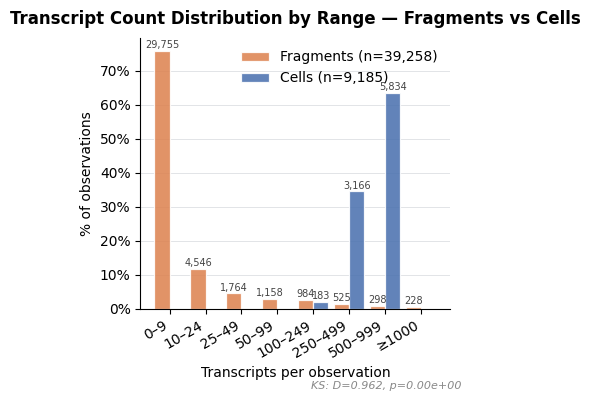

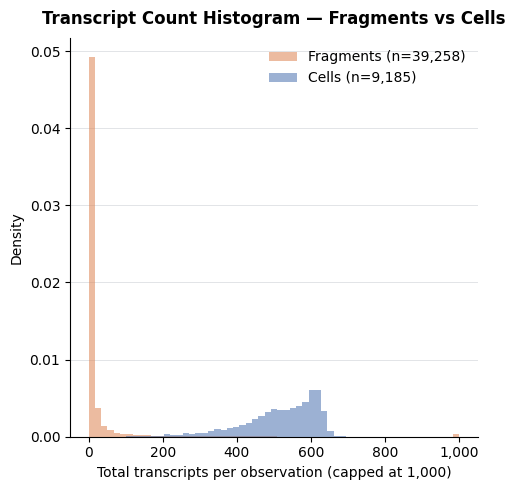

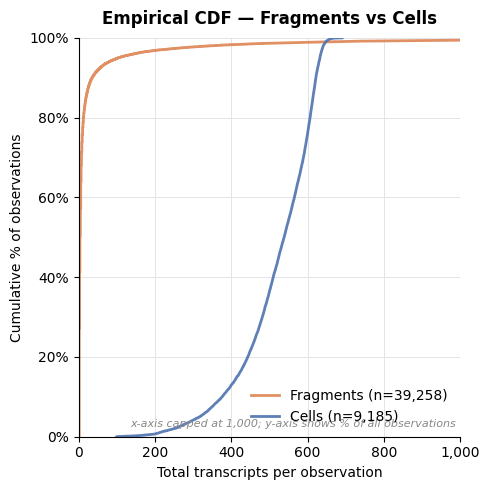

Saved → fig1_transcript_ranges.png  (main)
Saved → fig2_transcript_histogram.png
Saved → fig3_transcript_cdf.png


In [8]:
"""
Visualize and compare the distribution of transcripts per fragment vs per cell.
Three separate figures:
  1. (MAIN) Grouped bar chart — % of observations per transcript-count range
  2. Overlaid histogram — raw counts, linear scale
  3. Empirical CDF — 0–100 % y-axis, x-axis capped at 1000

Assumptions:
  - sdata['table']            : AnnData with cells     (obs × genes)
  - sdata['structure_table']  : AnnData with fragments (obs × genes)
  Both tables have .X (raw counts) from which total transcripts per observation
  are computed via row-sum.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

# ── 0. Style ──────────────────────────────────────────────────────────────────
CELL_COLOR     = "#4C72B0"
FRAGMENT_COLOR = "#DD8452"
GRID           = "#E2E4E7"
plt.rcParams.update({"font.size": 10,
                     "axes.spines.top": False,
                     "axes.spines.right": False})

# ── 1. Total transcripts per observation ─────────────────────────────────────
def total_counts(adata):
    X = adata.X
    if hasattr(X, "toarray"):
        return np.asarray(X.sum(axis=1)).ravel()
    return np.asarray(X.sum(axis=1)).ravel()

cell_counts     = total_counts(sdata["table"])
fragment_counts = total_counts(sdata["structure_table"])

# ── 2. Fixed bin edges — max category ">1000" ────────────────────────────────
edges = [0, 10, 25, 50, 100, 250, 500, 1000, np.inf]

range_labels = ["0–9", "10–24", "25–49", "50–99",
                "100–249", "250–499", "500–999", "≥1000"]

def make_df(arr):
    counts, _ = np.histogram(arr, bins=edges)
    pct = counts / counts.sum() * 100
    return pd.DataFrame({"range": range_labels, "n": counts, "pct": pct})

df_cells     = make_df(cell_counts)
df_fragments = make_df(fragment_counts)

# ── 3. Print summary ──────────────────────────────────────────────────────────
for name, df, arr in [
    ("CELLS",     df_cells,     cell_counts),
    ("FRAGMENTS", df_fragments, fragment_counts),
]:
    print("═" * 55)
    print(f"  {name}  (n = {len(arr):,})")
    print("═" * 55)
    print(df.to_string(index=False))
    print(f"  median={np.median(arr):.0f}  mean={arr.mean():.1f}"
          f"  p10={np.percentile(arr,10):.0f}  p90={np.percentile(arr,90):.0f}\n")

ks_stat, ks_p = stats.ks_2samp(fragment_counts, cell_counts)
print(f"KS two-sample test: D = {ks_stat:.3f}, p = {ks_p:.2e}\n")

# ═════════════════════════════════════════════════════════════════════════════
# FIGURE 1 (MAIN) — Grouped bar chart
# ═════════════════════════════════════════════════════════════════════════════
fig1, ax = plt.subplots(figsize=(4, 4))

n_bins = len(df_cells)
x      = np.arange(n_bins)
w      = 0.42   # wider bars

bars_f = ax.bar(x - w/2, df_fragments["pct"], w,
                color=FRAGMENT_COLOR,
                label=f"Fragments (n={len(fragment_counts):,})",
                alpha=0.88, edgecolor="white", linewidth=0.9)
bars_c = ax.bar(x + w/2, df_cells["pct"], w,
                color=CELL_COLOR,
                label=f"Cells (n={len(cell_counts):,})",
                alpha=0.88, edgecolor="white", linewidth=0.9)

for bars, df in [(bars_f, df_fragments), (bars_c, df_cells)]:
    for bar, (_, row) in zip(bars, df.iterrows()):
        h = bar.get_height()
        if h > 0.5:
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.25,
                    f"{int(row['n']):,}", ha="center", va="bottom",
                    fontsize=7, color="#444")

ax.set_xticks(x)
ax.set_xticklabels(range_labels, rotation=30, ha="right")
ax.set_ylabel("% of observations")
ax.set_xlabel("Transcripts per observation")
ax.set_title("Transcript Count Distribution by Range — Fragments vs Cells",
             fontweight="bold", pad=10)
ax.legend(frameon=False)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax.yaxis.grid(True, color=GRID, linewidth=0.7, zorder=0)
ax.set_axisbelow(True)
fig1.text(0.99, 0.01, f"KS: D={ks_stat:.3f}, p={ks_p:.2e}",
          ha="right", va="bottom", fontsize=8, color="#888", style="italic")
fig1.tight_layout()
fig1.savefig("fig1_transcript_ranges.pdf", dpi=150, bbox_inches="tight")

# ═════════════════════════════════════════════════════════════════════════════
# FIGURE 2 — Overlaid histogram (linear, density-normalised, capped at 1000)
# ═════════════════════════════════════════════════════════════════════════════
fig2, ax2 = plt.subplots(figsize=(5, 5))

hist_bins = np.linspace(0, 1000, 60)

ax2.hist(fragment_counts.clip(max=1000), bins=hist_bins, density=True,
         color=FRAGMENT_COLOR, alpha=0.55,
         label=f"Fragments (n={len(fragment_counts):,})", edgecolor="none")
ax2.hist(cell_counts.clip(max=1000), bins=hist_bins, density=True,
         color=CELL_COLOR, alpha=0.55,
         label=f"Cells (n={len(cell_counts):,})", edgecolor="none")

ax2.set_xlabel("Total transcripts per observation (capped at 1,000)")
ax2.set_ylabel("Density")
ax2.set_title("Transcript Count Histogram — Fragments vs Cells",
              fontweight="bold", pad=10)
ax2.legend(frameon=False)
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax2.yaxis.grid(True, color=GRID, linewidth=0.7, zorder=0)
ax2.set_axisbelow(True)
fig2.tight_layout()
fig2.savefig("fig2_transcript_histogram.pdf", dpi=150, bbox_inches="tight")

# ═════════════════════════════════════════════════════════════════════════════
# FIGURE 3 — Empirical CDF (0–100 %, x capped at 1000)
# ═════════════════════════════════════════════════════════════════════════════
fig3, ax3 = plt.subplots(figsize=(5, 5))

for arr, label, color in [
    (fragment_counts, f"Fragments (n={len(fragment_counts):,})", FRAGMENT_COLOR),
    (cell_counts,     f"Cells (n={len(cell_counts):,})",         CELL_COLOR),
]:
    s   = np.sort(arr)
    cdf = np.arange(1, len(s) + 1) / len(s) * 100   # 0–100
    ax3.plot(s, cdf, color=color, lw=2, label=label, alpha=0.9)

ax3.set_xlim(0, 1000)
ax3.set_ylim(0, 100)
ax3.set_xlabel("Total transcripts per observation")
ax3.set_ylabel("Cumulative % of observations")
ax3.set_title("Empirical CDF — Fragments vs Cells", fontweight="bold", pad=10)
ax3.legend(frameon=False)
ax3.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax3.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax3.grid(True, color=GRID, linewidth=0.7)
ax3.set_axisbelow(True)
ax3.text(0.99, 0.02,
         "x-axis capped at 1,000; y-axis shows % of all observations",
         transform=ax3.transAxes, ha="right", va="bottom",
         fontsize=8, color="#888", style="italic")
fig3.tight_layout()
fig3.savefig("fig3_transcript_cdf.pdf", dpi=150, bbox_inches="tight")

plt.show()
print("Saved → fig1_transcript_ranges.png  (main)")
print("Saved → fig2_transcript_histogram.png")
print("Saved → fig3_transcript_cdf.png")

In [10]:
# Quantify structures by are and by counts

# Do DRVI

In [9]:
# We filter structure table
sc.pp.filter_cells(sdata['structure_table'],min_counts=5)
sc.pp.filter_cells(sdata['structure_table'],min_genes=2)
#sc.pp.filter_genes(sdata['structure_table'],min_cells=50)

In [10]:
adata=sdata['structure_table']
adata.layers['counts']=adata.X

# Setup data
DRVI.setup_anndata(
    adata,
    # DRVI accepts count data by default.
    # Do not forget to change gene_likelihood if you provide a non-count data.
    layer="counts",
    # Always provide a list. DRVI can accept multiple covariates.
    #categorical_covariate_keys=["batch"],
    # DRVI accepts count data by default.
    # Set to false if you provide log-normalized data and use normal distribution (mse loss).
    is_count_data=True,
)

# construct the model
model = DRVI(
    adata,
    # Provide categorical covariates keys once again. Refer to advanced usages for more options.
    #categorical_covariates=["batch"],
    n_latent=128,
    # For encoder and decoder dims, provide a list of integers.
    encoder_dims=[128, 128],
    decoder_dims=[128, 128])


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


INFO     DRVI: The model has been initialized                                                                      


In [11]:
# For cpu training you should add the following line to the model.train parameters:
# accelerator="cpu", devices=1,
#
# For mps acceleration on macbooks, add the following line to the model.train parameters:
# accelerator="mps", devices=1,
#
# For gpu training don't provide any additional parameter.
# More details here: https://lightning.ai/docs/pytorch/stable/accelerators/gpu_basic.html

n_epochs = 200

# train the model
model.train(
    max_epochs=n_epochs,
    early_stopping=False,
    early_stopping_patience=20,
    # No need to provide `plan_kwargs` if n_epochs >= 400.
    plan_kwargs={
        "n_epochs_kl_warmup": n_epochs,
    },
)

# Runtime:
# The runtime for CPU laptop (M1) is 208 minutes
# The runtime for Macbook gpu (M1) is 64 minutes
# The runtime for GPU (A100) is 17 minutes

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-PCIE-40GB MIG 3g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-d3a35b4d-3098-5a16-aa07-393e8fdc9272]
SLURM auto-requeueing enabled. Setting signal handlers.


Epoch 200/200: 100%|██████████| 200/200 [19:48<00:00,  5.93s/it, v_num=1, train_loss_step=189, train_loss_epoch=203]    

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [19:48<00:00,  5.94s/it, v_num=1, train_loss_step=189, train_loss_epoch=203]


In [12]:
# Save the model
model.save("/home/icb/sergio.salas/outputs_temp/troutpy_drvi/drvi_general_pipeline_mousebrain", overwrite=True)

# Load again DRVI

In [10]:
adata=sdata['structure_table']
adata.layers['counts']=adata.X

In [11]:
import torch

def torch_load_weights_only_false(*args, **kwargs):
    kwargs["weights_only"] = False
    return orig_torch_load(*args, **kwargs)

orig_torch_load = torch.load
torch.load = torch_load_weights_only_false

# Load the model
model = DRVI.load("/home/icb/sergio.salas/outputs_temp/troutpy_drvi/drvi_general_pipeline_mousebrain",adata)

INFO     File /home/icb/sergio.salas/outputs_temp/troutpy_drvi/drvi_general_pipeline_mousebrain/model.pt already   
         downloaded                                                                                                


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


INFO     DRVI: The model has been initialized                                                                      


INFO     DRVI: The model has been initialized                                                                      


In [33]:
embed = ad.AnnData(model.get_latent_representation(), obs=adata.obs)
drvi.utils.tl.set_latent_dimension_stats(model, embed,vanished_threshold=2)
print(embed[:,embed.var['vanished']==False].shape)
#print(embed.var.sort_values("reconstruction_effect", ascending=False))
embed=embed[:,embed.var['vanished']==False]

(16811, 10)


In [34]:
sc.pp.neighbors(embed, n_neighbors=7, use_rep="X", n_pcs=embed.X.shape[1])
sc.tl.umap(embed, spread=1.0, min_dist=0.1, random_state=123)

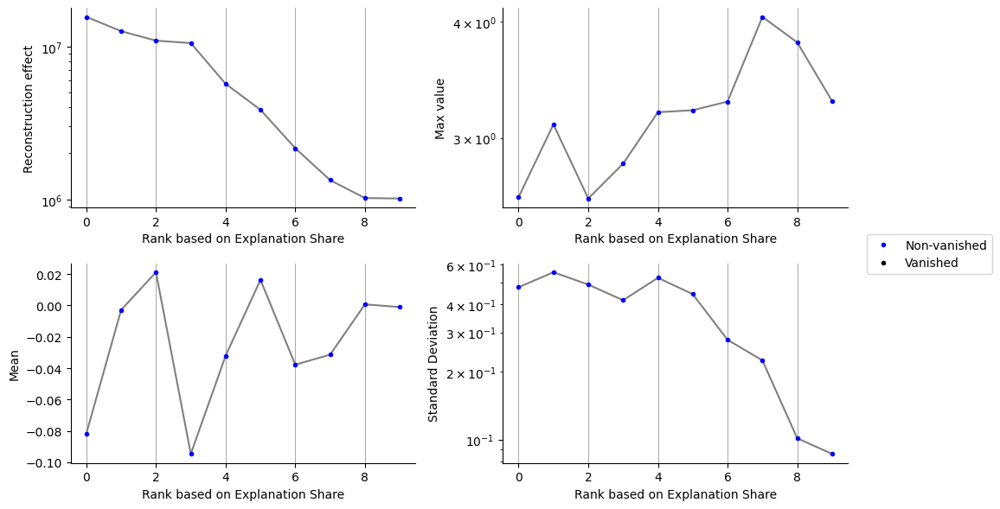

In [35]:
drvi.utils.pl.plot_latent_dimension_stats(embed, ncols=2,show=False)
plt.savefig(os.path.join(saving_path,'latent_dimension_stats_all.pdf'))

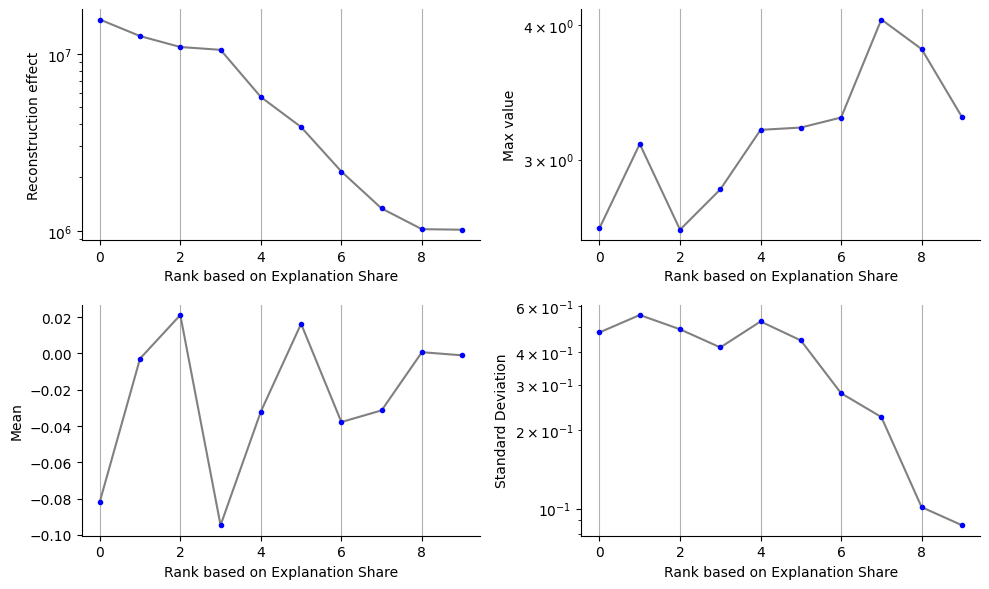

In [36]:
drvi.utils.pl.plot_latent_dimension_stats(embed, ncols=2, remove_vanished=True,show=False)
plt.savefig(os.path.join(saving_path,'latent_dimension_stats.pdf'))

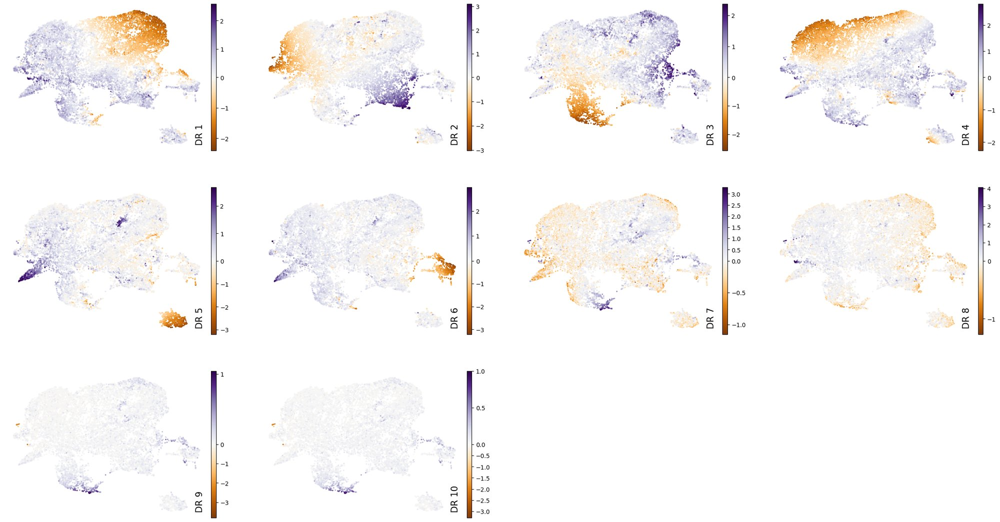

In [37]:
drvi.utils.pl.plot_latent_dims_in_umap(embed,cmap='PuOr',vcenter=0,s=20)

In [40]:
sc.tl.leiden(embed,key_added='urna_cluster',resolution=0.6)

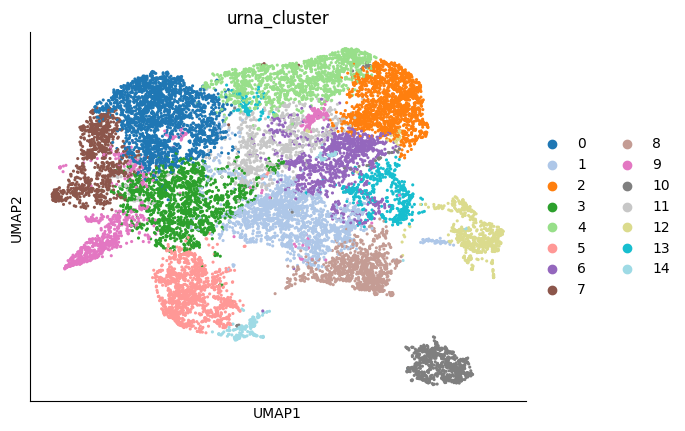

In [41]:
sc.pl.umap(embed,color='urna_cluster',palette='tab20',s=20)

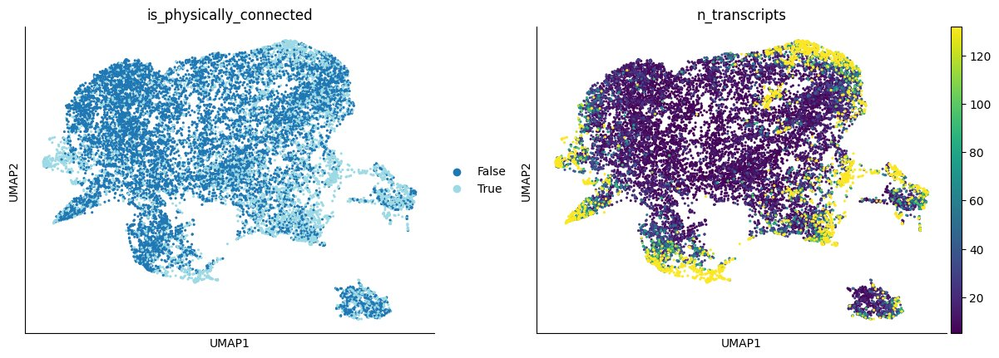

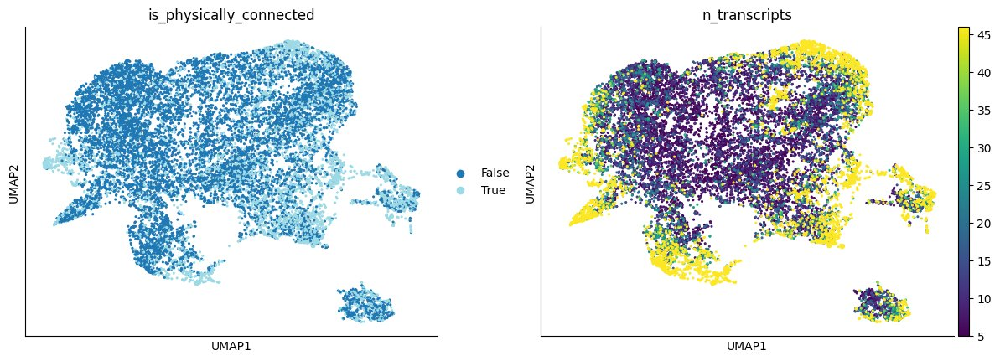

In [42]:
sc.pl.umap(embed,color=['is_physically_connected','n_transcripts'],palette='tab20',s=20,vmax='p90')
sc.pl.umap(embed,color=['is_physically_connected','n_transcripts'],palette='tab20',s=20,vmax='p80')

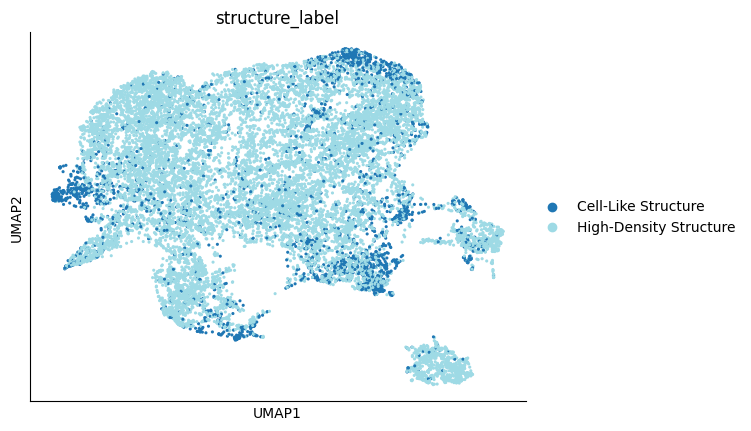

In [43]:
sc.pl.umap(embed,color=['structure_label'],palette='tab20',s=20,vmax='p90')

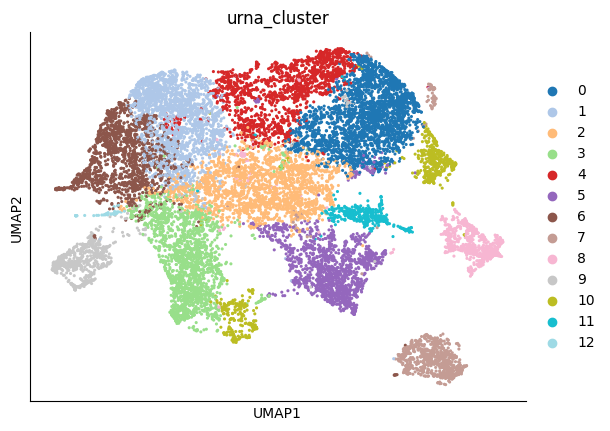

In [31]:
sc.pl.umap(embed,color='urna_cluster',palette='tab20',s=20)

<Axes: xlabel='urna_cluster'>

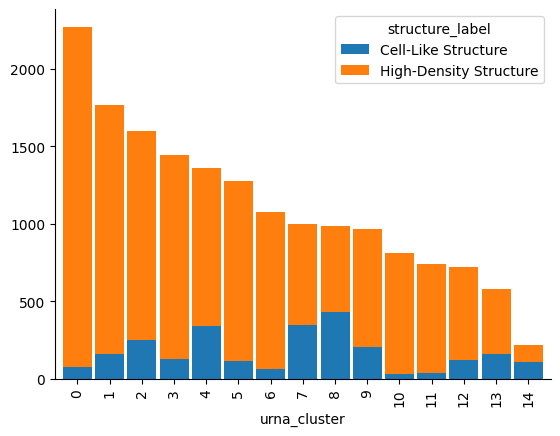

In [44]:
structure_vs_urna=pd.crosstab(embed.obs['urna_cluster'],embed.obs['structure_label'])
structure_vs_urna.plot(stacked=True,kind='bar',width=0.9)

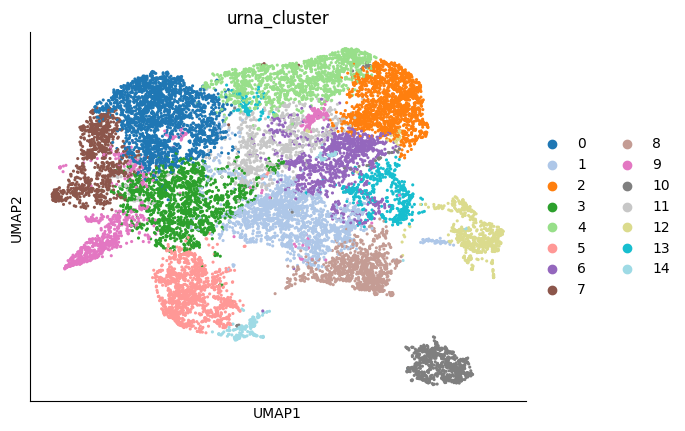

In [45]:
sc.pl.umap(embed,color='urna_cluster',palette='tab20',s=20)

<Axes: xlabel='urna_cluster'>

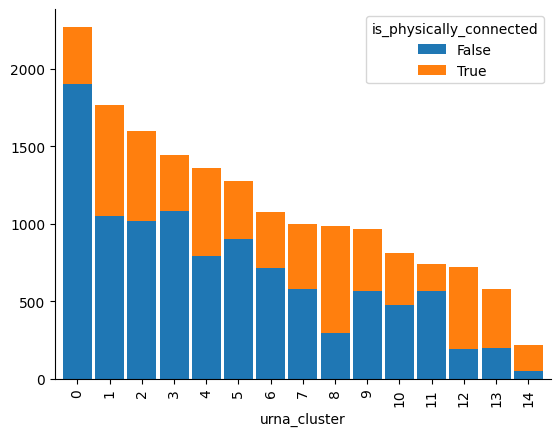

In [46]:
str2urna=dict(zip(embed.obs.index,embed.obs['urna_cluster']))
sdata['structure_table'].obs['urna_cluster']=sdata['structure_table'].obs.index.map(str2urna)
structure_vs_urna=pd.crosstab(embed.obs['urna_cluster'],embed.obs['is_physically_connected'])
structure_vs_urna.plot(stacked=True,kind='bar',width=0.9)

In [47]:
#embed.obs.loc[['x','y']]
embed.obsm['spatial']=np.array(embed.obs.loc[:,['x','y']])

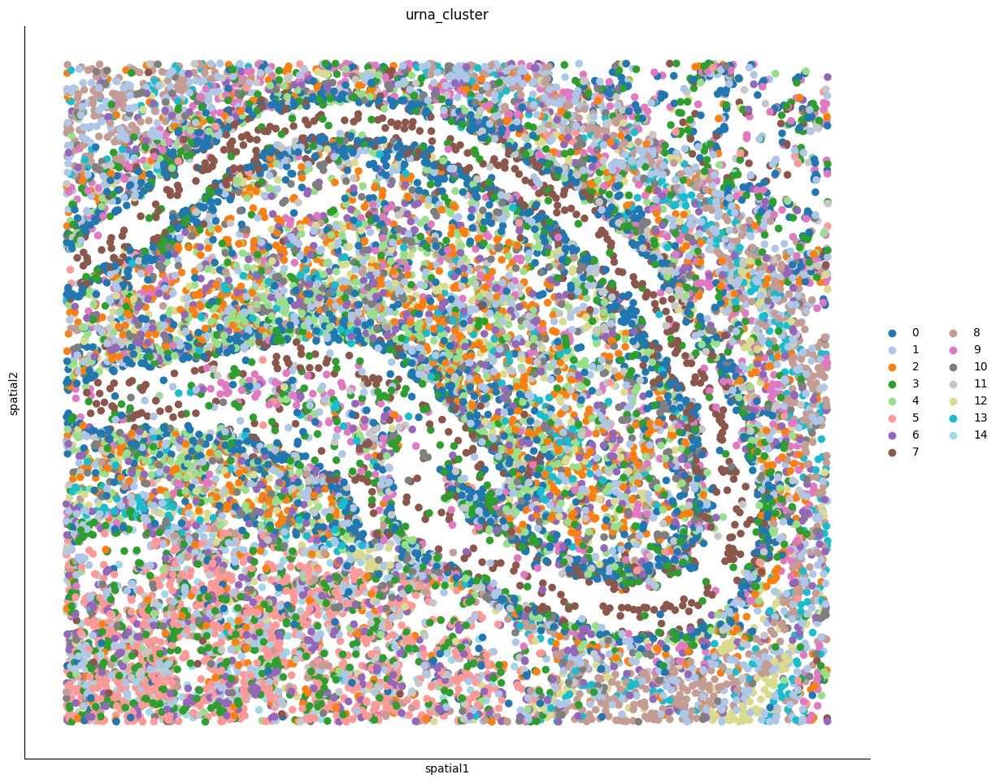

In [48]:
import numpy as np

embed.obsm['spatial'] = embed.obsm['spatial'][:, ::-1]  # swap columns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))
sc.pl.spatial(embed, spot_size=20, color='urna_cluster', ax=ax, show=False)
ax.invert_yaxis()  # or ax.invert_yaxis() depending on which axis needs flipping
plt.tight_layout()
plt.show()

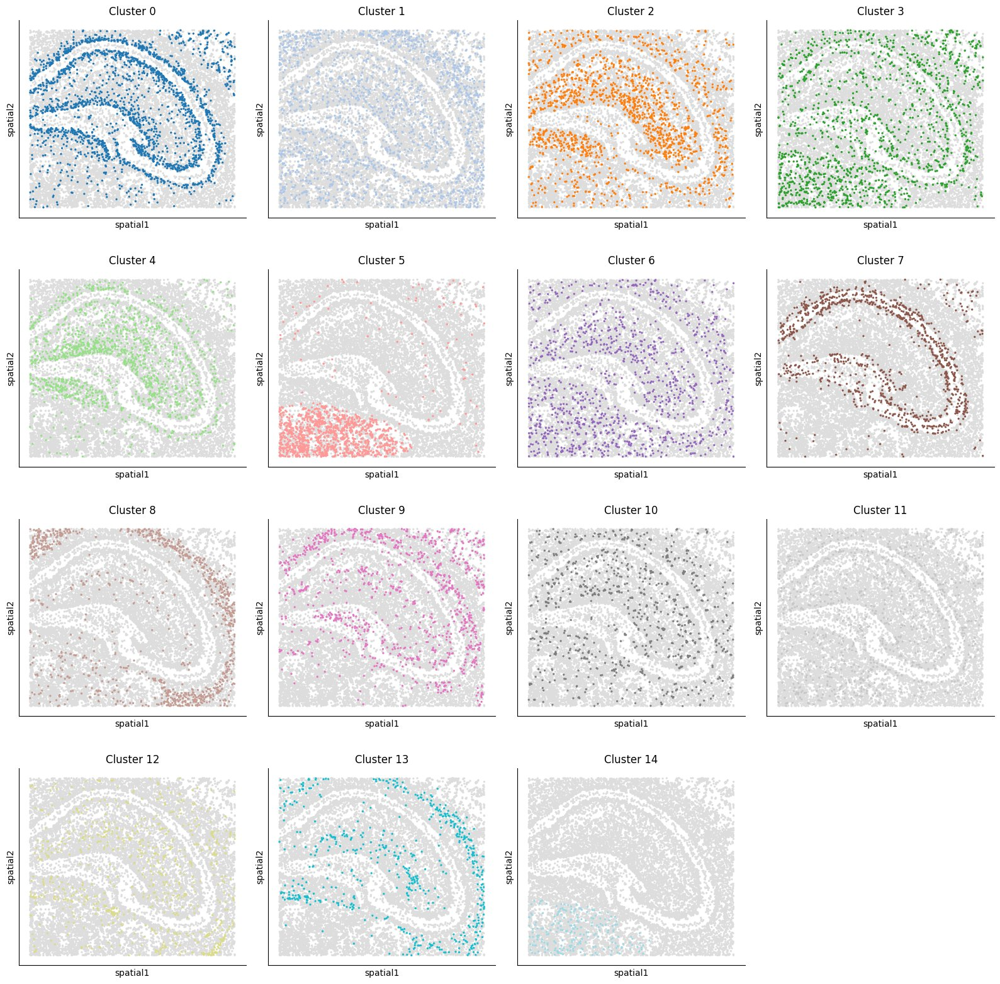

In [49]:
import matplotlib.pyplot as plt
import numpy as np

clusters = embed.obs['urna_cluster'].cat.categories.tolist()
palette  = dict(zip(clusters, sc.pl.palettes.default_20[:len(clusters)]))

n_cols = 4
n_rows = int(np.ceil(len(clusters) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 4))
axes = axes.flatten()

for i, cluster in enumerate(clusters):
    ax = axes[i]
    
    # grey background — all cells
    sc.pl.spatial(embed, spot_size=20, color='urna_cluster',
                  groups=[cluster],   # highlight only this cluster
                  ax=ax, show=False,
                  na_color="#DDDDDD",
                  legend_loc=None, colorbar_loc=None,
                  title=f"Cluster {cluster}")
    ax.invert_yaxis()

# hide unused axes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

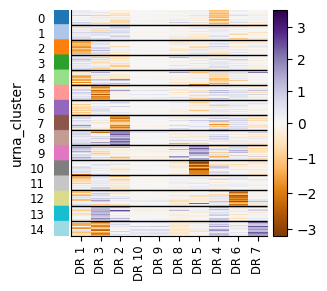

In [54]:
drvi.utils.pl.plot_latent_dims_in_heatmap(embed, "urna_cluster", title_col="title",cmap='PuOr', sort_by_categorical=True,show=False,figsize=(3,3))
plt.savefig(os.path.join(saving_path,'drvi_on_urna_clusters.pdf'))

In [58]:
embed_all = ad.AnnData(model.get_latent_representation(), obs=adata.obs)
drvi.utils.tl.set_latent_dimension_stats(model, embed_all,vanished_threshold=2)

In [59]:
traverse_adata = drvi.utils.tl.traverse_latent(model, embed_all, n_samples=20, max_noise_std=0.0)
drvi.utils.tl.calculate_differential_vars(traverse_adata)


traversing latent ...
Input latent shape: control: (51200, 128), effect: (51200, 128)
Output mean param shape: control: (51200, 13073), effect: (51200, 13073)
Finding differential variables per latent dimension ...


Output mean param shape: control: (51200, 2958), effect: (51200, 2958)
Finding differential variables per latent dimension ...


In [61]:
traverse_adata.write(os.path.join(data_dir,"drvi_msbrain_traverse_adata.h5ad"))
traverse_adata = sc.read(os.path.join(data_dir,"drvi_msbrain_traverse_adata.h5ad"))


In [62]:
embed.write(os.path.join(data_dir,"drvi_msbrain_embed_adata.h5ad"))

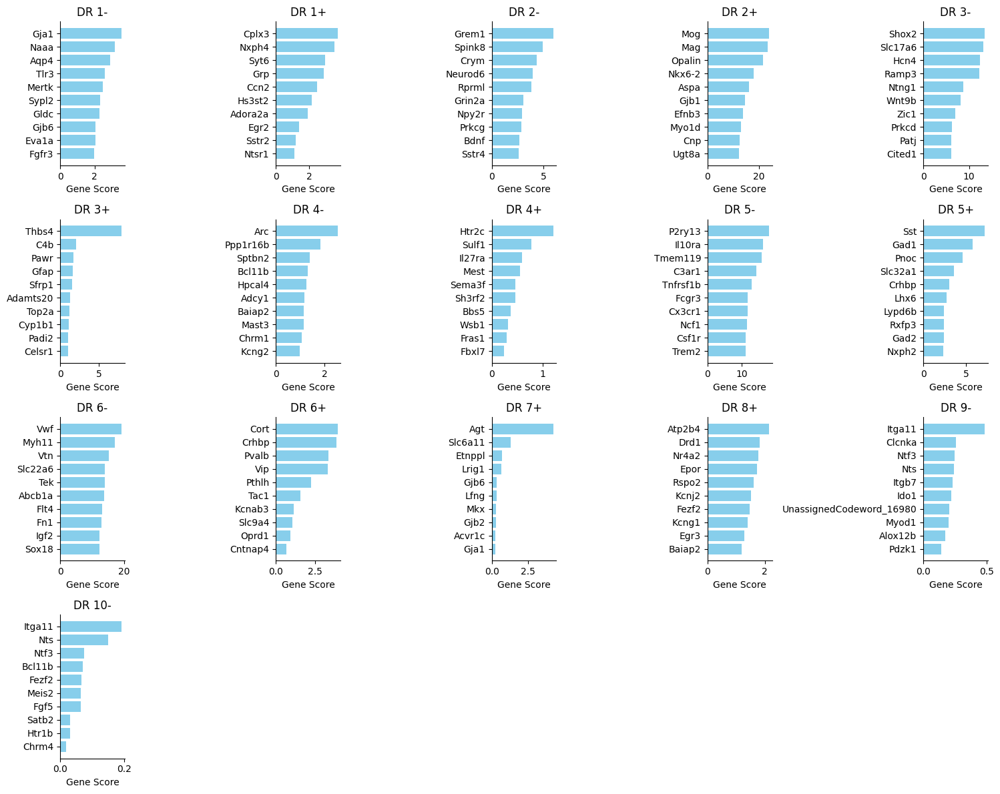

In [63]:
drvi.utils.pl.show_top_differential_vars(traverse_adata, key="combined_score", score_threshold=0.0,show=False)
plt.savefig(os.path.join(saving_path,'drvi_deg_by_dr_barplot.pdf'))

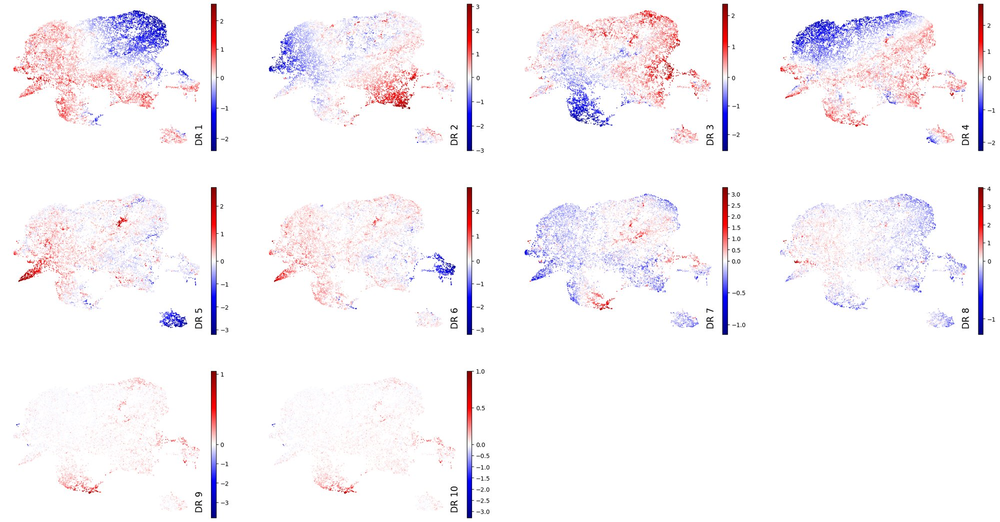

In [64]:
drvi.utils.pl.plot_latent_dims_in_umap(embed)

In [65]:
embed.obsm['spatial']=adata[embed.obs.index,:].obsm['spatial']
embed_filt=embed[:,embed.var['vanished']==False]
embed_filt=embed_filt[:,embed_filt.var.sort_values(by='order').index]

In [67]:
dict_DR_programs = {
    "DR 1": "Neuronal Protrusions (+) / Astrocytic Structural Borders (-)",
    "DR 2": "Myelin Sheath Contamination (+) / Pyramidal Cell Body Protrusions (-)",
    "DR 3": "Reactive Glia-Pial Edge (+) / Thalamic Neuronal Protrusions (-)",
    "DR 4": "Non-Neuronal Membrane Bleeding (+) / Deep-Layer Cortical Axons (-)",
    "DR 5": "Inhibitory Interneuron Edges (+) / Microglial Processes (-)",
    "DR 6": "Cortical Interneuron Protrusions (+) / Vascular-Mural Wall Clipping (-)",
    "DR 7": "Specialized Subcortical Astrocytic Edges (+)",
    "DR 8": "Striatal/Dopaminergic Neuronal Segments (+)",
    "DR 9": "Extracellular Matrix & Vascular Protrusions (+)",
    "DR 10": "Deep Cortical Subcerebral Projection Axons (+)",
}

In [71]:
embed_filt.var['DR_annotation']=embed_filt.var['title'].map(dict_DR_programs)

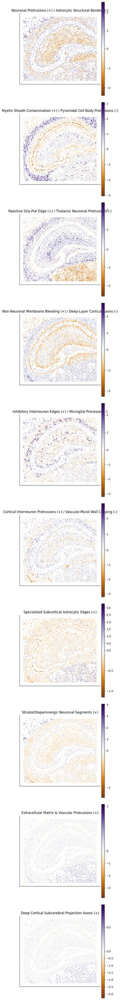

In [74]:
import os
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

# 1. Define the exact order you want ALL your DR programs to appear in the grid
all_titles_order = ["DR 1","DR 2","DR 3","DR 4", "DR 5", "DR 6", "DR 7","DR 8",
                    "DR 9", "DR 10",]

# 2. Map the titles back to the internal gene/var index while maintaining that exact order
title_to_index = dict(zip(embed_filt.var["title"], embed_filt.var.index))
ordered_all_genes = [title_to_index[title] for title in all_titles_order]

# 3. Handle the axis swap safely outside the loop
spatial_swapped = embed_filt.obsm["spatial"][:, [1, 0]]
embed_filt.obsm["spatial"] = spatial_swapped


# 4. Modified plotting function to include your custom multi-line annotation titles
def plot_all_gene_programs(genes, filename, ncols=1, figsize_base=5):
    n_genes = len(genes)
    nrows = int(np.ceil(n_genes / ncols))

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(figsize_base * ncols, figsize_base * nrows)
    )
    axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

    for ax, g in zip(axes, genes):
        # Fetch the annotation you mapped earlier
        full_annotation = embed_filt.var.loc[g, "DR_annotation"]

        sc.pl.spatial(
            embed_filt,
            color=g,
            title=full_annotation,  # <--- Displays the full "DR X: Description (+) / Description (-)"
            spot_size=15,
            cmap="PuOr",
            vcenter=0,
            ax=ax,
            show=False,
            legend_fontsize=10,
        )
        ax.invert_yaxis()
        ax.invert_xaxis()

        # Clean up the appearance of the subplots
        ax.set_xlabel("")
        ax.set_ylabel("")

    # Remove any extra empty subplots in the grid
    for ax in axes[n_genes:]:
        ax.remove()

    plt.tight_layout()
    plt.savefig(os.path.join(saving_path, filename), bbox_inches="tight")
    plt.show()


# 5. Run the master plot
plot_all_gene_programs(ordered_all_genes, "spatial_map_dr_all_annotated.png")

# Find DEGs per URNA cluster

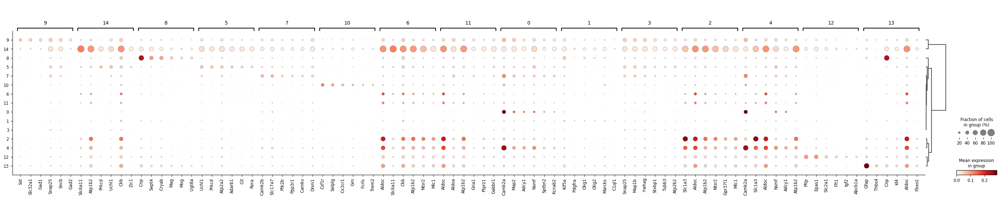

{'0': ['Camk2a', 'Map2', 'Adcy1', 'Nsmf', 'Sptbn2'], '1': ['Kif5a', 'Pdgfra', 'Olig1', 'Olig2', 'Marcks'], '10': ['Csf1r', 'Selplg', 'Cx3cr1', 'Grn', 'Fcrls'], '11': ['Aldoc', 'Aldoa', 'Atp1b2', 'Gria1', 'Ptprz1'], '12': ['Pltp', 'Epas1', 'Slc2a1', 'Flt1', 'Igf2'], '13': ['Gfap', 'Thbs4', 'Cnp', 'Id4', 'Aldoc'], '14': ['Slc6a11', 'Atp1b2', 'Prkcd', 'Uchl1', 'Ckb'], '2': ['Slc1a3', 'Aldoc', 'Atp1b2', 'Ntsr2', 'Gpr37l1'], '3': ['Snap25', 'Map1b', 'Ywhag', 'Stxbp1', 'Tubb3'], '4': ['Camk2a', 'Slc1a3', 'Aldoc', 'Nsmf', 'Adcy1'], '5': ['Uchl1', 'Prkcd', 'Atp2a2', 'Adarb1', 'Cit'], '6': ['Aldoc', 'Slc6a11', 'Ckb', 'Atp1b2', 'Ntsr2'], '7': ['Camk2b', 'Slc17a7', 'Ptk2b', 'Ppp3r1', 'Camkv'], '8': ['Cnp', 'Sept4', 'Cryab', 'Mag', 'Mog'], '9': ['Sst', 'Slc32a1', 'Gad1', 'Snap25', 'Sncb']}


In [132]:
struc2urna=dict(zip(embed_filt.obs.index,embed_filt.obs['urna_cluster']))
adata.obs['urna_cluster']=adata.obs.index.map(struc2urna)
#sc.pp.normalize_total(adata)
#sc.pp.log1p(adata)
##### 
sc.tl.rank_genes_groups(adata,groupby='urna_cluster')
sc.pl.rank_genes_groups_dotplot(adata,groupby='urna_cluster',n_genes=6)
marker_dict = {}
for cluster in sorted(adata.obs["urna_cluster"].unique()):
    df = sc.get.rank_genes_groups_df(adata, group=str(cluster))
    # Get top 3 names
    marker_dict[str(cluster)] = df["names"].head(5).tolist()

# Prints a single-line collapsed dictionary perfect for copy-pasting
print(marker_dict)

In [145]:
dict_urna_anno = {
    "0": "Neuronal Somas & Protrusions (Camk2a/Map2+)",
    "1": "Oligodendrocyte Precursor Cells / OPC Protrusions (Olig1/Pdgfra+)",
    "2": "Protoplasmic Astrocyte Core (Slc1a3/Aldoc+ High)",
    "3": "Synaptic Neuropil / Axon Dense Matrix (Snap25/Tubb3+)",
    "4": "Glial Boundary / Neuronal-Astrocyte Interface (Camk2a/Slc1a3 Mix)",
    "5": "Subcortical/Thalamic Neuronal Somas (Uchl1/Prkcd+)",
    "6": "Astroglial GABA-Metabolic Edge (Aldoc/Slc6a11/Ckb+)",
    "7": "Thalamic Glutamatergic Axon Bundles (Camk2b/Slc17a7+)",
    "8": "Myelinated White Matter Tracks (Cnp/Mog/Mag+)",
    "9": "Inhibitory Interneuron Somas / Terminals (Sst/Gad1+)",
    "10": "Microglial Processes & Myeloid Niches (Csf1r/Cx3cr1+)",
    "11": "Parenchymal Astrocyte Protrusions (Aldoc/Gria1+)",
    "12": "Blood-Brain Barrier Endothelial Vessels (Pltp/Slc2a1+)",
    "13": "Reactive Glial Scars / Pial Boundaries (Gfap/Thbs4 Extreme)",
    "14": "Subcortical GABAergic Transporter Matrix (Slc6a11/Uchl1+ Mix)",
}

embed_filt.obs['structure_annotation']=embed_filt.obs['urna_cluster'].map(dict_urna_anno)
adata.obs['structure_annotation']=adata.obs['urna_cluster'].map(dict_urna_anno)

Save all info from embed_filt in the main structure_table_object

In [146]:
# 1. Transfer the matrix and UMAP coordinates as you planned
sdata["structure_table"].obsm["X_drvi"] = embed_filt.X
sdata["structure_table"].obsm["X_umap_drvi"] = embed_filt.obsm["X_umap"]

# 2. Save the ENTIRE .var dataframe directly into .uns
# This preserves all columns, tracking perfectly with the columns of X_drvi
sdata["structure_table"].uns["drvi_var"] = embed_filt.var.copy()

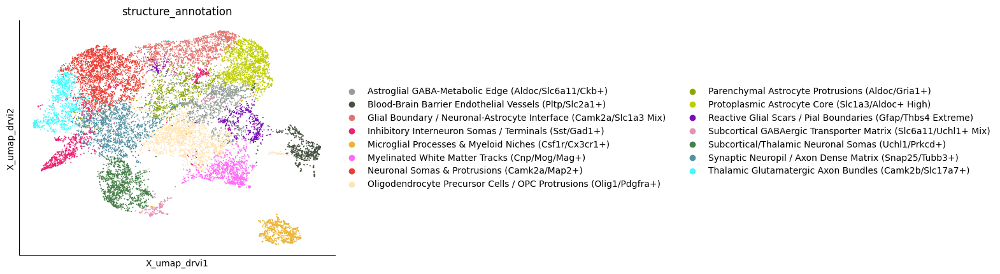

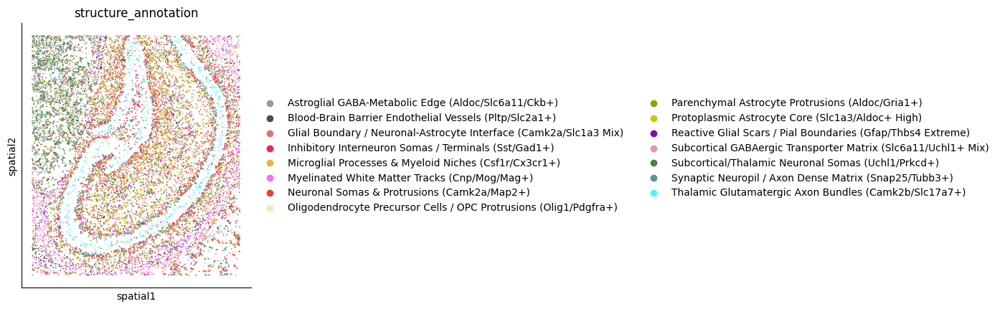

In [147]:
import scanpy as sc
del sdata["structure_table"].uns["structure_annotation_colors"]
# 1. Enforce category type
sdata["structure_table"].obs["structure_annotation"] = sdata[
    "structure_table"
].obs["structure_annotation"].astype(str)

# Updated 15-color list matching alphabetical structure order to cell type color families
structure_colors = [
    "#949E95",  # 1. Astroglial GABA-Metabolic Edge -> Muted Gray-Green (Transition zone)
    "#465240",  # 2. Blood-Brain Barrier Endothelial Vessels -> Neutral Medium Gray (Matches 'Endothelial')
    "#E2736E",  # 4. Glial Boundary / Interface -> Soft Brick Red (Neuronal blend)
    "#ED2073",  # 5. Inhibitory Interneuron Somas -> Vivid Magenta Pink (Matches 'INH neurons')
    "#ebb434",  # 6. Microglial Processes & Myeloid Niches -> Warm Gold / Yellow (Matches 'Microglia')
    "#ff69f7",  # 7. Myelinated White Matter Tracks -> Bright Pink/Orchid (Matches 'Oligodendrocytes')
    "#eb3d34",  # 3. Neuronal Somas -> Bold Tomato Red (Matches 'EXC. neurons CTX')
    "#FFE5B4",  # 8. Oligodendrocyte Precursor Cells -> Peach Slot (Matches 'OPC')
    "#8EA604",  # 9. Parenchymal Astrocyte Protrusions -> Darker Olive Green (Astrocyte variant)
    "#BFCE00",  # 10. Protoplasmic Astrocyte Core -> Chartreuse Green (Matches 'Astrocytes')
    "#790DB7",  # 11. Reactive Glial Scars / Pial Boundaries -> Royal Purple (Matches 'Choroid plexus' barrier)
    "#E891B4",  # 12. Subcortical GABAergic Transporter Matrix -> Soft Rose Pink (Matches subcortical INH CP)
    "#468048",  # 13. Subcortical/Thalamic Neuronal Somas -> Forest Green/Warm (Matches 'EXC neurons Thal.')
    "#5392A2",  # 14. Synaptic Neuropil / Axon Dense Matrix -> Deep Slate/Teal Blue (Structural grid)
    "#43FBFF",  # 15. Thalamic Glutamatergic Axon Bundles -> Neon Cyan (Matches CA3/Thalamic cable fibers)
]

# Inject directly into your structure table
sdata["structure_table"].uns["structure_annotation_colors"] = structure_colors

# 3. Inject and plot
sdata["structure_table"].uns["structure_annotation_colors"] = structure_colors

sc.pl.embedding(
    sdata["structure_table"], color="structure_annotation", basis="X_umap_drvi"
)
sc.pl.spatial(sdata["structure_table"], color="structure_annotation", spot_size=10)

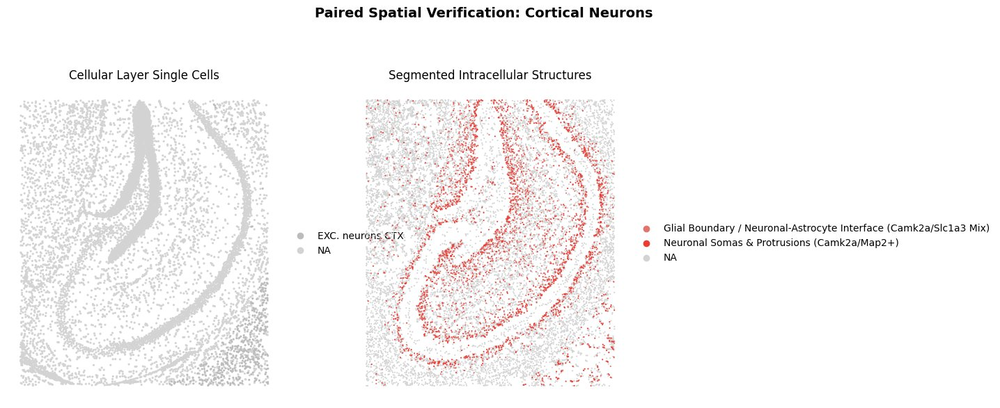

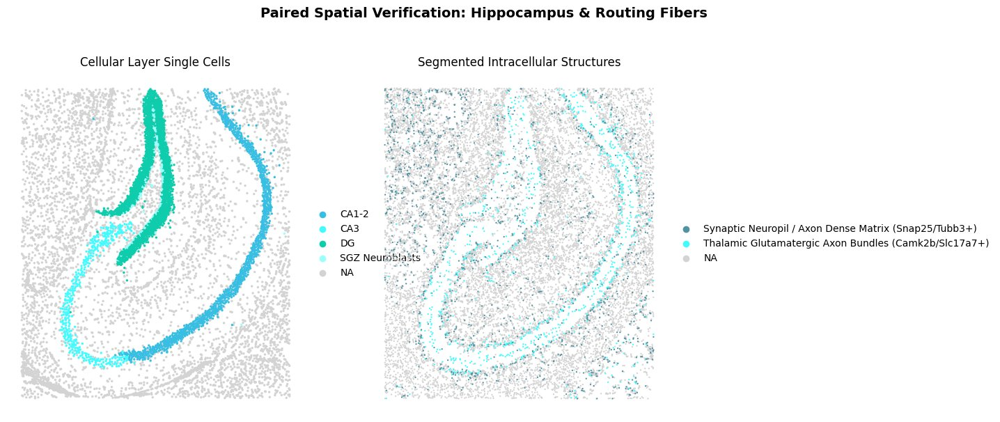

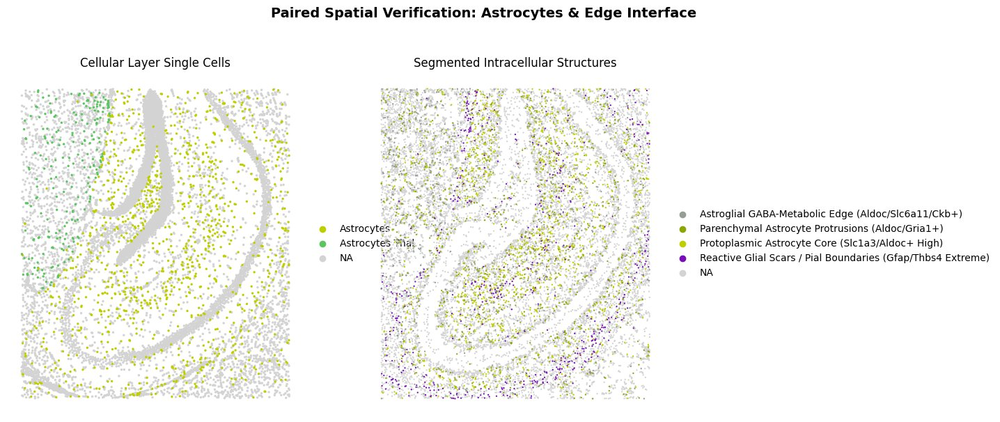

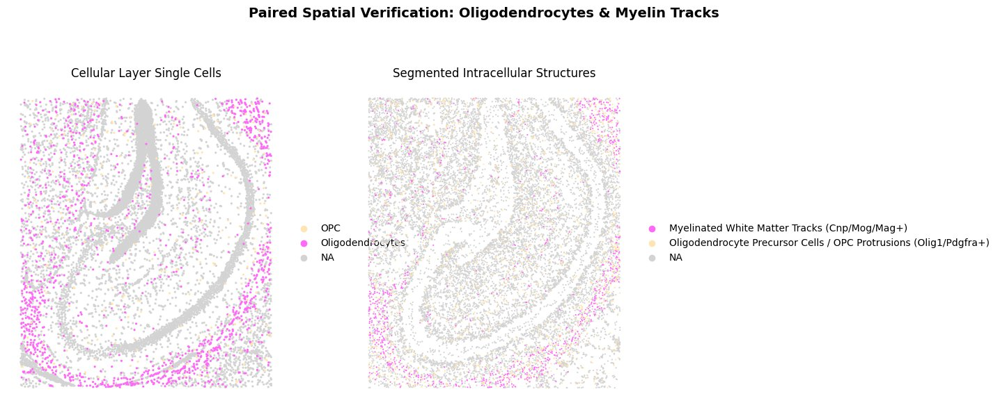

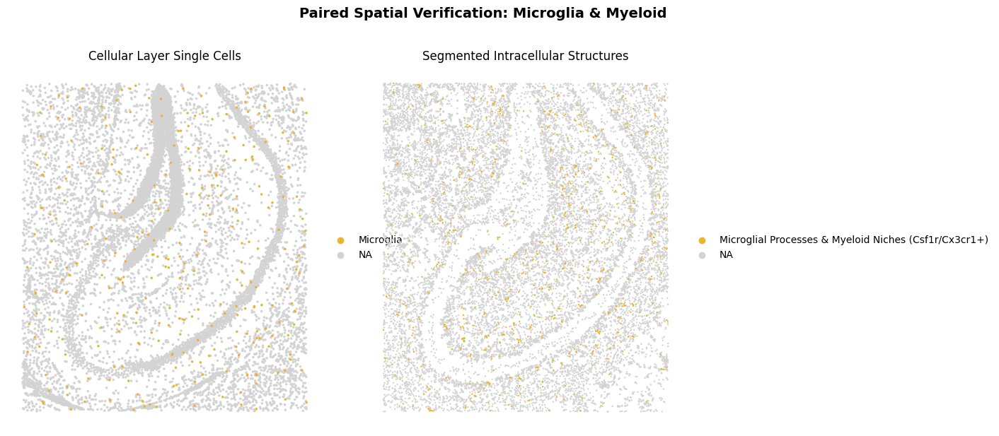

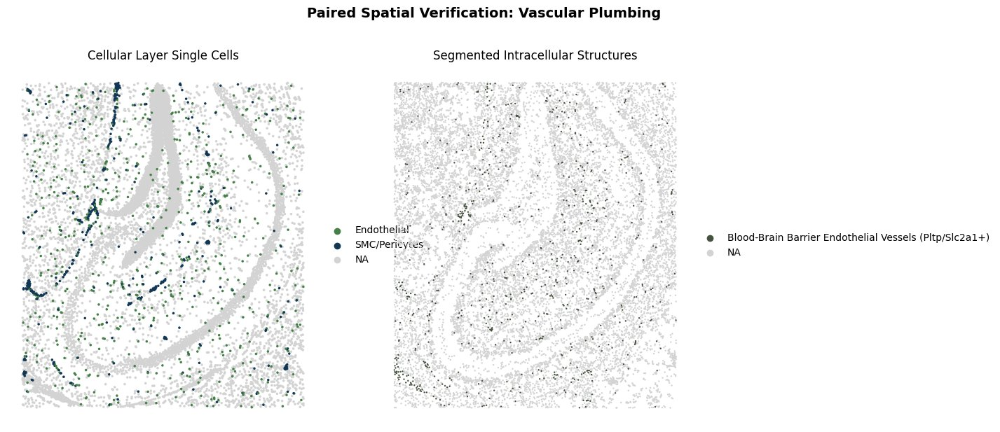

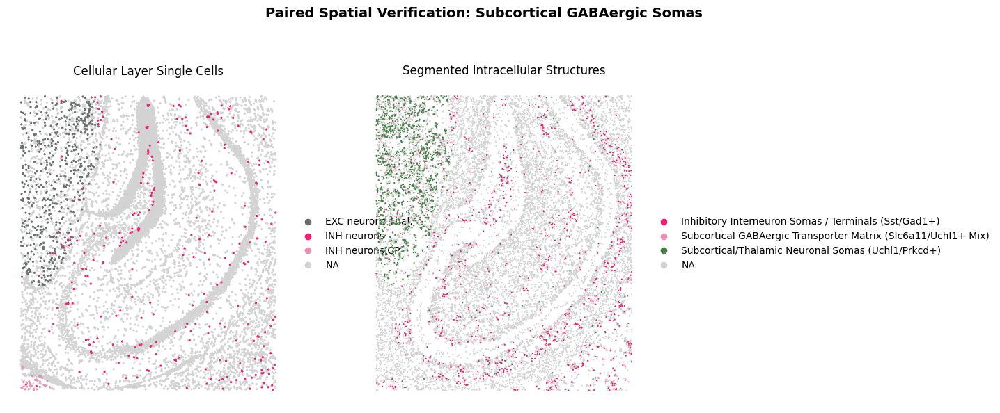


Plotting 3 leftover unpaired cell types...


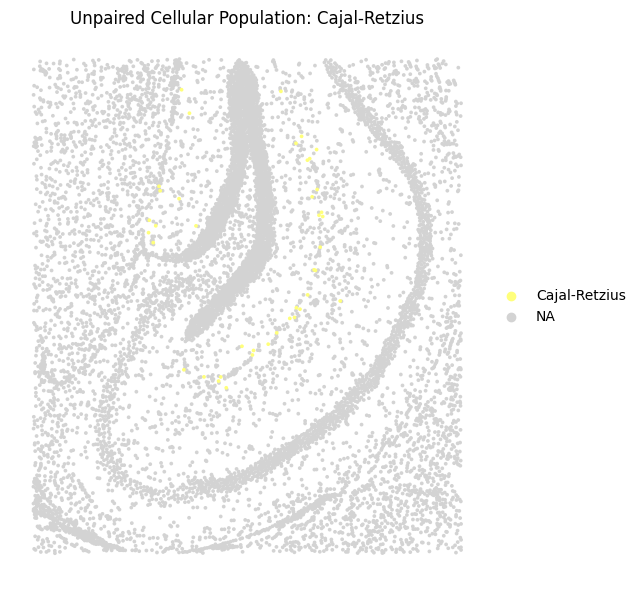

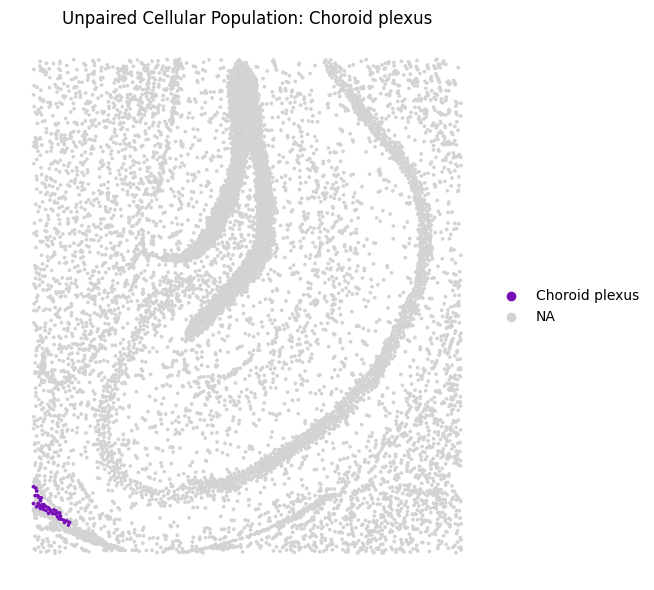

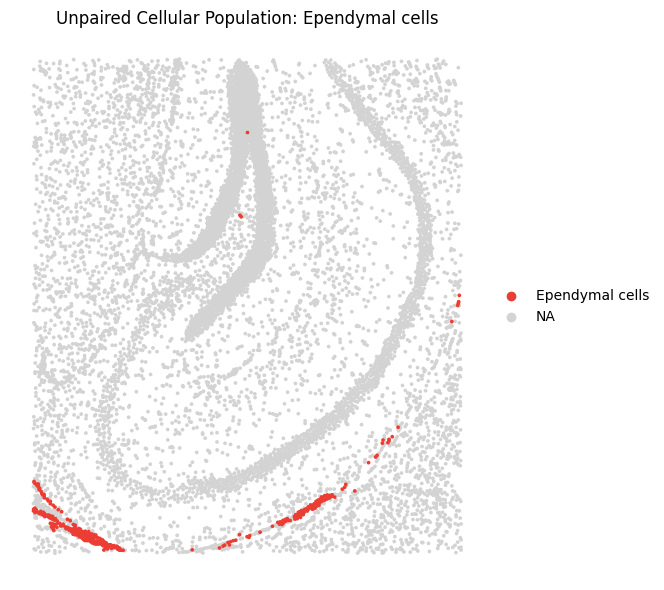

In [150]:
import matplotlib.pyplot as plt
import scanpy as sc

# 1. Ensure columns are kept as plain strings (not categories)
sdata["table"].obs["cell_type"] = sdata["table"].obs["cell_type"].astype(str)
sdata["structure_table"].obs["structure_annotation"] = (
    sdata["structure_table"].obs["structure_annotation"].astype(str)
)

# 2. Build the explicit color maps by sorting unique strings
# (This perfectly aligns the raw string entries to your preset .uns vectors)
sorted_unique_cells = sorted(sdata["table"].obs["cell_type"].unique())
cell_color_map = dict(zip(sorted_unique_cells, sdata["table"].uns["cell_type_colors"]))

sorted_unique_structures = sorted(
    sdata["structure_table"].obs["structure_annotation"].unique()
)
struct_color_map = dict(
    zip(
        sorted_unique_structures,
        sdata["structure_table"].uns["structure_annotation_colors"],
    )
)


# Helper styling function to lighten the canvas background
def apply_light_background(ax, color="#F7F7F7"):
    ax.set_facecolor(color)
    for spine in ax.spines.values():
        spine.set_color(color)


# 3. Target pairings configuration block
paired_groups = {
    "Cortical Neurons": {
        "cells": ["EXC. neurons CTX"],
        "structures": [
            "Neuronal Somas & Protrusions (Camk2a/Map2+)",
            "Glial Boundary / Neuronal-Astrocyte Interface (Camk2a/Slc1a3 Mix)",
        ],
    },
    "Hippocampus & Routing Fibers": {
        "cells": ["DG", "CA1-2", "CA3", "SGZ Neuroblasts"],
        "structures": [
            "Synaptic Neuropil / Axon Dense Matrix (Snap25/Tubb3+)",
            "Thalamic Glutamatergic Axon Bundles (Camk2b/Slc17a7+)",
        ],
    },
    "Astrocytes & Edge Interface": {
        "cells": ["Astrocytes", "Astrocytes Thal."],
        "structures": [
            "Protoplasmic Astrocyte Core (Slc1a3/Aldoc+ High)",
            "Astroglial GABA-Metabolic Edge (Aldoc/Slc6a11/Ckb+)",
            "Parenchymal Astrocyte Protrusions (Aldoc/Gria1+)",
            "Reactive Glial Scars / Pial Boundaries (Gfap/Thbs4 Extreme)",
        ],
    },
    "Oligodendrocytes & Myelin Tracks": {
        "cells": ["Oligodendrocytes", "OPC"],
        "structures": [
            "Myelinated White Matter Tracks (Cnp/Mog/Mag+)",
            "Oligodendrocyte Precursor Cells / OPC Protrusions (Olig1/Pdgfra+)",
        ],
    },
    "Microglia & Myeloid": {
        "cells": ["Microglia"],
        "structures": ["Microglial Processes & Myeloid Niches (Csf1r/Cx3cr1+)"],
    },
    "Vascular Plumbing": {
        "cells": ["Endothelial", "SMC/Pericytes"],
        "structures": ["Blood-Brain Barrier Endothelial Vessels (Pltp/Slc2a1+)"],
    },
    "Subcortical GABAergic Somas": {
        "cells": ["INH neurons", "INH neurons CP", "EXC neurons Thal."],
        "structures": [
            "Subcortical/Thalamic Neuronal Somas (Uchl1/Prkcd+)",
            "Inhibitory Interneuron Somas / Terminals (Sst/Gad1+)",
            "Subcortical GABAergic Transporter Matrix (Slc6a11/Uchl1+ Mix)",
        ],
    },
}

# --- TRACK UNPAIRED ENTRIES VIA SET DIFFERENCE ---
all_paired_cells = set(
    [c for group in paired_groups.values() for c in group["cells"]]
)
all_paired_structures = set(
    [s for group in paired_groups.values() for s in group["structures"]]
)

unpaired_cells = sorted(list(set(sorted_unique_cells) - all_paired_cells))
unpaired_structures = sorted(
    list(set(sorted_unique_structures) - all_paired_structures)
)


# --- PART A: Loop for Paired Functional Visualizations ---
for pair_name, targets in paired_groups.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(
        f"Paired Spatial Verification: {pair_name}",
        fontsize=14,
        weight="bold",
        y=1.02,
    )

    for ax in axes:
        apply_light_background(ax)

    # Left Panel: Single Cells
    sc.pl.spatial(
        sdata["table"],
        color="cell_type",
        groups=targets["cells"],
        palette=cell_color_map,
        spot_size=15,
        frameon=False,
        ax=axes[0],
        show=False,
        title="Cellular Layer Single Cells",
    )

    # Right Panel: Associated Subcellular Structural Layouts
    sc.pl.spatial(
        sdata["structure_table"],
        color="structure_annotation",
        groups=targets["structures"],
        palette=struct_color_map,
        spot_size=10,
        frameon=False,
        ax=axes[1],
        show=False,
        title="Segmented Intracellular Structures",
    )

    plt.tight_layout()
    plt.show()


# --- PART B: Plot Remaining Leftover Items Individually ---
if unpaired_cells:
    print(f"\nPlotting {len(unpaired_cells)} leftover unpaired cell types...")
    for cell in unpaired_cells:
        fig, ax = plt.subplots(figsize=(7, 6))
        apply_light_background(ax)
        sc.pl.spatial(
            sdata["table"],
            color="cell_type",
            groups=[cell],
            palette=cell_color_map,
            spot_size=15,
            frameon=False,
            ax=ax,
            show=False,
            title=f"Unpaired Cellular Population: {cell}",
        )
        plt.tight_layout()
        plt.show()

if unpaired_structures:
    print(f"\nPlotting {len(unpaired_structures)} leftover unpaired structures...")
    for struct in unpaired_structures:
        fig, ax = plt.subplots(figsize=(7, 6))
        apply_light_background(ax)
        sc.pl.spatial(
            sdata["structure_table"],
            color="structure_annotation",
            groups=[struct],
            palette=struct_color_map,
            spot_size=10,
            frameon=False,
            ax=ax,
            show=False,
            title=f"Isolated Structure Profile:\n{struct}",
        )
        plt.tight_layout()
        plt.show()

In [153]:
sdata.write(data_dir / "data_annotated_drvi_complete.zarr",overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k/data_annotated_drvi_
         complete.zarr). Please see the documentation of `is_self_contained()` to understand the implications of   
         working with SpatialData objects that are not self-contained.                                             
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k/data_annotated_drvi.
         zarr the new file path:                                                                                   
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/

# Downstream plots

In [ ]:
sdata=sd.read_zarr(data_dir / "data_annotated_drvi_complete.zarr")

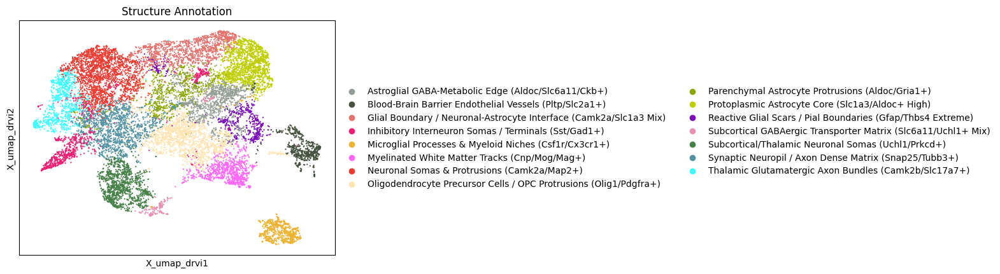

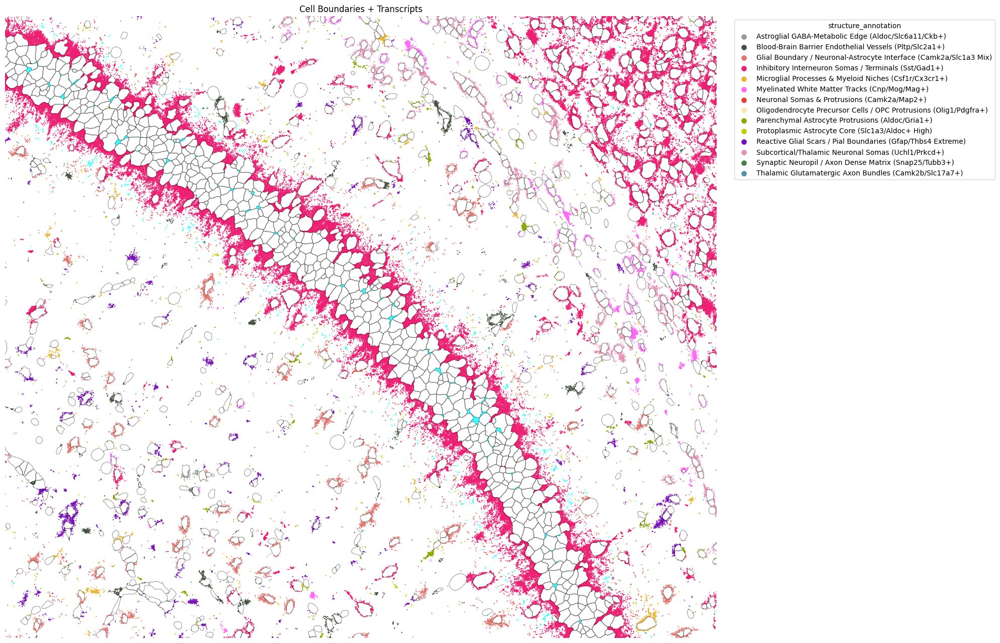

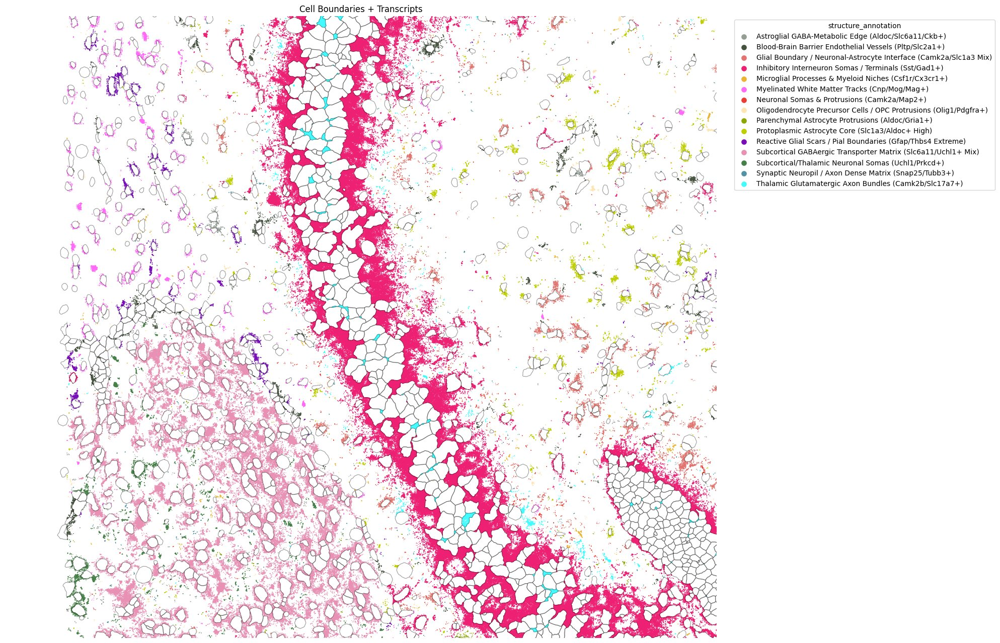

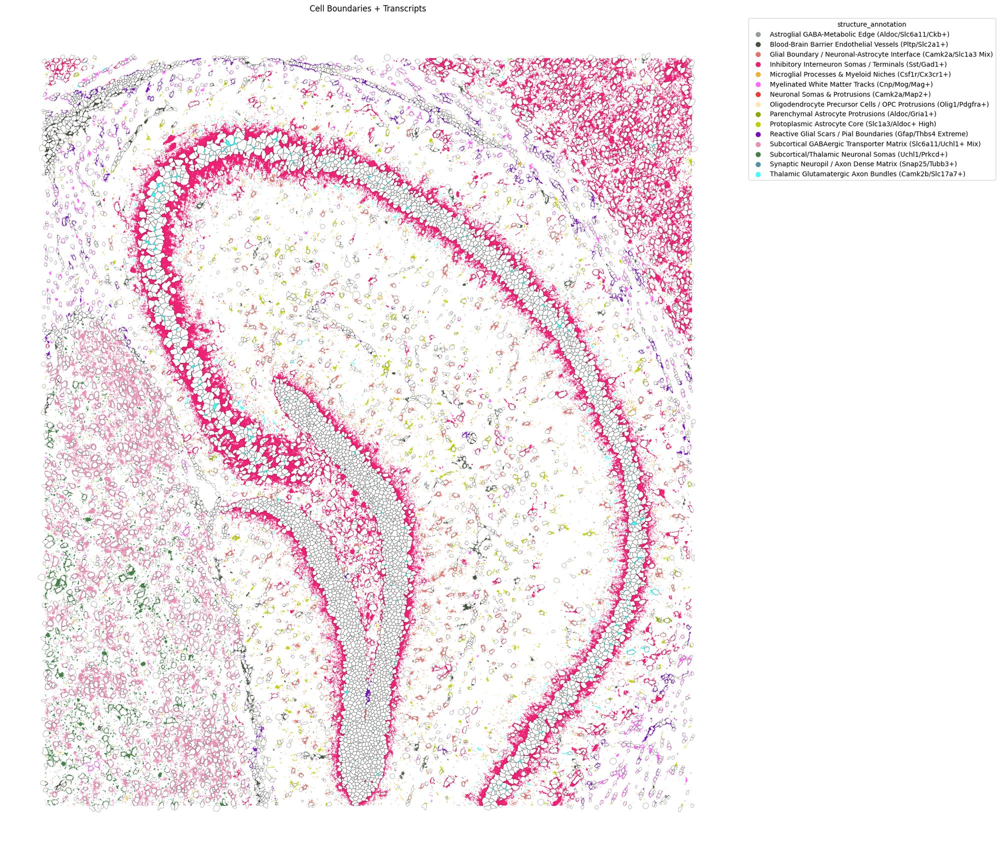

In [25]:
import matplotlib.colors as mcolors

# Run Scanpy first (this generates .uns['structure_annotation_colors'])
sc.pl.embedding(
    sdata["structure_table"],
    color="structure_annotation",
    basis="X_umap_drvi",
    s=10,
    show=True,
    title="Structure Annotation",
)

# Extract the exact colors Scanpy used
scanpy_colors = sdata["structure_table"].uns["structure_annotation_colors"]
scanpy_cmap = mcolors.ListedColormap(scanpy_colors)

sdata['structure_table'].obs['structure_annotation']=sdata['structure_table'].obs['structure_annotation'].astype(str)

# Pass this exact colormap into your spatial transcript function
fig = pl.spatial_transcripts(
    sdata,
    color_key="structure_annotation",
    colormap=scanpy_cmap,  # <--- Pass the matching Scanpy colormap here
    scatter_size=0.5,
    use_roi=True, 
    roi=(4900, 5700, 2000, 2700),
    figsize=(20,20),
    boundary_linewidth=0.8,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1)

plt.savefig(os.path.join(saving_path,'spatial_transcripts_structure_annotation_roi1.pdf'))


# Pass this exact colormap into your spatial transcript function
fig = pl.spatial_transcripts(
    sdata,
    color_key="structure_annotation",
    colormap=scanpy_cmap,  # <--- Pass the matching Scanpy colormap here
    scatter_size=0.5,
    use_roi=True, 
    roi=(4000, 4800, 1900, 2600),
    figsize=(20,20),
    boundary_linewidth=0.8,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1)

plt.savefig(os.path.join(saving_path,'spatial_transcripts_structure_annotation_roi2.pdf'))

# Pass this exact colormap into your spatial transcript function
fig = pl.spatial_transcripts(
    sdata,
    color_key="structure_annotation",
    colormap=scanpy_cmap,  # <--- Pass the matching Scanpy colormap here
    scatter_size=0.1,
    use_roi=False, 
    roi=(4000, 4800, 1900, 2600),
    figsize=(20,20),
    boundary_linewidth=0.5,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1)

plt.savefig(os.path.join(saving_path,'spatial_transcripts_structure_annotation_whole.pdf'))




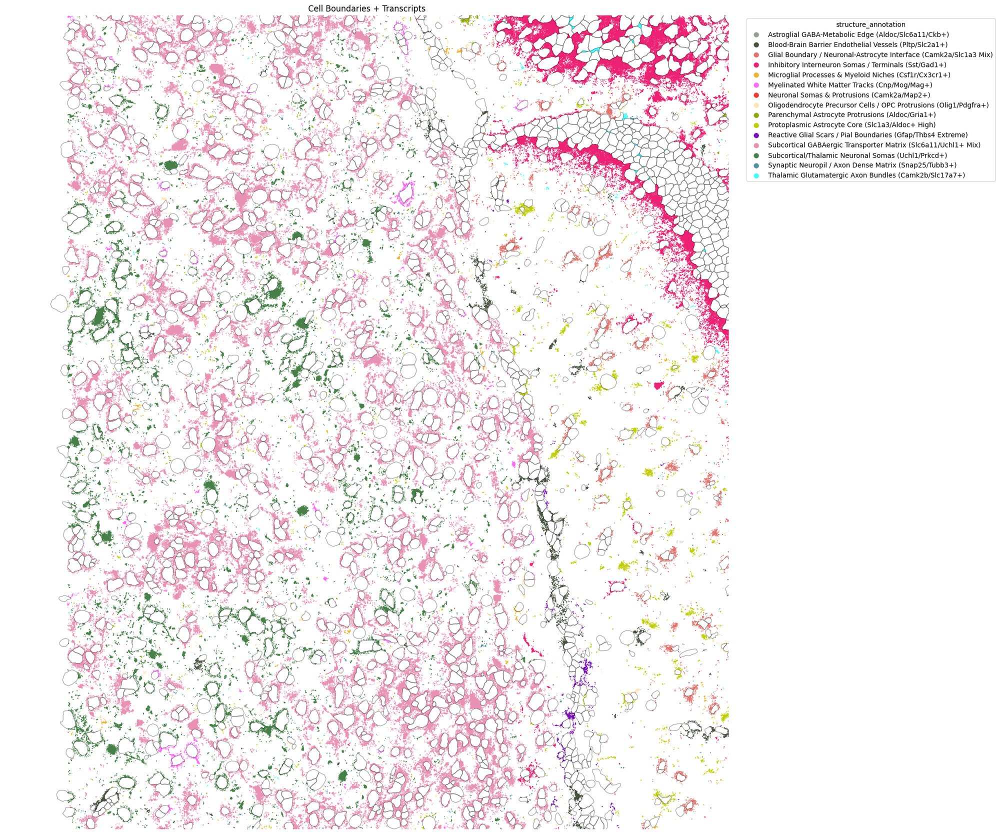

In [26]:
# Pass this exact colormap into your spatial transcript function
fig = pl.spatial_transcripts(
    sdata,
    color_key="structure_annotation",
    colormap=scanpy_cmap,  # <--- Pass the matching Scanpy colormap here
    scatter_size=0.5,
    use_roi=True, 
    roi=(4000, 4800, 1000, 1900),
    figsize=(20,20),
    boundary_linewidth=0.8,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1)

plt.savefig(os.path.join(saving_path,'spatial_transcripts_structure_annotation_roi3.pdf'))


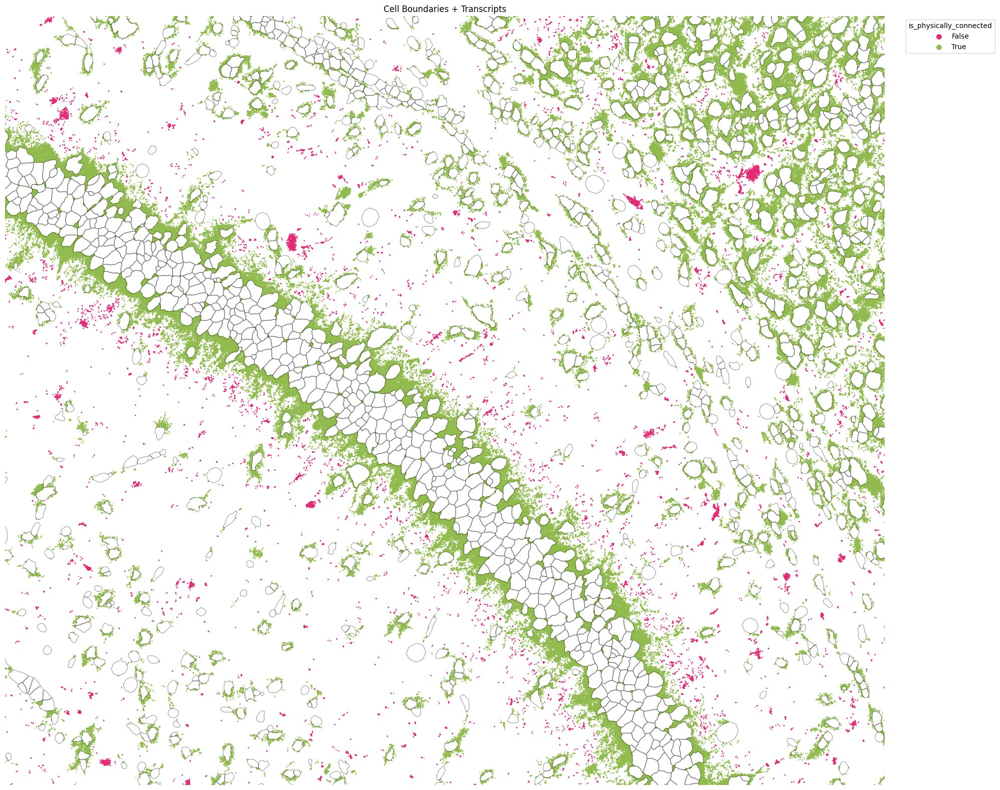

In [14]:
import matplotlib.colors as mcolors

sdata['structure_table'].obs['structure_annotation']=sdata['structure_table'].obs['structure_annotation'].astype(str)
sdata['structure_table'].obs['is_physically_connected']=sdata['structure_table'].obs['is_physically_connected'].astype(str)
colors_structures=["#e52974","#91bb4f"]
scanpy_cmap = mcolors.ListedColormap(colors_structures)
fig=pl.spatial_transcripts(
    sdata,
    color_key="is_physically_connected",
    scatter_size=1.2,use_roi=True, roi=(4900, 5700, 2100, 2800),figsize=(20,20),boundary_linewidth=0.8,
    colormap=scanpy_cmap,
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1,continuous_colormap='winter')
plt.savefig(os.path.join(saving_path,'spatial_transcripts_physically_connected_roi.pdf'))


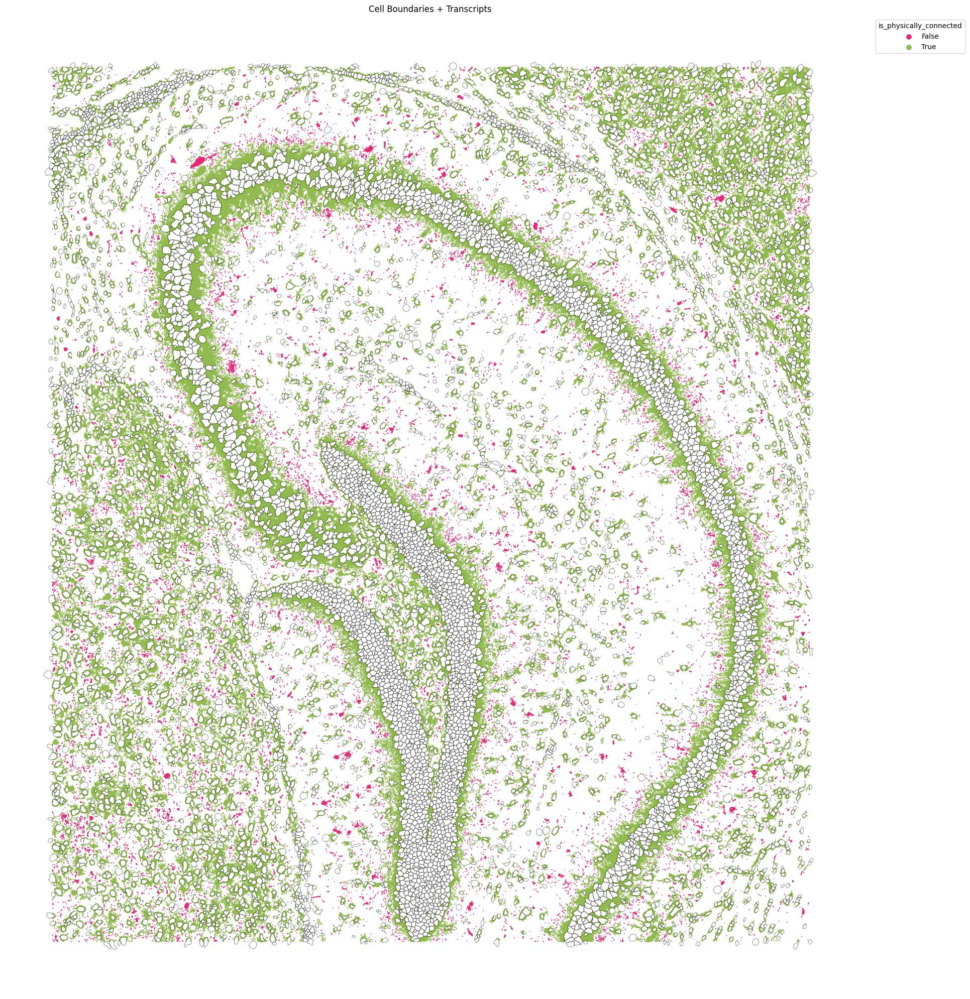

In [15]:
sdata['structure_table'].obs['structure_annotation']=sdata['structure_table'].obs['structure_annotation'].astype(str)
sdata['structure_table'].obs['is_physically_connected']=sdata['structure_table'].obs['is_physically_connected'].astype(str)
colors_structures=["#e52974","#91bb4f"]
scanpy_cmap = mcolors.ListedColormap(colors_structures)
fig=pl.spatial_transcripts(
    sdata,
    color_key="is_physically_connected",  colormap=scanpy_cmap,
    scatter_size=0.4,use_roi=False, roi=(4900, 5700, 2100, 2800),figsize=(20,20),boundary_linewidth=0.8,
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1,continuous_colormap='winter')
plt.savefig(os.path.join(saving_path,'spatial_transcripts_physically_connected.pdf'))

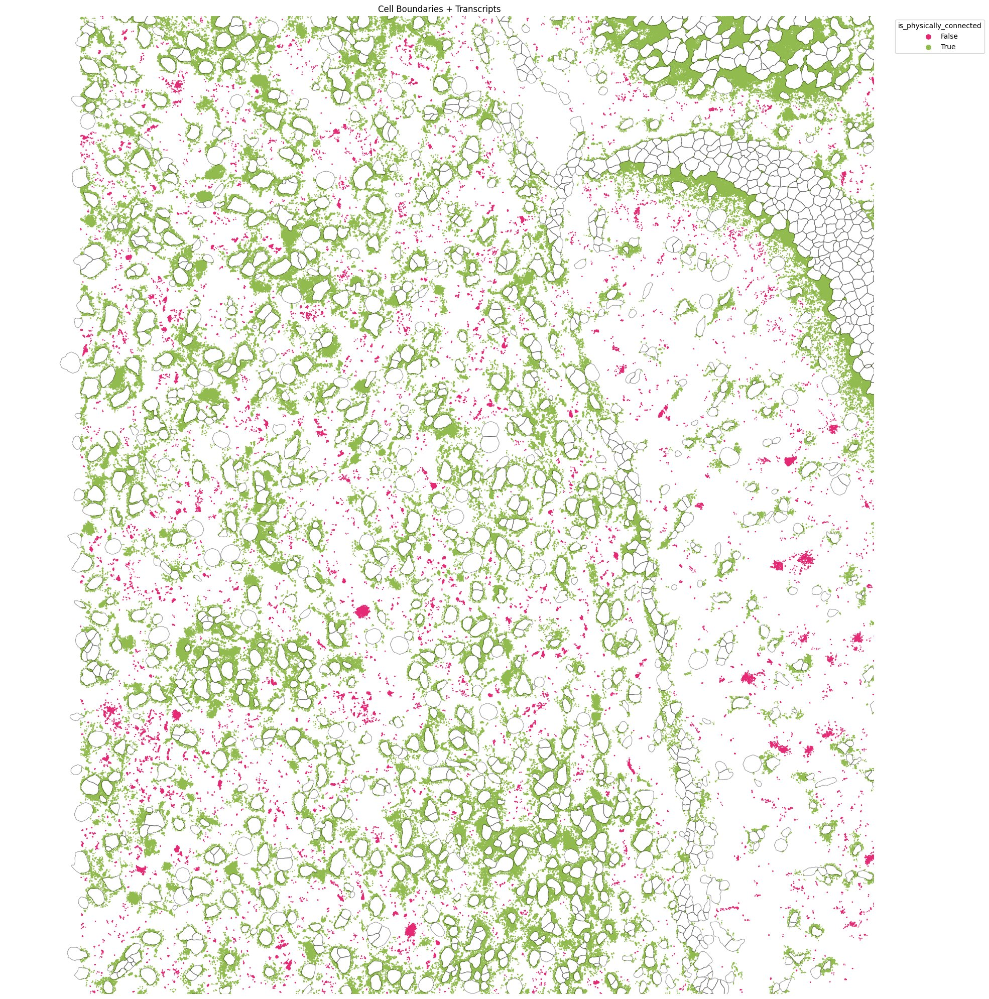

In [16]:
import matplotlib.colors as mcolors

sdata['structure_table'].obs['structure_annotation']=sdata['structure_table'].obs['structure_annotation'].astype(str)
sdata['structure_table'].obs['is_physically_connected']=sdata['structure_table'].obs['is_physically_connected'].astype(str)
colors_structures=["#e52974","#91bb4f"]
scanpy_cmap = mcolors.ListedColormap(colors_structures)
fig=pl.spatial_transcripts(
    sdata,
    color_key="is_physically_connected",
    scatter_size=1.2,use_roi=True,  roi=(4000, 4800, 1000, 1900),figsize=(20,20),boundary_linewidth=0.8,
    colormap=scanpy_cmap,
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1,continuous_colormap='winter')
plt.savefig(os.path.join(saving_path,'spatial_transcripts_physically_connected_roi_3.pdf'))


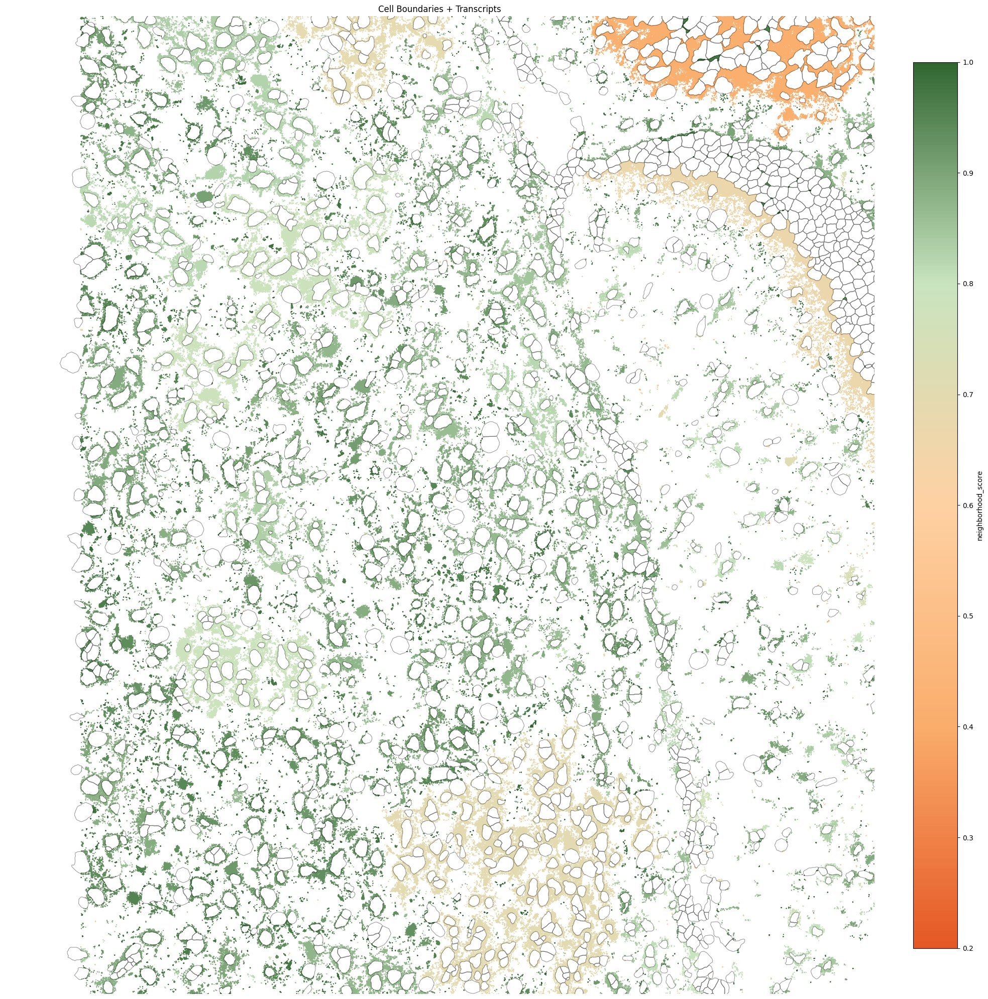

In [23]:
import matplotlib.colors as mcolors

sdata['structure_table'].obs['structure_annotation'] = sdata['structure_table'].obs['structure_annotation'].astype(str)
sdata['structure_table'].obs['is_physically_connected'] = sdata['structure_table'].obs['is_physically_connected'].astype(str)

colors_structures = ["#e55825", "#faad6c",'#fed1a3',"#c8e4bf","#316631"]
#colors_structures = ["#e55825", "#faad6c",'#fed1a3',"c8e4bf","76c376"]


# Change this line from ListedColormap to LinearSegmentedColormap
scanpy_cmap = mcolors.LinearSegmentedColormap.from_list("custom_transition", colors_structures)

fig = pl.spatial_transcripts(
    sdata,
    color_key="neighborhood_score",
    scatter_size=1.2,
    use_roi=True,  
    roi=(4000, 4800, 1000, 1900),
    figsize=(20,20),
    boundary_linewidth=0.8,
    colormap=scanpy_cmap, # This will now use the smooth gradient
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1,
    continuous_colormap='winter'
)

plt.savefig(os.path.join(saving_path,'spatial_transcripts_neighborhood_score_roi_3.pdf'))

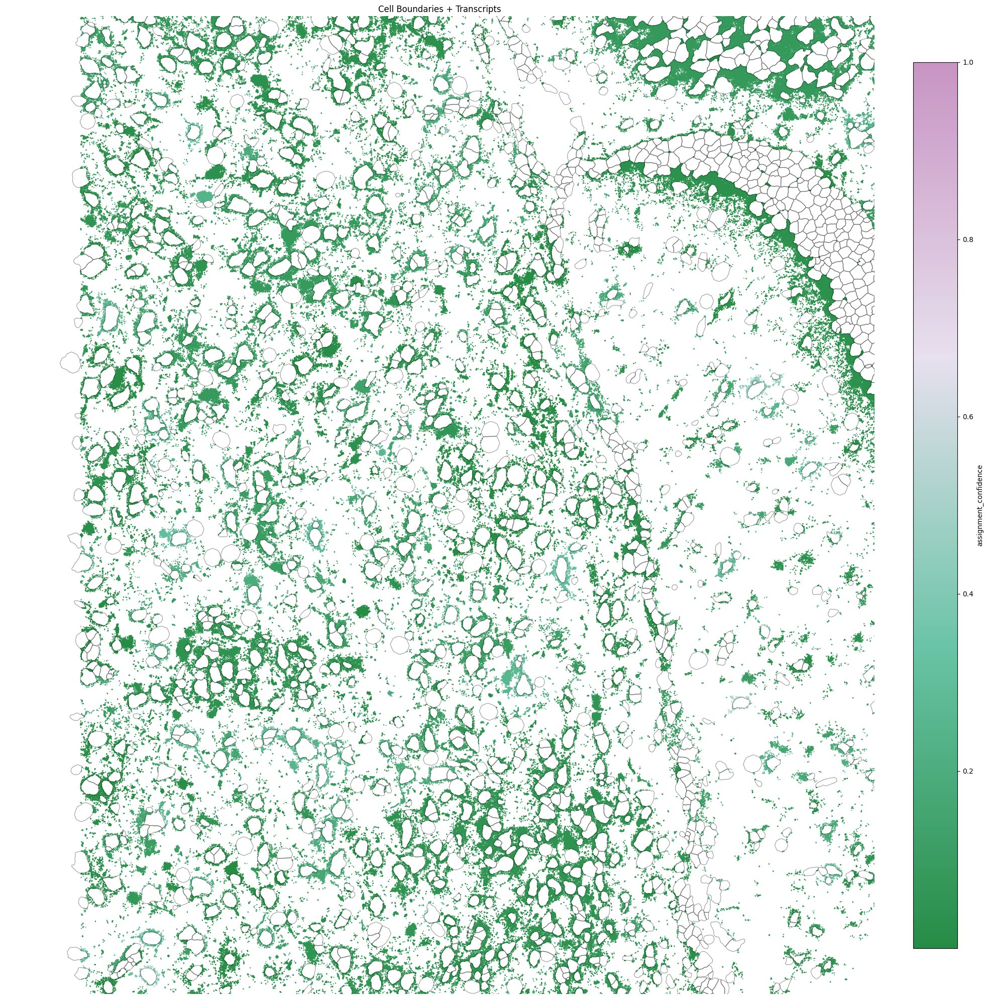

In [24]:
import matplotlib.colors as mcolors

sdata['structure_table'].obs['structure_annotation'] = sdata['structure_table'].obs['structure_annotation'].astype(str)
sdata['structure_table'].obs['is_physically_connected'] = sdata['structure_table'].obs['is_physically_connected'].astype(str)

colors_structures = ["#268c45", "#68c3a5",'#e7e0ee',"#c894c3"]
#colors_structures = ["#e55825", "#faad6c",'#fed1a3',"c8e4bf","76c376"]


# Change this line from ListedColormap to LinearSegmentedColormap
scanpy_cmap = mcolors.LinearSegmentedColormap.from_list("custom_transition", colors_structures)

fig = pl.spatial_transcripts(
    sdata,
    color_key="assignment_confidence",
    scatter_size=1.2,
    use_roi=True,  
    roi=(4000, 4800, 1000, 1900),
    figsize=(20,20),
    boundary_linewidth=0.8,
    colormap=scanpy_cmap, # This will now use the smooth gradient
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1,
    continuous_colormap='winter'
)

plt.savefig(os.path.join(saving_path,'spatial_transcripts_assignment_confidence_roi_3.pdf'))

### Find markers

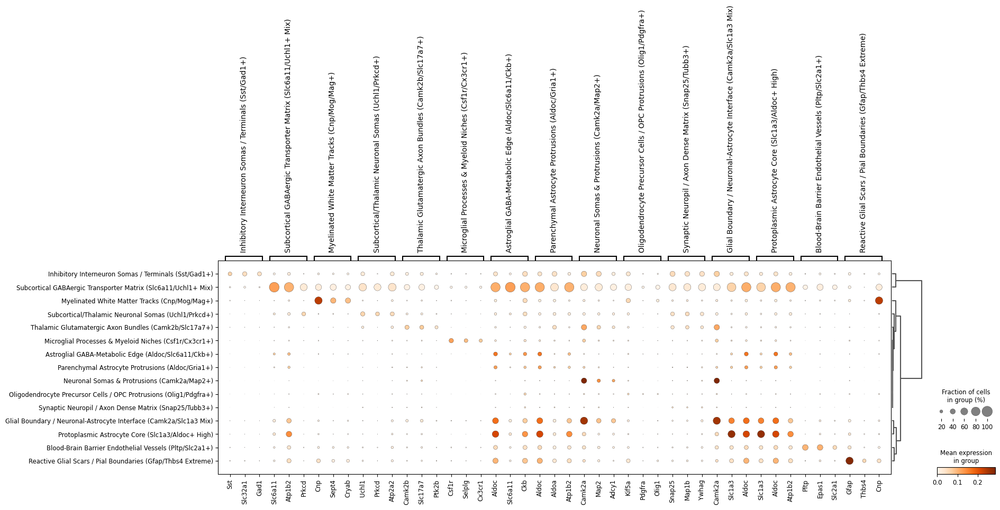

{'Astroglial GABA-Metabolic Edge (Aldoc/Slc6a11/Ckb+)': ['Aldoc', 'Slc6a11', 'Ckb', 'Atp1b2', 'Ntsr2'], 'Blood-Brain Barrier Endothelial Vessels (Pltp/Slc2a1+)': ['Pltp', 'Epas1', 'Slc2a1', 'Flt1', 'Igf2'], 'Glial Boundary / Neuronal-Astrocyte Interface (Camk2a/Slc1a3 Mix)': ['Camk2a', 'Slc1a3', 'Aldoc', 'Nsmf', 'Adcy1'], 'Inhibitory Interneuron Somas / Terminals (Sst/Gad1+)': ['Sst', 'Slc32a1', 'Gad1', 'Snap25', 'Sncb'], 'Microglial Processes & Myeloid Niches (Csf1r/Cx3cr1+)': ['Csf1r', 'Selplg', 'Cx3cr1', 'Grn', 'Fcrls'], 'Myelinated White Matter Tracks (Cnp/Mog/Mag+)': ['Cnp', 'Sept4', 'Cryab', 'Mag', 'Mog'], 'Neuronal Somas & Protrusions (Camk2a/Map2+)': ['Camk2a', 'Map2', 'Adcy1', 'Nsmf', 'Sptbn2'], 'Oligodendrocyte Precursor Cells / OPC Protrusions (Olig1/Pdgfra+)': ['Kif5a', 'Pdgfra', 'Olig1', 'Olig2', 'Marcks'], 'Parenchymal Astrocyte Protrusions (Aldoc/Gria1+)': ['Aldoc', 'Aldoa', 'Atp1b2', 'Gria1', 'Ptprz1'], 'Protoplasmic Astrocyte Core (Slc1a3/Aldoc+ High)': ['Slc1a3', 'Ald

In [65]:
adata=sdata['structure_table']

#sc.pp.normalize_total(adata)
#sc.pp.log1p(adata)
##### 

import matplotlib

# Ensure font type is set to true editable text for vector output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

sc.tl.rank_genes_groups(adata,groupby='structure_annotation')
sc.pl.rank_genes_groups_dotplot(adata,groupby='structure_annotation',n_genes=3,cmap='Oranges')
marker_dict = {}
for cluster in sorted(adata.obs["structure_annotation"].unique()):
    df = sc.get.rank_genes_groups_df(adata, group=str(cluster))
    # Get top 3 names
    marker_dict[str(cluster)] = df["names"].head(5).tolist()

# Prints a single-line collapsed dictionary perfect for copy-pasting
print(marker_dict)

In [ ]:
import matplotlib

# Ensure font type is set to true editable text for vector output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42


'predicted_parent_cell_type'

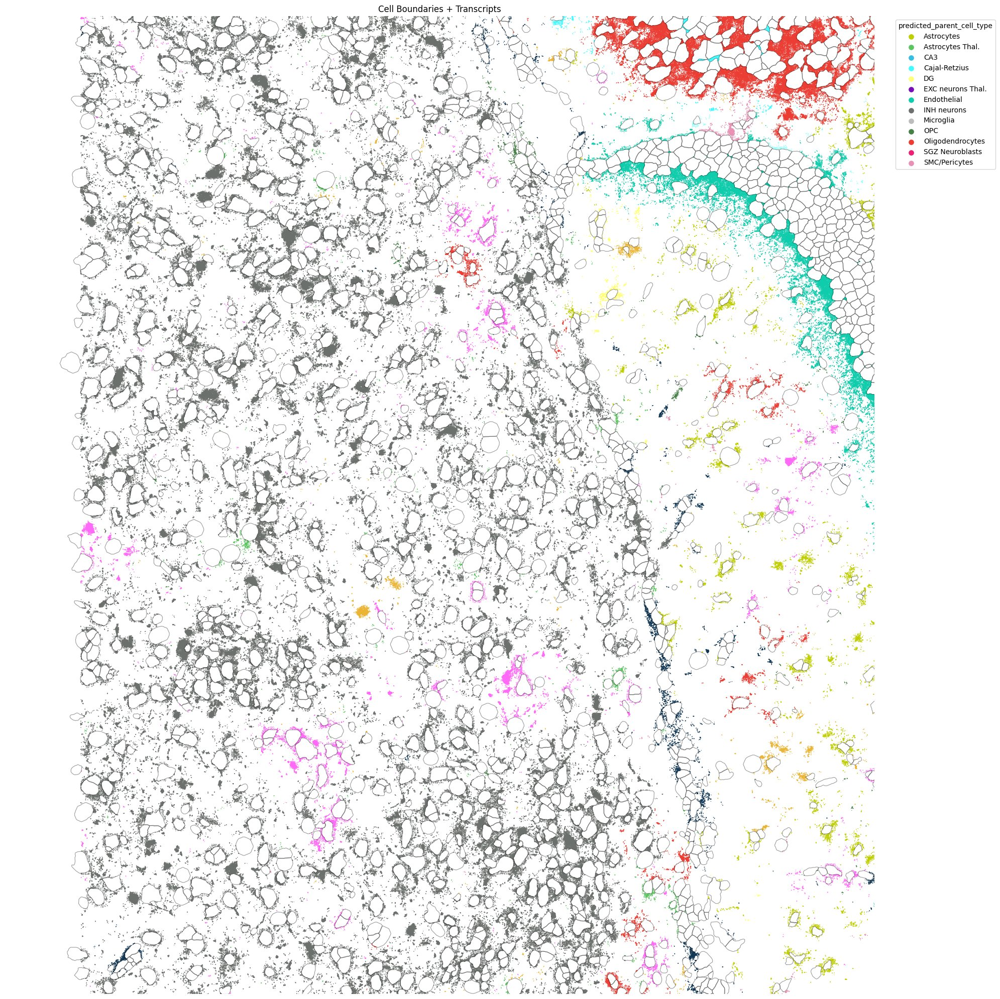

In [38]:
id2ct=dict(zip(sdata['table'].obs.index,sdata['table'].obs['cell_type']))
sdata['structure_table'].obs['predicted_parent_cell_type']=sdata['structure_table'].obs['predicted_parent'].map(id2ct)

import matplotlib.colors as mcolors

# Extract the exact colors Scanpy used
scanpy_colors = sdata["table"].uns["cell_type_colors"]
scanpy_cmap = mcolors.ListedColormap(scanpy_colors)

# Pass this exact colormap into your spatial transcript function
fig = pl.spatial_transcripts(
    sdata,
    color_key="predicted_parent_cell_type",
    colormap=scanpy_cmap,  # <--- Pass the matching Scanpy colormap here
    scatter_size=0.5,
    use_roi=True, 
    roi=(4000, 4800, 1000, 1900),
    figsize=(20,20),
    boundary_linewidth=0.8,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1)

plt.savefig(os.path.join(saving_path,'spatial_predicted_cell_type_annotation_roi3.pdf'))

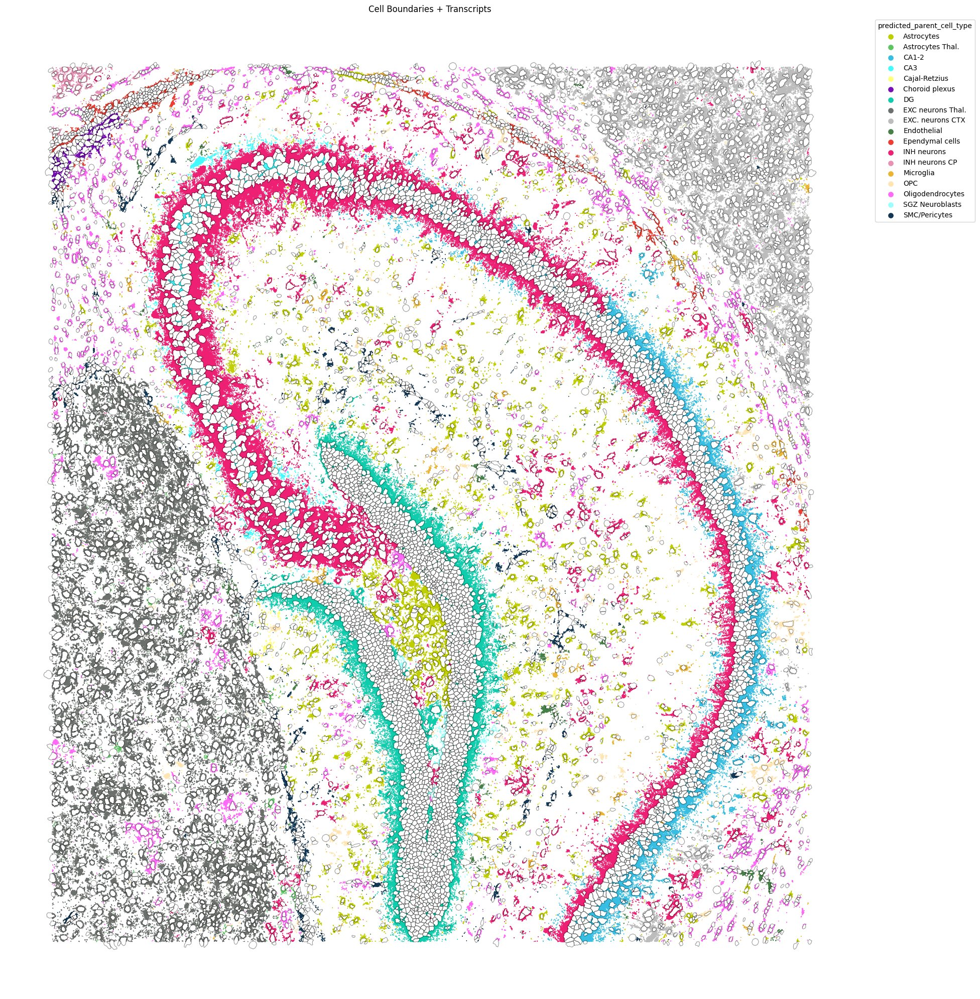

In [39]:
id2ct=dict(zip(sdata['table'].obs.index,sdata['table'].obs['cell_type']))
sdata['structure_table'].obs['predicted_parent_cell_type']=sdata['structure_table'].obs['predicted_parent'].map(id2ct)

import matplotlib.colors as mcolors

# Extract the exact colors Scanpy used
scanpy_colors = sdata["table"].uns["cell_type_colors"]
scanpy_cmap = mcolors.ListedColormap(scanpy_colors)

# Pass this exact colormap into your spatial transcript function
fig = pl.spatial_transcripts(
    sdata,
    color_key="predicted_parent_cell_type",
    colormap=scanpy_cmap,  # <--- Pass the matching Scanpy colormap here
    scatter_size=0.5,
    use_roi=False, 
    roi=(4000, 4800, 1000, 1900),
    figsize=(20,20),
    boundary_linewidth=0.8,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1)

plt.savefig(os.path.join(saving_path,'spatial_predicted_cell_type_annotation_full.pdf'))

In [40]:
import pandas as pd
import matplotlib.colors as mcolors

# 1. Fetch the absolute global list of cell types from your main table
global_cell_types = sorted(sdata["table"].obs["cell_type"].unique().tolist())

# 2. Perform your mapping for the structure table
id2ct = dict(zip(sdata['table'].obs.index, sdata['table'].obs['cell_type']))
sdata['structure_table'].obs['predicted_parent_cell_type'] = sdata['structure_table'].obs['predicted_parent'].map(id2ct)

# 3. Create a UNIFIED column name present in both tables
unified_col = "unified_cell_type"

# 4. Enforce identical Categorical types on both tables with global_cell_types
sdata['table'].obs[unified_col] = pd.Categorical(
    sdata['table'].obs['cell_type'], 
    categories=global_cell_types
)

sdata['structure_table'].obs[unified_col] = pd.Categorical(
    sdata['structure_table'].obs['predicted_parent_cell_type'], 
    categories=global_cell_types
)

In [41]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize
from shapely.geometry import box
from shapely.affinity import affine_transform

def spatial_transcripts(
    sdata,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "point_source_cellular",
    shapes_key: str = "cell_boundaries",
    table_key: str = "table",
    structure_table_key: str = "structure_table",
    source_table_key: str = "source_score",
    colormap: str = "30colors",
    continuous_colormap: str = "viridis",
    boundary_linewidth: float = 0.5,
    boundary_zorder: int = 4,
    scatter_size: float = 1.0,
    alpha: float = 0.8,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
    vmin: float | None = None,
    vmax: float | None = None,
    rasterize: bool = True,
    missing_val_sentinel: int | str | float = -1,
) -> tuple[plt.Figure, plt.Axes]:
    
    target_col = "point_source" if color_key == "point_source_cellular" else color_key
    required_cols = ["x", "y", gene_key, "overlaps_cell"]

    transcripts_lazy = sdata.points["transcripts"]
    is_direct_column = target_col in transcripts_lazy.columns

    if is_direct_column:
        required_cols.append(target_col)

    # Base configuration mapping
    search_configs = [
        (source_table_key, None),
        (structure_table_key, "structure_id"),
        (table_key, "cell_id"),
    ]

    # Dynamically include ID columns if they exist
    for t_key, trans_id_col in search_configs:
        if t_key in sdata.tables and trans_id_col is not None:
            required_cols.append(trans_id_col)

    required_cols = list(set(required_cols))
    available_cols = [c for c in required_cols if c in transcripts_lazy.columns]
    transcripts_lazy_subset = transcripts_lazy[available_cols]

    if gene_list is not None:
        transcripts_lazy_subset = transcripts_lazy_subset[transcripts_lazy_subset[gene_key].isin(gene_list)]

    trans_ad = transcripts_lazy_subset.compute().copy()

    if color_key not in trans_ad.columns:
        trans_ad[color_key] = np.nan

    # --- MODIFIED: COMBINED MAPPING STRATEGY ---
    # Instead of breaking early at the first matching table, we look up mapping maps
    # across both structure_table AND table_key, combining them seamlessly.
    if color_key != "point_source_cellular" and not is_direct_column:
        combined_series = pd.Series(index=trans_ad.index, dtype=object)
        
        # 1. Look up annotations from the Structure Table via structure_id
        if structure_table_key in sdata.tables and "structure_id" in trans_ad.columns:
            struct_obs = sdata[structure_table_key].obs
            if target_col in struct_obs.columns:
                if "instance_id" in struct_obs.columns:
                    map_source = struct_obs.set_index("instance_id")[target_col]
                elif "cell_id" in struct_obs.columns:
                    map_source = struct_obs.set_index("cell_id")[target_col]
                else:
                    map_source = struct_obs[target_col]
                map_source.index = map_source.index.astype(str)
                
                # Assign structure-based parent annotations
                struct_mapped = trans_ad["structure_id"].astype(str).map(map_source)
                combined_series = combined_series.fillna(struct_mapped)

        # 2. Look up annotations from the Cellular Table via cell_id
        if table_key in sdata.tables and "cell_id" in trans_ad.columns:
            cell_obs = sdata[table_key].obs
            # Fallback: if user looks for predicted_parent_cell_type but main table has 'cell_type'
            cell_target_col = 'cell_type' if (target_col == 'predicted_parent_cell_type' and 'cell_type' in cell_obs.columns) else target_col
            
            if cell_target_col in cell_obs.columns:
                if "cell_id" in cell_obs.columns:
                    map_source = cell_obs.set_index("cell_id")[cell_target_col]
                else:
                    map_source = cell_obs[cell_target_col]
                map_source.index = map_source.index.astype(str)
                
                # Assign intracellular annotations where structure didn't cover
                cell_mapped = trans_ad["cell_id"].astype(str).map(map_source)
                combined_series = combined_series.fillna(cell_mapped)

        trans_ad[color_key] = combined_series

    # Legacy handling for standard point_source_cellular tracking
    elif color_key == "point_source_cellular":
        if target_col not in trans_ad.columns:
            trans_ad[target_col] = np.nan
            for t_key, trans_id_col in search_configs:
                if t_key in sdata.tables and target_col in sdata[t_key].obs.columns:
                    table_obs = sdata[t_key].obs
                    if trans_id_col is None:
                        table_series = table_obs[target_col]
                        table_series.index = table_series.index.astype(str)
                        trans_ad[target_col] = trans_ad.index.astype(str).map(table_series)
                    else:
                        if "instance_id" in table_obs.columns:
                            map_source = table_obs.set_index("instance_id")[target_col]
                        elif "cell_id" in table_obs.columns:
                            map_source = table_obs.set_index("cell_id")[target_col]
                        else:
                            map_source = table_obs[target_col]
                        map_source.index = map_source.index.astype(str)
                        trans_ad[target_col] = trans_ad[trans_id_col].astype(str).map(map_source)
                    if not trans_ad[target_col].isna().all():
                        break
        is_intra_bool = trans_ad["overlaps_cell"].astype(str).str.lower() == "true"
        trans_ad["point_source_cellular"] = np.where(is_intra_bool, "cellular transcripts", trans_ad[target_col].astype(str))
        trans_ad.loc[trans_ad[target_col].isna(), "point_source_cellular"] = np.nan

    # Standard clean up of missing markers
    trans_ad[color_key] = trans_ad[color_key].replace("nan", np.nan)
    if missing_val_sentinel is not None:
        sentinel_str = str(missing_val_sentinel)
        trans_ad[color_key] = trans_ad[color_key].replace([missing_val_sentinel, sentinel_str], np.nan)

    is_nan_mask = trans_ad[color_key].isna()
    trans_ad[color_key] = trans_ad[color_key].fillna("Unmapped")
    is_bg = trans_ad[color_key] == "Unmapped"
    trans_df = trans_ad.copy()

    # Geometry generation & transformation Handling
    cb = sdata[shapes_key]
    df = cb.copy()
    try:
        from spatialdata import get_transformation
        trans = get_transformation(cb)
        if hasattr(trans, "matrix") and trans.matrix is not None:
            m = trans.matrix
            params = [m[0, 0], m[0, 1], m[1, 0], m[1, 1], m[0, 2], m[1, 2]]
            df["geometry"] = df["geometry"].apply(lambda g: affine_transform(g, params))
    except Exception:
        pass
    gdf = gpd.GeoDataFrame(df, geometry="geometry")

    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        is_bg = is_bg[mask]
        is_nan_mask = is_nan_mask[mask]

    fg_df = trans_df[~is_bg].copy()
    unmapped_df = trans_df[is_bg & ~is_nan_mask].copy()

    cmap, norm, is_numeric, cats = None, None, False, None

    if not fg_df.empty:
        numeric_check = pd.to_numeric(fg_df[color_key], errors="coerce")
        if not numeric_check.isna().all() and pd.api.types.is_numeric_dtype(numeric_check):
            is_numeric = True
            vals = fg_df[color_key].astype(float)
            try:
                cmap = plt.get_cmap(colormap)
            except ValueError:
                cmap = plt.get_cmap(continuous_colormap)
            plot_vmin = vmin if vmin is not None else vals.min()
            plot_vmax = vmax if vmax is not None else (1.0 if vals.max() <= 1.0 else vals.max())
            norm = Normalize(vmin=plot_vmin, vmax=plot_vmax)
        else:
            is_numeric = False

            if color_key == "point_source_cellular":
                defined_order = ["cellular transcripts", "cell_like_source", "other", "high_density_source"]
                present_cats = [c for c in defined_order if c in fg_df[color_key].unique()]
                extra_cats = [c for c in fg_df[color_key].unique() if c not in defined_order]
                final_order = present_cats + extra_cats
                fg_df[color_key] = pd.Categorical(fg_df[color_key], categories=final_order, ordered=True)
                cats = fg_df[color_key].cat.categories
            else:
                # --- MODIFIED: GLOBAL CATEGORIES FIX ---
                # Pull global categories from the main table uns colors matching structure to avoid color-shifts in ROI
                if table_key in sdata.tables and "cell_type" in sdata[table_key].obs.columns:
                    global_order = sorted(sdata[table_key].obs["cell_type"].unique().tolist())
                    fg_df[color_key] = pd.Categorical(fg_df[color_key], categories=global_order)
                else:
                    fg_df[color_key] = fg_df[color_key].astype("category")
                
                cats = fg_df[color_key].cat.categories

            if isinstance(colormap, ListedColormap):
                cmap = colormap
            else:
                try:
                    from troutpy.pl import get_palette
                    pal = get_palette(colormap, len(cats))
                    cmap = ListedColormap(pal)
                except (ValueError, ImportError):
                    cmap = plt.get_cmap(colormap if colormap in plt.colormaps() else "tab20", len(cats))

    fig, ax = plt.subplots(figsize=figsize)
    gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=boundary_linewidth, alpha=0.4, zorder=boundary_zorder)

    if not unmapped_df.empty:
        ax.scatter(unmapped_df["x"], unmapped_df["y"], c="#A0A0A0", s=scatter_size, edgecolor="none", alpha=alpha, zorder=2, rasterized=rasterize)

    if not fg_df.empty:
        c_vals = fg_df[color_key] if is_numeric else fg_df[color_key].cat.codes
        scatter = ax.scatter(
            fg_df["x"],
            fg_df["y"],
            c=c_vals,
            cmap=cmap,
            norm=norm if is_numeric else None,
            s=scatter_size * 1.5,
            edgecolor="none",
            alpha=1.0,
            zorder=3,
            rasterized=rasterize,
        )
        if is_numeric:
            fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
        else:
            # Only display categories actually present in the ROI inside the legend
            visible_cats = fg_df[color_key].dropna().unique()
            for idx, cat in enumerate(cats):
                if cat in visible_cats:
                    ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
            ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax

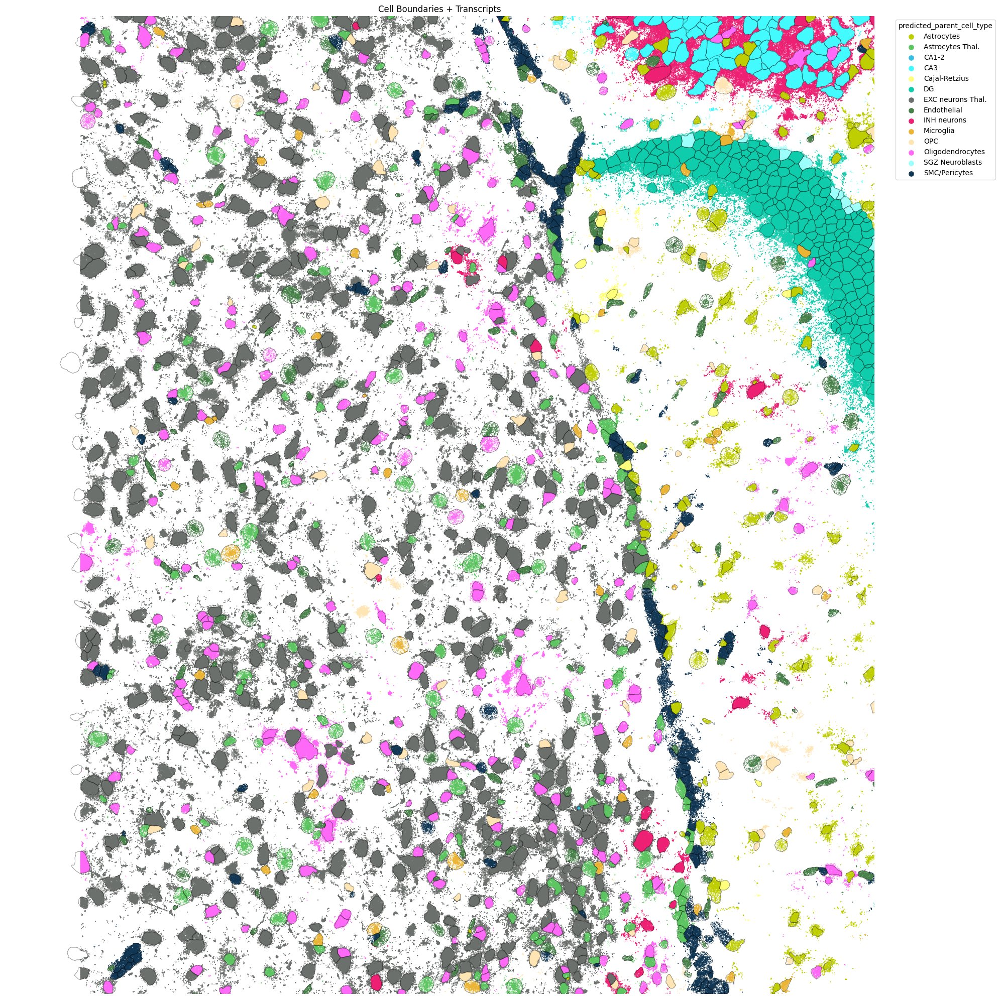

In [44]:
import matplotlib.colors as mcolors

# 1. Grab your original global scanpy colors
scanpy_colors = sdata["table"].uns["cell_type_colors"]
scanpy_cmap = mcolors.ListedColormap(scanpy_colors)

# 2. Call your newly updated function
# It will now combine the tables and map colors flawlessly!
fig, ax = spatial_transcripts(
    sdata,
    color_key="predicted_parent_cell_type",  
    colormap=scanpy_cmap,                    # Pass the standard ListedColormap directly
    scatter_size=0.5,
    use_roi=True, 
    roi=(4000, 4800, 1000, 1900),
    figsize=(20, 20),
    boundary_linewidth=0.8,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1
)
plt.savefig(os.path.join(saving_path, 'spatial_combined_cell_type_annotation_roi3.pdf'))

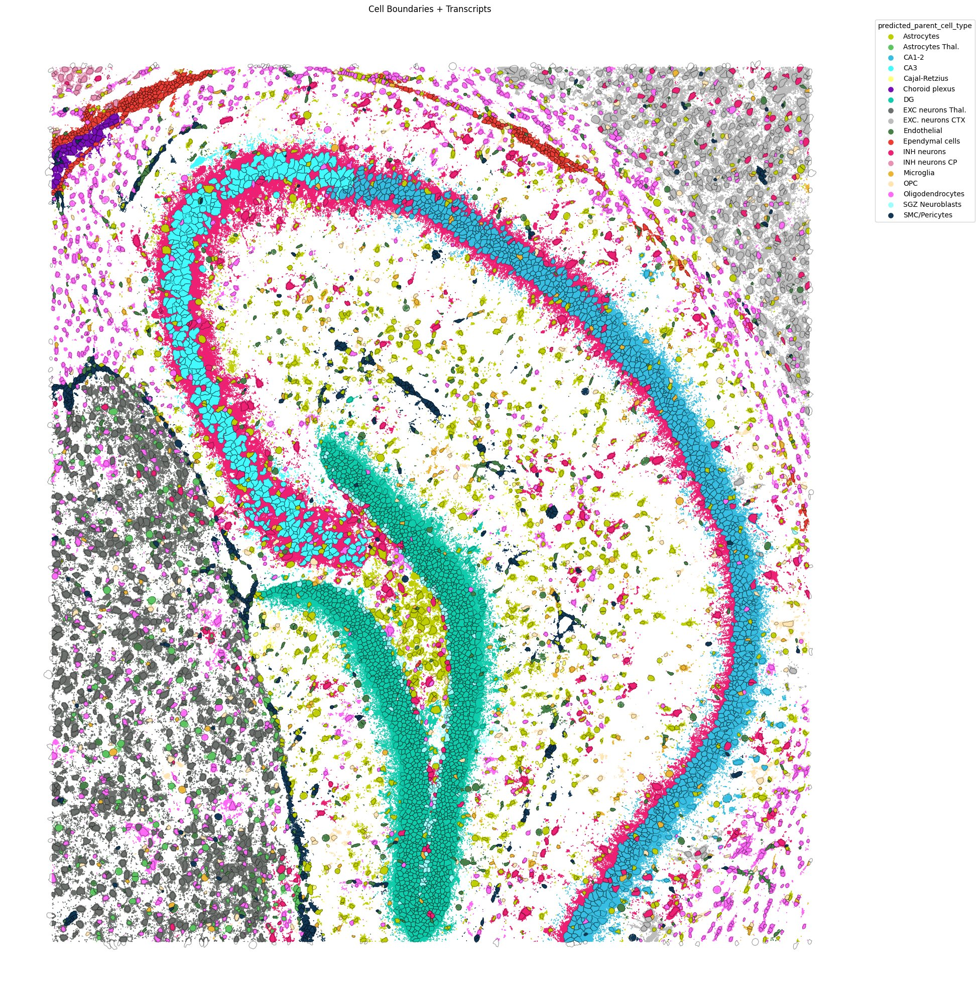

In [45]:
import matplotlib.colors as mcolors

# 1. Grab your original global scanpy colors
scanpy_colors = sdata["table"].uns["cell_type_colors"]
scanpy_cmap = mcolors.ListedColormap(scanpy_colors)

# 2. Call your newly updated function
# It will now combine the tables and map colors flawlessly!
fig, ax = spatial_transcripts(
    sdata,
    color_key="predicted_parent_cell_type",  
    colormap=scanpy_cmap,                    # Pass the standard ListedColormap directly
    scatter_size=0.5,
    use_roi=False, 
    roi=(4000, 4800, 1000, 1900),
    figsize=(20, 20),
    boundary_linewidth=0.8,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1
)
plt.savefig(os.path.join(saving_path, 'spatial_combined_cell_type_annotation_full.pdf'))

# Recompute parent score

In [46]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.spatial import KDTree
from tqdm import tqdm

def recompute_parent_assignments(
    sdata,
    table_name: str = "structure_table",
    cell_table_name: str = "table",
    global_distance: float = 500.0,
    n_neighbors: int = 50,
    lmbda: float = 0.01,
    connectivity_bonus: float = 1.2,
    copy: bool = False,
):
    """Recompute parent cell assignment metrics for existing extracellular structures.

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        SpatialData object containing the existing structure table and the cell-level table.
    table_name : str, optional
        Key of the structure table in ``sdata.tables`` to be updated. 
        Defaults to ``"structure_table"``.
    cell_table_name : str, optional
        Key of the cell-level table in ``sdata`` containing spatial coordinates.
        Defaults to ``"table"``.
    global_distance : float, optional
        Maximum distance for a cell to be considered a neighbor of a structure when
        computing parent and neighborhood scores. Defaults to ``500.0``.
    n_neighbors : int, optional
        Number of nearby cells to consider per structure for parent assignment.
        Defaults to ``50``.
    lmbda : float, optional
        Exponential decay rate applied to structure-to-cell distance when scoring
        candidate parent cells. Defaults to ``0.01``.
    connectivity_bonus : float, optional
        Score multiplier applied if a structure is physically connected to a cell.
        Defaults to ``1.2``.
    copy : bool, optional
        If ``True``, return a copy of the SpatialData object; otherwise modify
        ``sdata`` in place and return ``None``. Defaults to ``False``.

    Returns
    -------
    spatialdata.SpatialData or None
        Modified ``sdata`` if ``copy=True``; otherwise updates the tables in place 
        and returns ``None``.
    """
    if copy:
        # Safely copy the spatialdata container structure if requested
        sdata = sdata.copy() if hasattr(sdata, "copy") else sdata

    # Step 1: Extract required data tables
    if table_name not in sdata.tables:
        raise KeyError(f"Structure table '{table_name}' not found in sdata.tables.")
        
    # Standard spatialdata interface lookup fallback
    cells = sdata[cell_table_name] if cell_table_name in sdata else sdata.tables[cell_table_name]
    adata_struct = sdata.tables[table_name]

    if "spatial" not in cells.obsm:
        raise ValueError(f"Cell table '{cell_table_name}' is missing spatial coordinates in .obsm['spatial'].")

    print(f"--- Recomputing assignment logic for {len(adata_struct)} structures ---")
    
    # Step 2: Prepare sparse binary matrices for genetic overlap mapping
    common_genes = list(cells.var_names.intersection(adata_struct.var_names))
    cell_exp = csr_matrix(cells[:, common_genes].X > 0)
    prot_exp = csr_matrix(adata_struct[:, common_genes].X > 0)
    cell_tree = KDTree(cells.obsm["spatial"])

    # Initialize storage arrays
    parent_ids = np.full(adata_struct.n_obs, "unassigned", dtype=object)
    parent_scores = np.zeros(adata_struct.n_obs)
    neighborhood_scores = np.zeros(adata_struct.n_obs)
    assignment_conf = np.zeros(adata_struct.n_obs)
    is_ambiguous = np.zeros(adata_struct.n_obs, dtype=bool)

    # Step 3: Run assignment loops
    for i in tqdm(range(adata_struct.n_obs), desc="Analyzing Parents"):
        p_mask = prot_exp[i].toarray().flatten()
        total_p_genes = p_mask.sum()
        if total_p_genes == 0:
            continue

        d_g, i_g = cell_tree.query(adata_struct.obsm["spatial"][i], k=n_neighbors, distance_upper_bound=global_distance)
        valid = np.isfinite(d_g)

        if np.any(valid):
            # Neighborhood score: collective explanation by nearby cells
            neighbor_masks = cell_exp[i_g[valid]].toarray()
            combined_mask = neighbor_masks.sum(axis=0) > 0
            neighborhood_scores[i] = np.logical_and(p_mask, combined_mask).sum() / total_p_genes

            # Individual parent score for each nearby cell
            candidates = []
            for g_idx, d in zip(i_g[valid], d_g[valid], strict=False):
                c_mask = cell_exp[g_idx].toarray().flatten()
                match = np.logical_and(p_mask, c_mask).sum() / total_p_genes
                score = match * np.exp(-lmbda * d)
                
                # Check structural connectivity column if it was evaluated in your segment step
                if "is_physically_connected" in adata_struct.obs.columns:
                    if adata_struct.obs["is_physically_connected"].iloc[i]:
                        score *= connectivity_bonus
                        
                candidates.append({"score": score, "id": cells.obs_names[g_idx]})

            candidates.sort(key=lambda x: x["score"], reverse=True)
            if candidates:
                best = candidates[0]
                parent_ids[i], parent_scores[i] = best["id"], best["score"]
                if len(candidates) > 1:
                    assignment_conf[i] = best["score"] - candidates[1]["score"]
                    is_ambiguous[i] = (candidates[1]["score"] / (best["score"] + 1e-9)) > 0.8

    # Step 4: Map updates back into the structure table obs dataframe
    adata_struct.obs["predicted_parent"] = parent_ids
    adata_struct.obs["parent_score"] = parent_scores
    adata_struct.obs["neighborhood_score"] = neighborhood_scores
    adata_struct.obs["assignment_confidence"] = assignment_conf
    adata_struct.obs["is_ambiguous"] = is_ambiguous

    print(f"Success! Recomputed and updated spatial assignments in '{table_name}'.")
    return sdata if copy else None

In [47]:
# Modifying parameters in place on your existing sdata structure
recompute_parent_assignments(
    sdata,
    table_name="structure_table",
    global_distance=300,       # Tightened radius threshold
    n_neighbors=30,           # Lowered candidate cluster limits
    lmbda=0.01,               # Stronger exponential decay penalization for distance
    connectivity_bonus=5    # Heavily favor structures sharing physical boundaries
)

--- Recomputing assignment logic for 16811 structures ---


Analyzing Parents: 100%|██████████| 16811/16811 [00:50<00:00, 334.51it/s]


Success! Recomputed and updated spatial assignments in 'structure_table'.


In [48]:
import pandas as pd
import matplotlib.colors as mcolors

# 1. Fetch the absolute global list of cell types from your main table
global_cell_types = sorted(sdata["table"].obs["cell_type"].unique().tolist())

# 2. Perform your mapping for the structure table
id2ct = dict(zip(sdata['table'].obs.index, sdata['table'].obs['cell_type']))
sdata['structure_table'].obs['predicted_parent_cell_type'] = sdata['structure_table'].obs['predicted_parent'].map(id2ct)

# 3. Create a UNIFIED column name present in both tables
unified_col = "unified_cell_type"

# 4. Enforce identical Categorical types on both tables with global_cell_types
sdata['table'].obs[unified_col] = pd.Categorical(
    sdata['table'].obs['cell_type'], 
    categories=global_cell_types
)

sdata['structure_table'].obs[unified_col] = pd.Categorical(
    sdata['structure_table'].obs['predicted_parent_cell_type'], 
    categories=global_cell_types
)



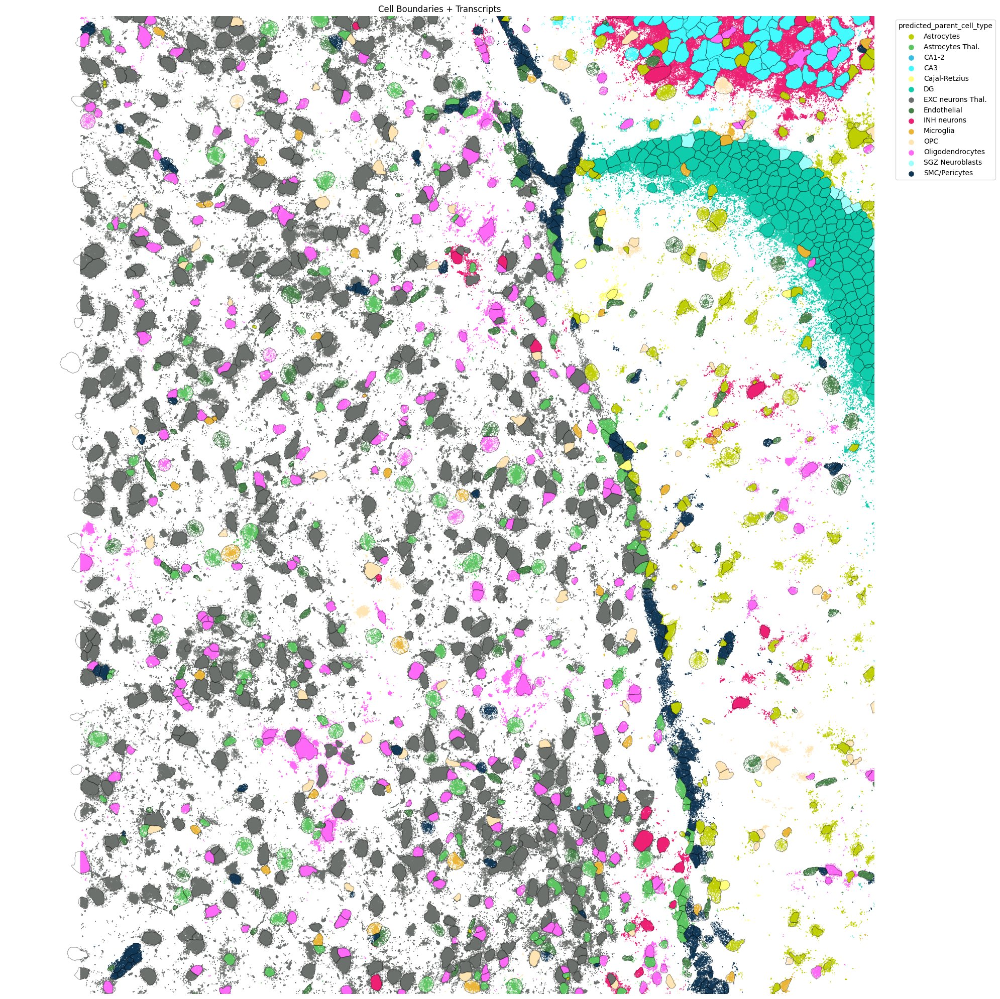

In [49]:
import matplotlib.colors as mcolors

# 1. Grab your original global scanpy colors
scanpy_colors = sdata["table"].uns["cell_type_colors"]
scanpy_cmap = mcolors.ListedColormap(scanpy_colors)

# 2. Call your newly updated function
# It will now combine the tables and map colors flawlessly!
fig, ax = spatial_transcripts(
    sdata,
    color_key="predicted_parent_cell_type",  
    colormap=scanpy_cmap,                    # Pass the standard ListedColormap directly
    scatter_size=0.5,
    use_roi=True, 
    roi=(4000, 4800, 1000, 1900),
    figsize=(20, 20),
    boundary_linewidth=0.8,
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1
)
plt.savefig(os.path.join(saving_path, 'spatial_combined_cell_type_annotation_roi3_recomputed_parents.pdf'))

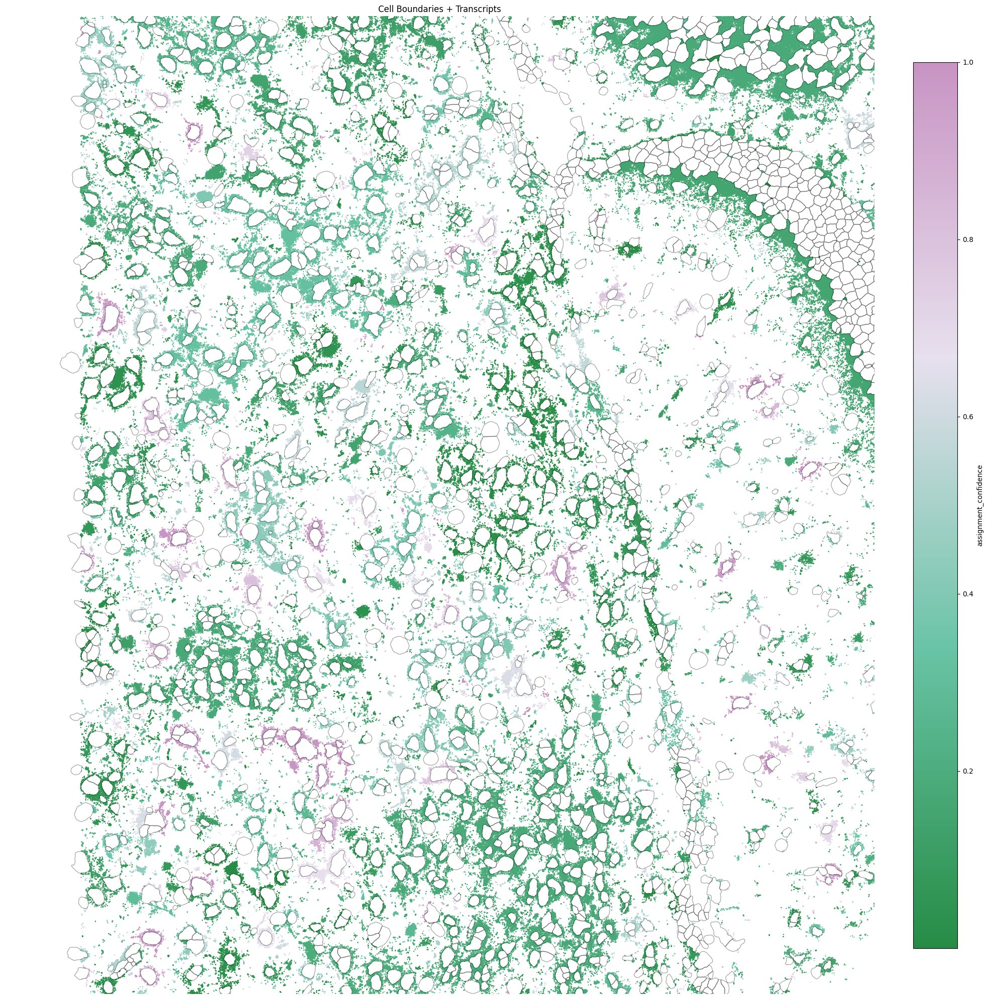

In [52]:
import matplotlib.colors as mcolors

sdata['structure_table'].obs['structure_annotation'] = sdata['structure_table'].obs['structure_annotation'].astype(str)
sdata['structure_table'].obs['is_physically_connected'] = sdata['structure_table'].obs['is_physically_connected'].astype(str)

colors_structures = ["#268c45", "#68c3a5",'#e7e0ee',"#c894c3"]
#colors_structures = ["#e55825", "#faad6c",'#fed1a3',"c8e4bf","76c376"]


# Change this line from ListedColormap to LinearSegmentedColormap
scanpy_cmap = mcolors.LinearSegmentedColormap.from_list("custom_transition", colors_structures)

fig = pl.spatial_transcripts(
    sdata,
    color_key="assignment_confidence",
    scatter_size=1.2,
    use_roi=True,  
    roi=(4000, 4800, 1000, 1900),
    figsize=(20,20),
    boundary_linewidth=0.8,
    colormap=scanpy_cmap, # This will now use the smooth gradient
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1,vmax=1,
    continuous_colormap='winter'
)

plt.savefig(os.path.join(saving_path,'spatial_transcripts_assignment_confidence_roi_3_recomputed_parents.pdf'))

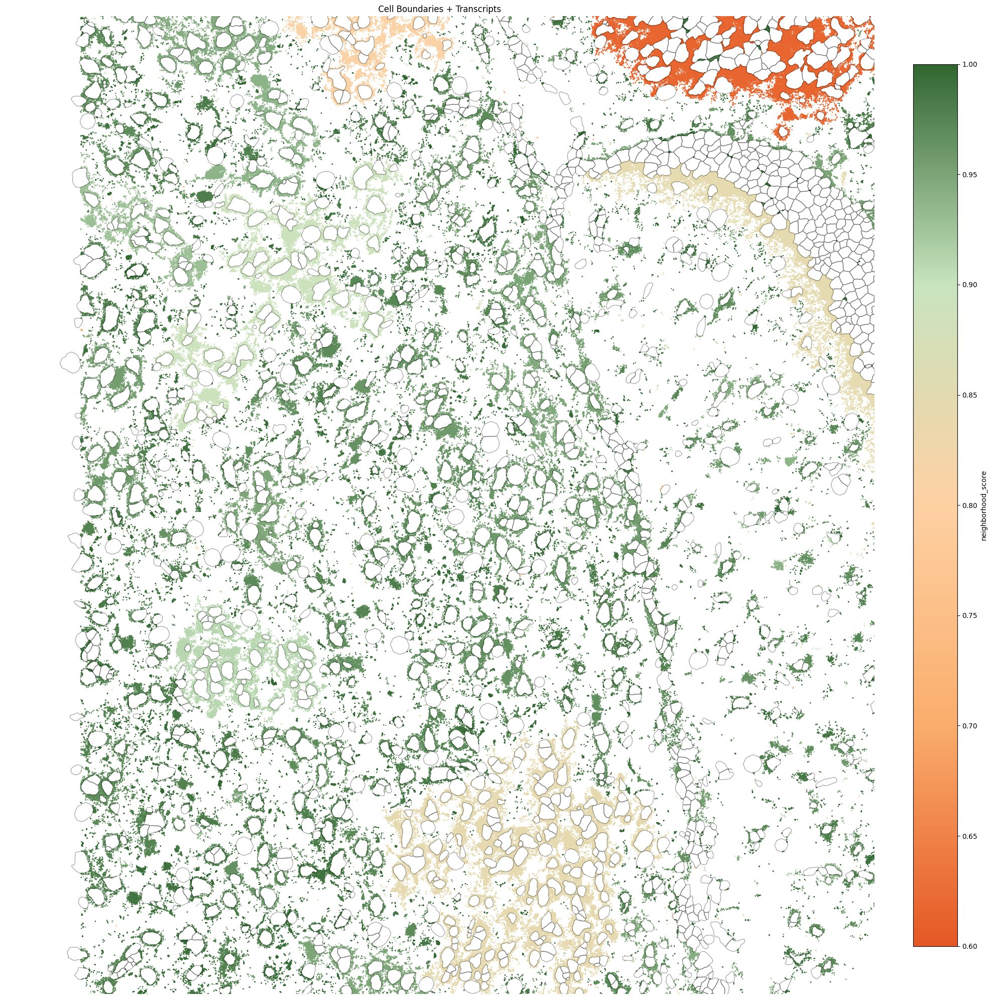

In [53]:
import matplotlib.colors as mcolors

sdata['structure_table'].obs['structure_annotation'] = sdata['structure_table'].obs['structure_annotation'].astype(str)
sdata['structure_table'].obs['is_physically_connected'] = sdata['structure_table'].obs['is_physically_connected'].astype(str)

colors_structures = ["#e55825", "#faad6c",'#fed1a3',"#c8e4bf","#316631"]
#colors_structures = ["#e55825", "#faad6c",'#fed1a3',"c8e4bf","76c376"]


# Change this line from ListedColormap to LinearSegmentedColormap
scanpy_cmap = mcolors.LinearSegmentedColormap.from_list("custom_transition", colors_structures)

fig = pl.spatial_transcripts(
    sdata,
    color_key="neighborhood_score",
    scatter_size=1.2,
    use_roi=True,  
    roi=(4000, 4800, 1000, 1900),
    figsize=(20,20),
    boundary_linewidth=0.8,vmax=1,
    colormap=scanpy_cmap, # This will now use the smooth gradient
    alpha=1, 
    rasterize=True,
    missing_val_sentinel=-1,
    continuous_colormap='winter'
)

plt.savefig(os.path.join(saving_path,'spatial_transcripts_neighborhood_score_roi_3_recomputed_parents.pdf'))

# Now we apply DRVI embeddings on segmented cells

In [ ]:
sdata=sd.read_zarr(data_dir / "data_annotated_drvi_complete.zarr")

In [161]:
new_adata

AnnData object with n_obs × n_vars = 9185 × 4886
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes', 'n_counts', 'leiden', 'area', 'perimeter', 'solidity', 'major_axis_length', 'equivalent_diameter', 'circularity', 'protrusion_length', 'morphological_complexity', 'urna_source_score', 'cell_type', 'DR 1', 'DR 2', 'DR 3', 'DR 4', 'DR 5', 'DR 6', 'DR 7', 'DR 8', 'DR 9', 'DR 10'
    var: 'gene_ids', 'feature_types', 'genome', 'gene_id', 'n_cells'
    uns: 'cell_type_colors', 'dendrogram_cell_type', 'dendrogram_leiden', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'spatialdata_attrs', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial', 'spatial_inverse', 'X_drvi'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'con

In [162]:
new_adata=sdata['table']
import scipy.sparse as sp

# ── Get the genes the model was trained on ────────────────────────────────────
training_genes = model.adata.var_names

missing_genes  = training_genes.difference(new_adata.var_names)
present_genes  = training_genes.intersection(new_adata.var_names)

print(f"Training genes : {len(training_genes)}")
print(f"Present in new : {len(present_genes)}")
print(f"Missing        : {len(missing_genes)}")

# ── Align to training genes ───────────────────────────────────────────────────
if len(missing_genes) > 0:
    zero_block = sp.csr_matrix((new_adata.n_obs, len(missing_genes)))
    missing_adata = sc.AnnData(
        X   = zero_block,
        obs = new_adata.obs,
        var = pd.DataFrame(index=missing_genes)
    )
    new_adata_aligned = sc.concat([new_adata[:, present_genes], missing_adata],
                                   axis=1)
else:
    new_adata_aligned = new_adata[:, present_genes].copy()

# reorder to exactly match training gene order
new_adata_aligned = new_adata_aligned[:, training_genes].copy()

# ── Add counts layer — model expects adata.layers['counts'] ──────────────────
# Check what layer the original training data used
print("Layers in training adata:", list(model.adata.layers.keys()))
print("Layers in new_adata     :", list(new_adata.layers.keys()))

# Use raw counts — adjust the source layer name to match what you have
if 'counts' in new_adata.layers:
    source_layer = new_adata[:, present_genes].layers['counts']
elif 'raw_counts' in new_adata.layers:
    source_layer = new_adata[:, present_genes].layers['raw_counts']
elif 'raw' in new_adata.layers:
    source_layer = new_adata[:, present_genes].layers['raw']
else:
    # fall back to .X assuming it holds raw counts
    source_layer = new_adata[:, present_genes].X

# build the counts layer aligned to training genes
if len(missing_genes) > 0:
    zero_counts = sp.csr_matrix((new_adata.n_obs, len(missing_genes)))
    new_adata_aligned.layers['counts'] = sp.hstack([source_layer, zero_counts])
else:
    new_adata_aligned.layers['counts'] = source_layer.copy()

# ensure correct gene order
new_adata_aligned = new_adata_aligned[:, training_genes].copy()

# ── Encode ────────────────────────────────────────────────────────────────────
latent = model.get_latent_representation(new_adata_aligned, give_mean=True)
new_adata.obsm['X_drvi'] = latent
new_adata_aligned.obsm['X_drvi'] = latent
print(f"Latent shape: {latent.shape}")

Training genes : 13073
Present in new : 4885
Missing        : 8188
Layers in training adata: ['counts']
Layers in new_adata     : ['raw']
INFO     Input AnnData not setup with scvi-tools. attempting to transfer AnnData setup                             
Latent shape: (9185, 128)


Active (non-vanished) DRs: 10


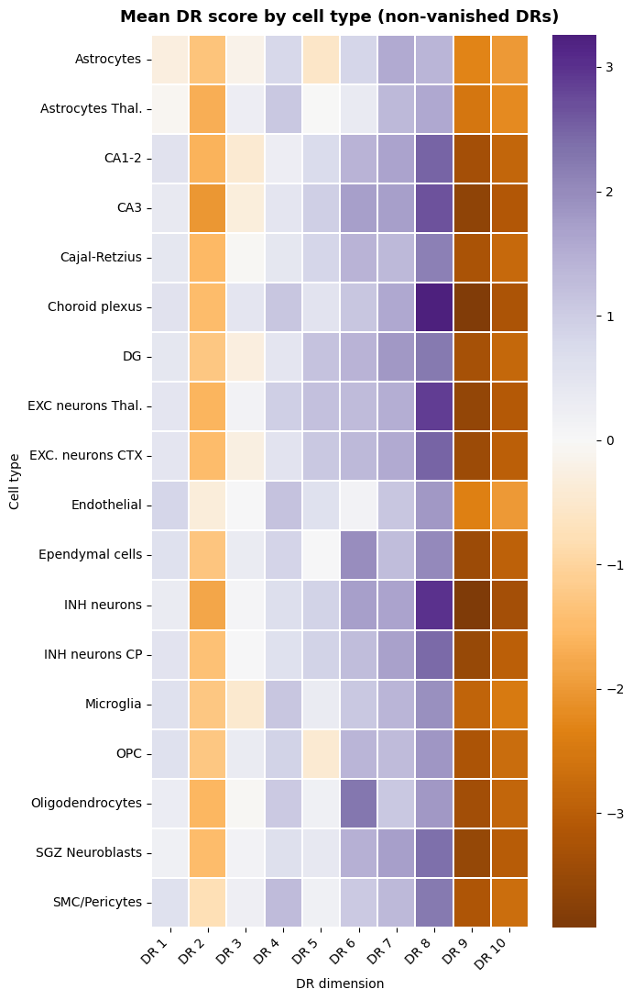

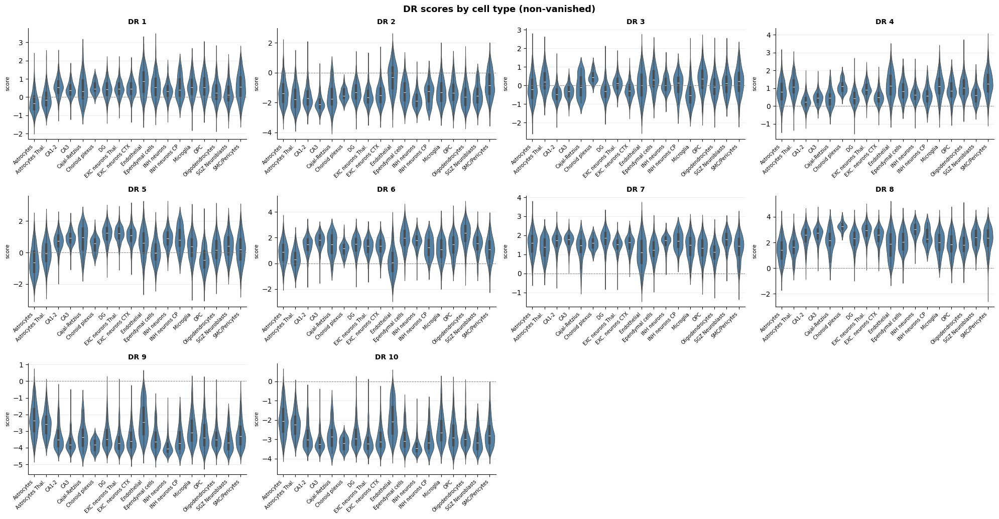

In [163]:
cell_type_key = 'cell_type'

# ── Filter to non-vanished DRs using embed.var ────────────────────────────────
non_vanished = embed.var[~embed.var['vanished']].sort_values('order')
active_dims  = non_vanished['original_dim_id'].tolist()   # column indices in X_drvi
active_titles = non_vanished['title'].tolist()             # e.g. "DR 1", "DR 2" ...

print(f"Active (non-vanished) DRs: {len(active_dims)}")

# ── Build DR score dataframe from latent representation ───────────────────────
df = pd.DataFrame(
    new_adata.obsm['X_drvi'][:, active_dims],
    index=new_adata.obs_names,
    columns=active_titles
)
df[cell_type_key] = new_adata.obs[cell_type_key].values
cell_type_order   = sorted(df[cell_type_key].unique())

# ── 1. Heatmap ────────────────────────────────────────────────────────────────
mean_scores = df.groupby(cell_type_key)[active_titles].mean().loc[cell_type_order]

fig, ax = plt.subplots(figsize=(len(active_titles) * 0.7, len(cell_type_order) * 0.5 + 2))
sns.heatmap(
    mean_scores,
    cmap='PuOr', center=0,
    linewidths=0.3, linecolor='white',
    xticklabels=True, yticklabels=True,
    ax=ax
)
ax.set_title('Mean DR score by cell type (non-vanished DRs)',
             fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('DR dimension')
ax.set_ylabel('Cell type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'dr_scores_celltype_heatmap.pdf'),
            bbox_inches='tight')
plt.show()

# ── 2. Violin ─────────────────────────────────────────────────────────────────
df_long = df.melt(id_vars=cell_type_key, var_name='DR', value_name='score')

n_drs = len(active_titles)
ncols = 4
nrows = int(np.ceil(n_drs / ncols))

fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 5, nrows * 3.5),
                         sharey=False)
axes = np.array(axes).flatten()

for ax, dr in zip(axes, active_titles):
    sns.violinplot(
        data=df_long[df_long['DR'] == dr],
        x=cell_type_key,
        y='score',
        order=cell_type_order,
        ax=ax,
        inner='box',
        linewidth=0.7,
        color='steelblue',
        scale='width',
    )
    ax.axhline(0, color='grey', linewidth=0.7, linestyle='--')
    ax.set_title(dr, fontsize=10, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('score', fontsize=8)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=7)
    ax.yaxis.grid(True, linewidth=0.5, color='#E2E4E7')
    ax.set_axisbelow(True)

for ax in axes[n_drs:]:
    ax.set_visible(False)

fig.suptitle('DR scores by cell type (non-vanished)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'dr_scores_celltype_violin.pdf'),
            bbox_inches='tight')
plt.show()

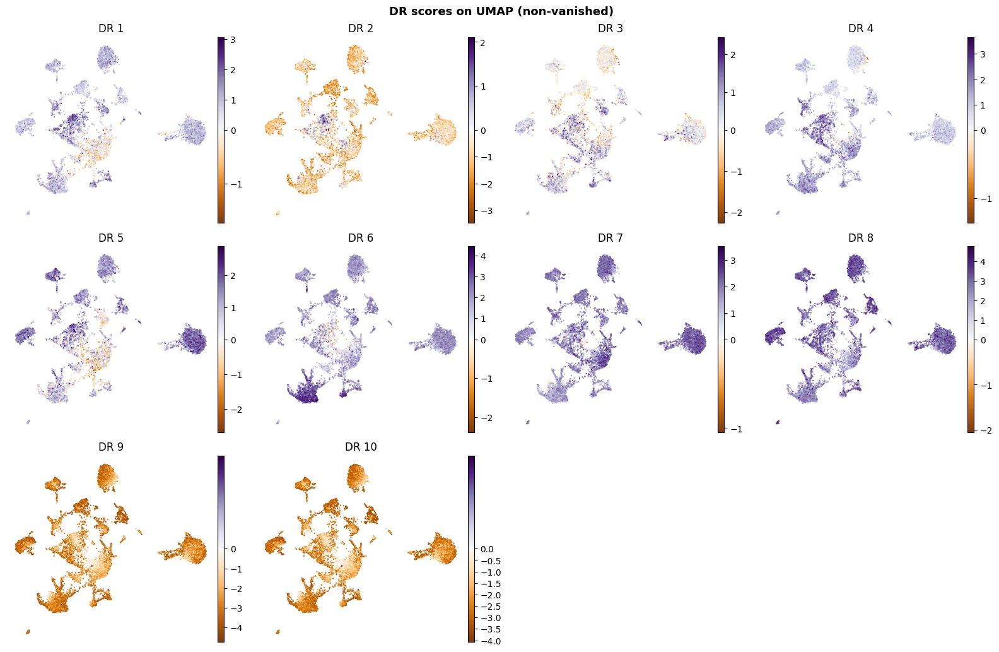

In [164]:
# ── Plot non-vanished DR scores on UMAP ───────────────────────────────────────
# assumes new_adata has .obsm['X_umap'] already computed
# if not: sc.pp.neighbors(new_adata, use_rep='X_drvi'); sc.tl.umap(new_adata)

# store DR scores in obs so sc.pl.umap can access them
for dim, title in zip(active_dims, active_titles):
    new_adata.obs[title] = new_adata.obsm['X_drvi'][:, dim]

n_drs  = len(active_titles)
ncols  = 4
nrows  = int(np.ceil(n_drs / ncols))

fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 4, nrows * 3.5))
axes = np.array(axes).flatten()

for ax, title in zip(axes, active_titles):
    sc.pl.umap(
        new_adata,
        color=title,
        cmap='PuOr',
        vcenter=0,
        ax=ax,
        show=False,
        frameon=False,
        colorbar_loc='right',
        title=title,
        s=10,
    )

for ax in axes[n_drs:]:
    ax.set_visible(False)

fig.suptitle('DR scores on UMAP (non-vanished)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'dr_scores_umap.pdf'), bbox_inches='tight')
plt.show()

# Predicted_parent_vs_structure

In [56]:
import scanpy as sc

# 1. Build the reference dictionary from your exact cell type configuration
ordered_cell_types_ref = sorted(
    [
        "Astrocytes",
        "Astrocytes Thal.",
        "CA1-2",
        "CA3",
        "Cajal-Retzius",
        "Choroid plexus",
        "DG",
        "Ependymal cells",
        "Endothelial",
        "EXC neurons Thal.",
        "EXC. neurons CTX",
        "INH neurons",
        "INH neurons CP",
        "Microglia",
        "OPC",
        "Oligodendrocytes",
        "SGZ Neuroblasts",
        "SMC/Pericytes",
    ]
)
cell_type_to_color = dict(zip(ordered_cell_types_ref, sdata['table'].uns['cell_type_colors']))

# 2. Automatically capture EVERY unique string present in your column
unique_predicted_strings = sdata["structure_table"].obs[
    "predicted_parent_cell_type"
].unique()

# 3. Build a robust color map dictionary
# It assigns your custom hex codes to valid cell types, and a neutral light grey to nan/unassigned slots
predicted_palette_map = {}
for entry in unique_predicted_strings:
    entry_str = str(entry)
    if entry_str in cell_type_to_color:
        predicted_palette_map[entry_str] = cell_type_to_color[entry_str]
    else:
        predicted_palette_map[entry_str] = (
            "#E0E0E0"  # Neutral light grey fallback for nan / unassigned background structures
        )


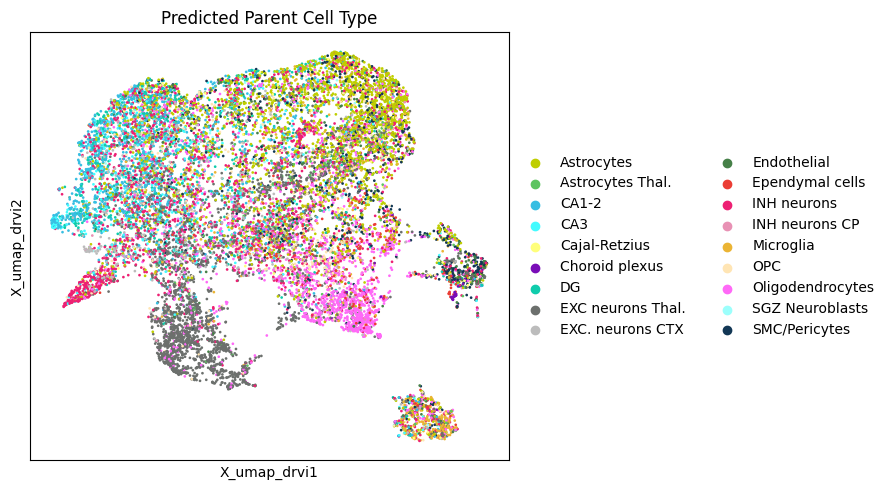

NameError: name 'struct_color_map' is not defined

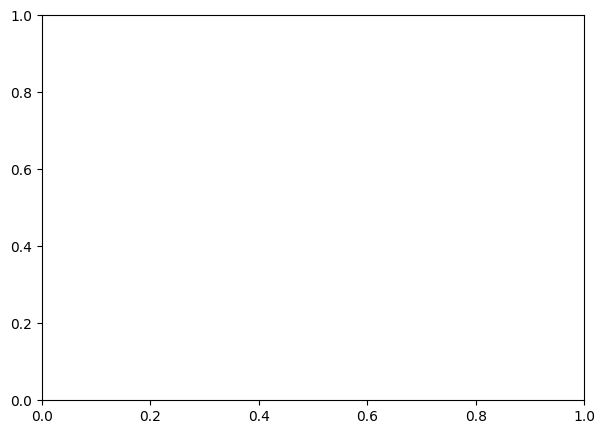

In [61]:
import matplotlib

# Ensure font type is set to true editable text for vector output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# ----------------------------------------------------
# 1. Export First UMAP: Predicted Parent Cell Type
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

sc.pl.embedding(
    sdata["structure_table"],
    color="predicted_parent_cell_type",
    basis="X_umap_drvi",
    palette=predicted_palette_map,s=15,
    ax=ax,
    show=False,
    title="Predicted Parent Cell Type",
)

plt.tight_layout()
plt.savefig(
    os.path.join(saving_path, "umap_predicted_parent_cell_type.pdf"),
    bbox_inches="tight",
    format="pdf",
    dpi=300,
)
plt.show()

# ----------------------------------------------------
# 2. Export Second UMAP: Structure Annotation
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5))

sc.pl.embedding(
    sdata["structure_table"],
    color="structure_annotation",
    basis="X_umap_drvi",
    palette=struct_color_map,s=10,
    ax=ax,
    show=False,
    title="Structure Annotation",
)

plt.tight_layout()
plt.savefig(
    os.path.join(saving_path, "umap_structure_annotation.pdf"),
    bbox_inches="tight",
    format="pdf",
    dpi=300,
)
plt.show()

print(f"Both individual plots successfully saved to: {saving_path}")

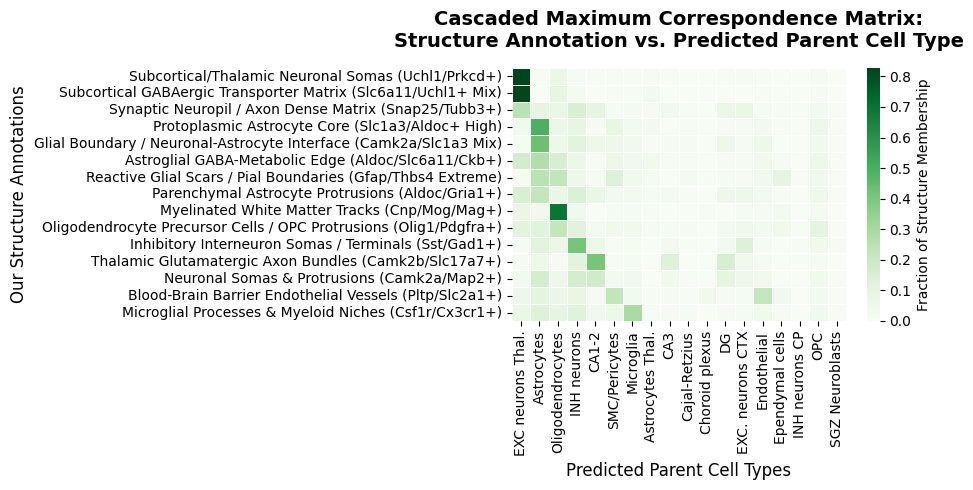

In [197]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# 1. Compute and sort the cross-tabulation matrix
cross_tab = pd.crosstab(
    sdata["structure_table"].obs["structure_annotation"],
    sdata["structure_table"].obs["predicted_parent_cell_type"],
    normalize="index",
)

col_order = list(cross_tab.sum(axis=0).sort_values(ascending=False).index)
row_max_col = cross_tab.idxmax(axis=1)

sorted_rows, sorted_cols = [], []
for col in col_order:
    m_rows = row_max_col[
        (row_max_col == col) & (~row_max_col.index.isin(sorted_rows))
    ].index
    if len(m_rows) > 0:
        sorted_rows.extend(
            cross_tab.loc[m_rows, col].sort_values(ascending=False).index
        )
        sorted_cols.append(col)

sorted_rows.extend([r for r in cross_tab.index if r not in sorted_rows])
sorted_cols.extend([c for c in cross_tab.columns if c not in sorted_cols])
cross_tab_sorted = cross_tab.loc[sorted_rows, sorted_cols]

# 2. Render heatmap directly into a vector PDF file
fig, ax = plt.subplots(figsize=(9.5, 5))
sns.heatmap(
    cross_tab_sorted,
    cmap="Greens",
    annot=False,
    linewidths=0.5,
    ax=ax,
    cbar_kws={"label": "Fraction of Structure Membership"},
)

ax.set_title(
    "Cascaded Maximum Correspondence Matrix:\nStructure Annotation vs. Predicted Parent Cell Type",
    weight="bold",
    fontsize=14,
    pad=15,
)
ax.set_ylabel("Our Structure Annotations", fontsize=12)
ax.set_xlabel("Predicted Parent Cell Types", fontsize=12)

plt.tight_layout()
plt.savefig(os.path.join(saving_path,'parent_vs_structure_annotation.pdf'), bbox_inches="tight", format="pdf", dpi=300)
plt.show()

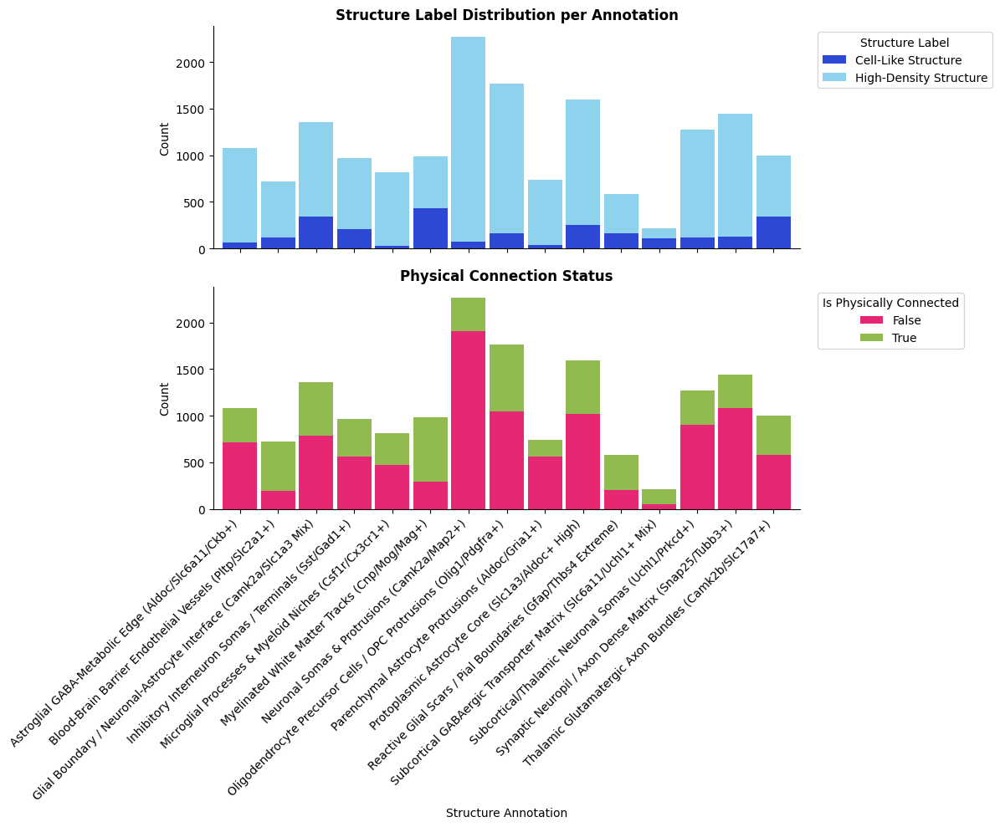

In [206]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# 1. Generate both cross-tabulations (sharing the exact same index alignment)
structure_vs_urna = pd.crosstab(
    sdata["structure_table"].obs["structure_annotation"],
    sdata["structure_table"].obs["structure_label"],
)

structure_vs_conn = pd.crosstab(
    sdata["structure_table"].obs["structure_annotation"],
    sdata["structure_table"].obs["is_physically_connected"],
)

# 2. Set up two subplots sharing the X-axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Top Subplot: Structure Annotation vs. Structure Label
structure_vs_urna.plot(kind="bar", stacked=True, width=0.9, ax=ax1,
                      color=[ "#2c48d4","#8ed2ed"])  # Precise custom category colors)
ax1.set_title("Structure Label Distribution per Annotation", weight="bold")
ax1.set_ylabel("Count")
ax1.legend(title="Structure Label", bbox_to_anchor=(1.02, 1), loc="upper left")

# Bottom Subplot: Physical Connection Proportions/Counts
structure_vs_conn.plot(
    kind="bar",
    stacked=True,
    width=0.9,
    ax=ax2,
    color=["#e62773", "#91ba50"],  # Precise custom category colors
)
ax2.set_title("Physical Connection Status", weight="bold")
ax2.set_ylabel("Count")
ax2.set_xlabel("Structure Annotation")
ax2.legend(
    title="Is Physically Connected", bbox_to_anchor=(1.02, 1), loc="upper left"
)

# Rotate labels on the shared X-axis cleanly to avoid overlap
plt.xticks(rotation=45, ha="right")

# 3. Export as an individual vector PDF file
plt.tight_layout()
plt.savefig(os.path.join(saving_path,'structure_quantifications.pdf'), bbox_inches="tight", format="pdf", dpi=300)
plt.show()

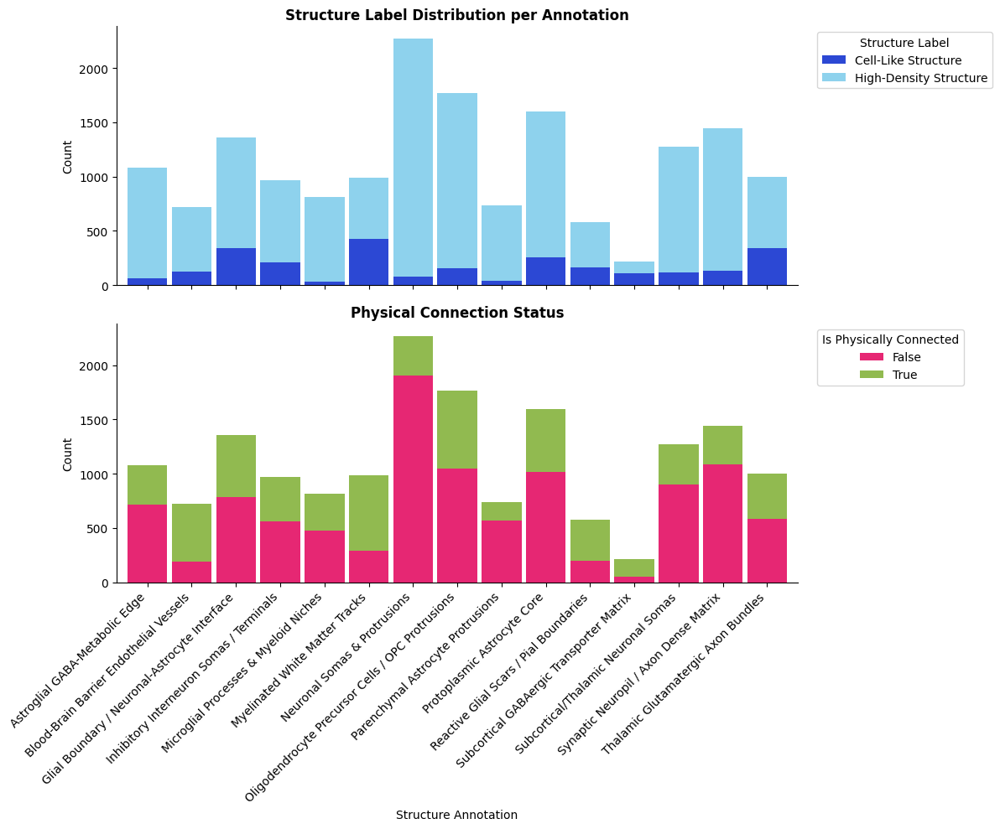

In [209]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# 1. Clean the structure_annotation strings by stripping everything inside parentheses
short_anno = (
    sdata["structure_table"]
    .obs["structure_annotation"]
    .astype(str)
    .str.replace(r"\s*\(.*?\)", "", regex=True)
)

# 2. Generate both cross-tabulations using the cleaned labels
structure_vs_urna = pd.crosstab(
    short_anno, sdata["structure_table"].obs["structure_label"]
)
structure_vs_conn = pd.crosstab(
    short_anno, sdata["structure_table"].obs["is_physically_connected"]
)

# 3. Render stacked bar subplots sharing the X-axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

structure_vs_urna.plot(kind="bar", stacked=True, width=0.9, ax=ax1,
                      color=[ "#2c48d4","#8ed2ed"])
ax1.set_title("Structure Label Distribution per Annotation", weight="bold")
ax1.set_ylabel("Count")
ax1.legend(title="Structure Label", bbox_to_anchor=(1.02, 1), loc="upper left")

structure_vs_conn.plot(
    kind="bar",
    stacked=True,
    width=0.9,
    ax=ax2,
    color=["#e62773", "#91ba50"],
)
ax2.set_title("Physical Connection Status", weight="bold")
ax2.set_ylabel("Count")
ax2.set_xlabel("Structure Annotation")
ax2.legend(
    title="Is Physically Connected", bbox_to_anchor=(1.02, 1), loc="upper left"
)

plt.xticks(rotation=45, ha="right")

# 4. Export directly to the refined saving_path
plt.tight_layout()
plt.savefig(os.path.join(saving_path,'structure_quantifications_short_name.pdf'), bbox_inches="tight", format="pdf", dpi=300)
plt.show()

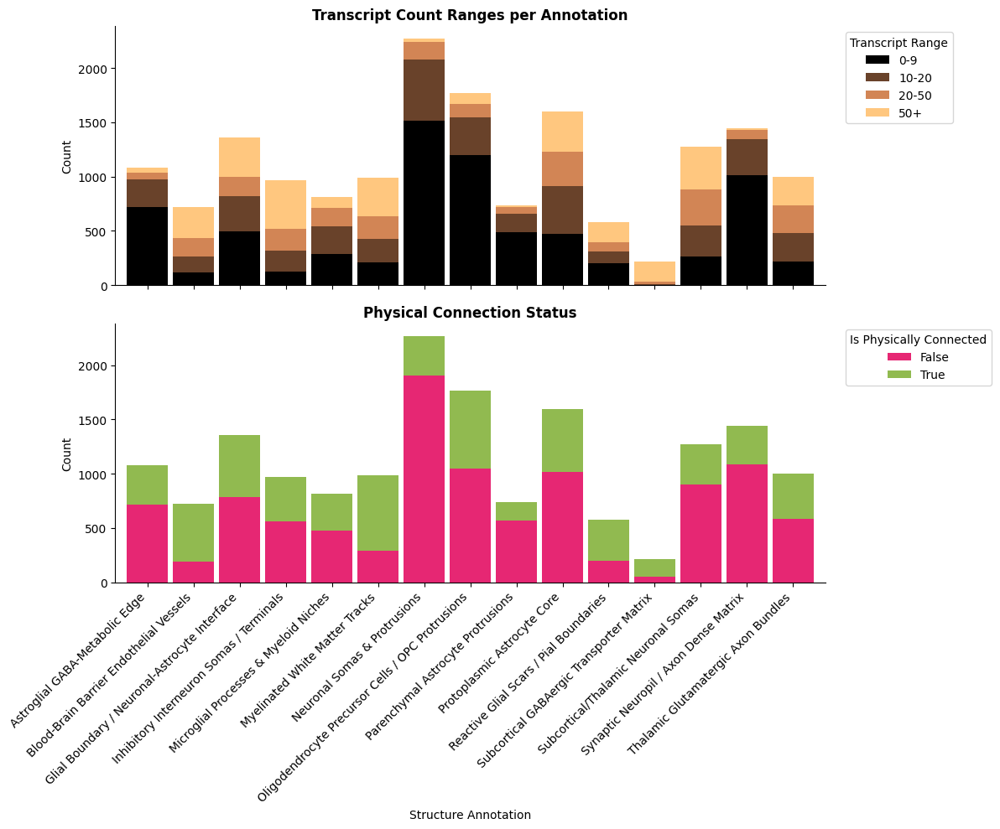

In [222]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# 1. Clean the structure_annotation strings by stripping everything inside parentheses
short_anno = (
    sdata["structure_table"]
    .obs["structure_annotation"]
    .astype(str)
    .str.replace(r"\s*\(.*?\)", "", regex=True)
)

# 2. Generate both cross-tabulations using the cleaned labels
structure_vs_urna = pd.crosstab(
    short_anno, sdata["structure_table"].obs["structure_label"]
)
structure_vs_conn = pd.crosstab(
    short_anno, sdata["structure_table"].obs["is_physically_connected"]
)

# 3. Render stacked bar subplots sharing the X-axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

structure_vs_urna.plot(kind="bar", stacked=True, width=0.9, ax=ax1,
                      color=[ "#2c48d4","#8ed2ed"])
ax1.set_title("Structure Label Distribution per Annotation", weight="bold")
ax1.set_ylabel("Count")
ax1.legend(title="Structure Label", bbox_to_anchor=(1.02, 1), loc="upper left")

structure_vs_conn.plot(
    kind="bar",
    stacked=True,
    width=0.9,
    ax=ax2,
    color=["#e62773", "#91ba50"],
)
ax2.set_title("Physical Connection Status", weight="bold")
ax2.set_ylabel("Count")
ax2.set_xlabel("Structure Annotation")
ax2.legend(
    title="Is Physically Connected", bbox_to_anchor=(1.02, 1), loc="upper left"
)

plt.xticks(rotation=45, ha="right")

# 4. Export directly to the refined saving_path
plt.tight_layout()
plt.savefig(os.path.join(saving_path,'structure_quantifications_short_name.pdf'), bbox_inches="tight", format="pdf", dpi=300)
plt.show()

import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# 1. Clean structure_annotation strings (remove parentheses)
short_anno = (
    sdata["structure_table"]
    .obs["structure_annotation"]
    .astype(str)
    .str.replace(r"\s*\(.*?\)", "", regex=True)
)

# 2. Bin n_transcripts into custom categorical ranges
transcript_bins = pd.cut(
    sdata["structure_table"].obs["n_transcripts"],
    bins=[-float("inf"), 9, 20, 50, float("inf")],
    labels=["0-9", "10-20", "20-50", "50+"],
)

# 3. Generate both cross-tabulations using the cleaned labels
structure_vs_urna = pd.crosstab(short_anno, transcript_bins)
structure_vs_conn = pd.crosstab(
    short_anno, sdata["structure_table"].obs["is_physically_connected"]
)

# 4. Render stacked bar subplots sharing the X-axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Top Subplot: Transcript Range Distribution
structure_vs_urna.plot(kind="bar", stacked=True, width=0.9, ax=ax1, cmap="copper")
ax1.set_title("Transcript Count Ranges per Annotation", weight="bold")
ax1.set_ylabel("Count")
ax1.legend(title="Transcript Range", bbox_to_anchor=(1.02, 1), loc="upper left")

# Bottom Subplot: Physical Connection Status
structure_vs_conn.plot(
    kind="bar",
    stacked=True,
    width=0.9,
    ax=ax2,
    color=["#e62773", "#91ba50"],
)
ax2.set_title("Physical Connection Status", weight="bold")
ax2.set_ylabel("Count")
ax2.set_xlabel("Structure Annotation")
ax2.legend(
    title="Is Physically Connected", bbox_to_anchor=(1.02, 1), loc="upper left"
)

plt.xticks(rotation=45, ha="right")

# 5. Export directly to the specified path and display
plt.tight_layout()
plt.savefig(
    os.path.join(saving_path, "structure_quantifications_n_counts_short_name.pdf"),
    bbox_inches="tight",
    format="pdf",
    dpi=300,
)
plt.show()

import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# 1. Clean structure_annotation strings (remove parentheses for cleaner X-axis labels)
short_anno = (
    sdata["structure_table"]
    .obs["structure_annotation"]
    .astype(str)
    .str.replace(r"\s*\(.*?\)", "", regex=True)
)

# 2. Bin neighborhood scores into custom intervals using your thresholds
# This creates 5 distinct ranges bounded by 0.3, 0.5, 0.7, and 0.9
score_bins = pd.cut(
    sdata["structure_table"].obs["neighborhood_score"],
    bins=[-float("inf"), 0.3, 0.5, 0.7, 0.9, float("inf")],
    labels=["< 0.3", "0.3 - 0.5", "0.5 - 0.7", "0.7 - 0.9", ">= 0.9"],
)

# 3. Generate cross-tabulation and normalize to proportions (percentages)
thresh_vs_annotation = pd.crosstab(short_anno, score_bins)
thresh_vs_annotation = thresh_vs_annotation.div(thresh_vs_annotation.sum(axis=1), axis=0)

# 4. Sort rows to highlight low-scoring annotations
# This places annotations with the highest proportion of '< 0.3' and '0.3 - 0.5' on the far left
thresh_vs_annotation = thresh_vs_annotation.sort_values(
    by=["< 0.3", "0.3 - 0.5"], 
    ascending=[False, False]
)

# 5. Render single stacked bar plot
fig, ax = plt.subplots(figsize=(10, 5))

# Explicit color palette: Warm colors (red/orange) for low scores to make them pop,
# and muted cool colors (greens/blues) for high scores.
custom_colors = ["#e6550d", "#fdae6b", "#fdd0a2", "#c7e9c0", "#74c476"]

thresh_vs_annotation.plot(
    kind="bar",
    stacked=True,
    width=0.9,
    ax=ax,
    color=custom_colors
)

# Styling and labels
ax.set_title("Distribution of Neighborhood Scores Across Multi-Thresholds", weight="bold", fontsize=14)
ax.set_ylabel("Proportion", fontsize=12)
ax.set_xlabel("Structure Annotation", fontsize=12)
ax.legend(title="Neighborhood Score Range", bbox_to_anchor=(1.02, 1), loc="upper left")

# Rotate X-axis labels for readability
plt.xticks(rotation=45, ha="right")

# 6. Export directly to the specified path and display
plt.tight_layout()
plt.savefig(
    os.path.join(saving_path, "neighborhood_score_multi_threshold_distribution.pdf"),
    bbox_inches="tight",
    format="pdf",
    dpi=300,
)
plt.show()
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# 1. Clean structure_annotation strings (remove parentheses for cleaner X-axis labels)
short_anno = (
    sdata["structure_table"]
    .obs["structure_annotation"]
    .astype(str)
    .str.replace(r"\s*\(.*?\)", "", regex=True)
)

# 2. Bin parent scores into custom intervals using your thresholds
# This creates 5 distinct ranges bounded by 0.3, 0.5, 0.7, and 0.9
parent_score_bins = pd.cut(
    sdata["structure_table"].obs["parent_score"],
    bins=[-float("inf"), 0.3, 0.5, 0.7, 0.9, float("inf")],
    labels=["< 0.3", "0.3 - 0.5", "0.5 - 0.7", "0.7 - 0.9", ">= 0.9"],
)

# 3. Generate cross-tabulation and normalize to proportions (percentages)
thresh_vs_annotation = pd.crosstab(short_anno, parent_score_bins)
thresh_vs_annotation = thresh_vs_annotation.div(thresh_vs_annotation.sum(axis=1), axis=0)

# 4. Sort rows to highlight low-scoring annotations
# This places annotations with the highest proportion of '< 0.3' and '0.3 - 0.5' on the far left
thresh_vs_annotation = thresh_vs_annotation.sort_values(
    by=["< 0.3", "0.3 - 0.5"], 
    ascending=[False, False]
)

# 5. Render single stacked bar plot
fig, ax = plt.subplots(figsize=(10, 5))

# Explicit color palette: Warm colors (red/orange) for low scores to make them pop,
# and muted cool colors (greens/blues) for high scores.
custom_colors = ["#2b5387", "#508bd9", "#efe3fc", "#b34f75", "#82113c"]

thresh_vs_annotation.plot(
    kind="bar",
    stacked=True,
    width=0.9,
    ax=ax,
    color=custom_colors
)

# Styling and labels
ax.set_title("Distribution of Parent Scores Across Multi-Thresholds", weight="bold", fontsize=14)
ax.set_ylabel("Proportion", fontsize=12)
ax.set_xlabel("Structure Annotation", fontsize=12)
ax.legend(title="Parent Score Range", bbox_to_anchor=(1.02, 1), loc="upper left")

# Rotate X-axis labels for readability
plt.xticks(rotation=45, ha="right")

# 6. Export directly to the specified path and display
plt.tight_layout()
plt.savefig(
    os.path.join(saving_path, "parent_score_multi_threshold_distribution.pdf"),
    bbox_inches="tight",
    format="pdf",
    dpi=300,
)
plt.show()

Now we explore neighborhood explore

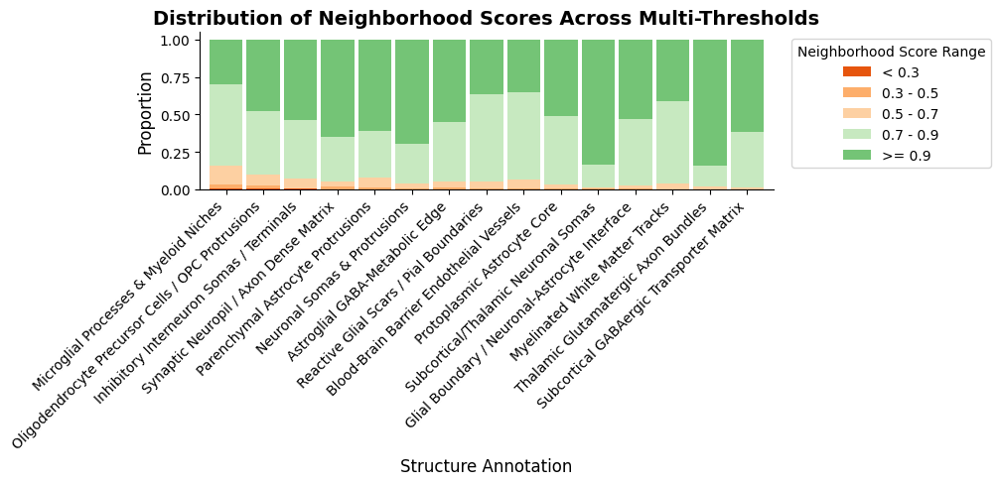

In [232]:
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# --- 1. DATA PROCESSING & VARIABLE CREATION ---

# Clean structure_annotation strings (remove text in parentheses)
short_anno = (
    sdata["structure_table"]
    .obs["structure_annotation"]
    .astype(str)
    .str.replace(r"\s*\(.*?\)", "", regex=True)
)

# Total counts per structural annotation for the left tracking bar
total_counts = short_anno.value_counts()

# Bin n_transcripts into custom categorical ranges
transcript_bins = pd.cut(
    sdata["structure_table"].obs["n_transcripts"],
    bins=[-float("inf"), 9, 20, 50, float("inf")],
    labels=["0-9", "10-20", "20-50", "50+"],
)

# Bin neighborhood scores into custom intervals
score_bins = pd.cut(
    sdata["structure_table"].obs["neighborhood_score"],
    bins=[-float("inf"), 0.3, 0.5, 0.7, 0.9, float("inf")],
    labels=["< 0.3", "0.3 - 0.5", "0.5 - 0.7", "0.7 - 0.9", ">= 0.9"],
)

# Bin parent scores into custom intervals
parent_score_bins = pd.cut(
    sdata["structure_table"].obs["parent_score"],
    bins=[-float("inf"), 0.3, 0.5, 0.7, 0.9, float("inf")],
    labels=["< 0.3", "0.3 - 0.5", "0.5 - 0.7", "0.7 - 0.9", ">= 0.9"],
)

# Bin assignment confidence into custom intervals
conf_bins = pd.cut(
    sdata["structure_table"].obs["assignment_confidence"],
    bins=[-float("inf"), 0.1, 0.3, 0.5, 0.9, float("inf")],
    labels=["< 0.1", "0.1 - 0.3", "0.3 - 0.5", "0.5 - 0.9", ">= 0.9"],
)

# --- 2. GENERATE AND NORMALIZE ALL CROSS-TABULATIONS ---

# Ensure consistent index order across all structures based on total counts
# For horizontal bars, reversing the order makes the highest counts appear at the top
structure_order = total_counts.index[::-1]

def get_normalized_crosstab(v2):
    ct = pd.crosstab(short_anno, v2)
    return ct.reindex(structure_order).div(ct.sum(axis=1), axis=0)

df_label = get_normalized_crosstab(sdata["structure_table"].obs["structure_label"])
df_trans = get_normalized_crosstab(transcript_bins)
df_conn  = get_normalized_crosstab(sdata["structure_table"].obs["is_physically_connected"])
df_neigh = get_normalized_crosstab(score_bins)
df_paren = get_normalized_crosstab(parent_score_bins)
df_conf  = get_normalized_crosstab(conf_bins)

# --- 3. RENDER TRANSPOSED PLOT (SHARED Y-AXIS) ---

# 1 Left metadata panel + 6 relative panels side-by-side. 
fig, axes = plt.subplots(
    1, 7, figsize=(15, 6), sharey=True, 
    gridspec_kw={'width_ratios': [0.8, 1, 1, 1, 1, 1, 1]}
)
width_val = 0.95

# Panel 0: Far-Left Total Counts indicator bar (Horizontal, raw values)
total_counts.reindex(structure_order).plot(kind="barh", color="#4a4a4a", width=width_val, ax=axes[0])
axes[0].set_xlabel("Total N", fontsize=10, weight="bold")
axes[0].grid(axis='x', linestyle='--', alpha=0.5)
axes[0].set_ylabel("Structure Annotation", fontsize=12, weight="bold")

# Panel 1: Structure Label
df_label.plot(kind="barh", stacked=True, width=width_val, ax=axes[1], color=["#2c48d4", "#8ed2ed"])
axes[1].legend(title="Structure Label", bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2)

# Panel 2: Transcript Ranges
df_trans.plot(kind="barh", stacked=True, width=width_val, ax=axes[2], cmap="copper")
axes[2].legend(title="Transcript Range", bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2)

# Panel 3: Physical Connection
df_conn.plot(kind="barh", stacked=True, width=width_val, ax=axes[3], color=["#e62773", "#91ba50"])
axes[3].legend(title="Physically Connected", bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2)

# Panel 4: Neighborhood Score
custom_colors_neighborhood = ["#e6550d", "#fdae6b", "#fdd0a2", "#c7e9c0", "#74c476"]
df_neigh.plot(kind="barh", stacked=True, width=width_val, ax=axes[4], color=custom_colors_neighborhood)
axes[4].legend(title="Neighborhood Range", bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2)

# Panel 5: Parent Score
custom_colors_parent = ["#2b5387", "#508bd9", "#efe3fc", "#b34f75", "#82113c"]
df_paren.plot(kind="barh", stacked=True, width=width_val, ax=axes[5], color=custom_colors_parent)
axes[5].legend(title="Parent Score Range", bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2)

# Panel 6: Assignment Confidence
custom_colors_conf = ["#238b45", "#66c2a4", "#e7e1ef", "#c994c7", "#dd1c77"]
df_conf.plot(kind="barh", stacked=True, width=width_val, ax=axes[6], color=custom_colors_conf)
axes[6].legend(title="Confidence Range", bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2)

# Standardize x-labels and limits for all relative distribution plots
for ax in axes[1:]:
    ax.set_xlabel("Proportion", fontsize=10)
    ax.set_xlim(0, 1)

# Adjust spaces tightly between adjacent horizontal bars
plt.subplots_adjust(wspace=0.05)

# --- 4. EXPORT ---
output_filename = "transposed_structure_metrics_dashboard_trans.pdf"
plt.savefig(
    os.path.join(saving_path, output_filename),
    bbox_inches="tight",
    format="pdf",
    dpi=300,
)
plt.show()

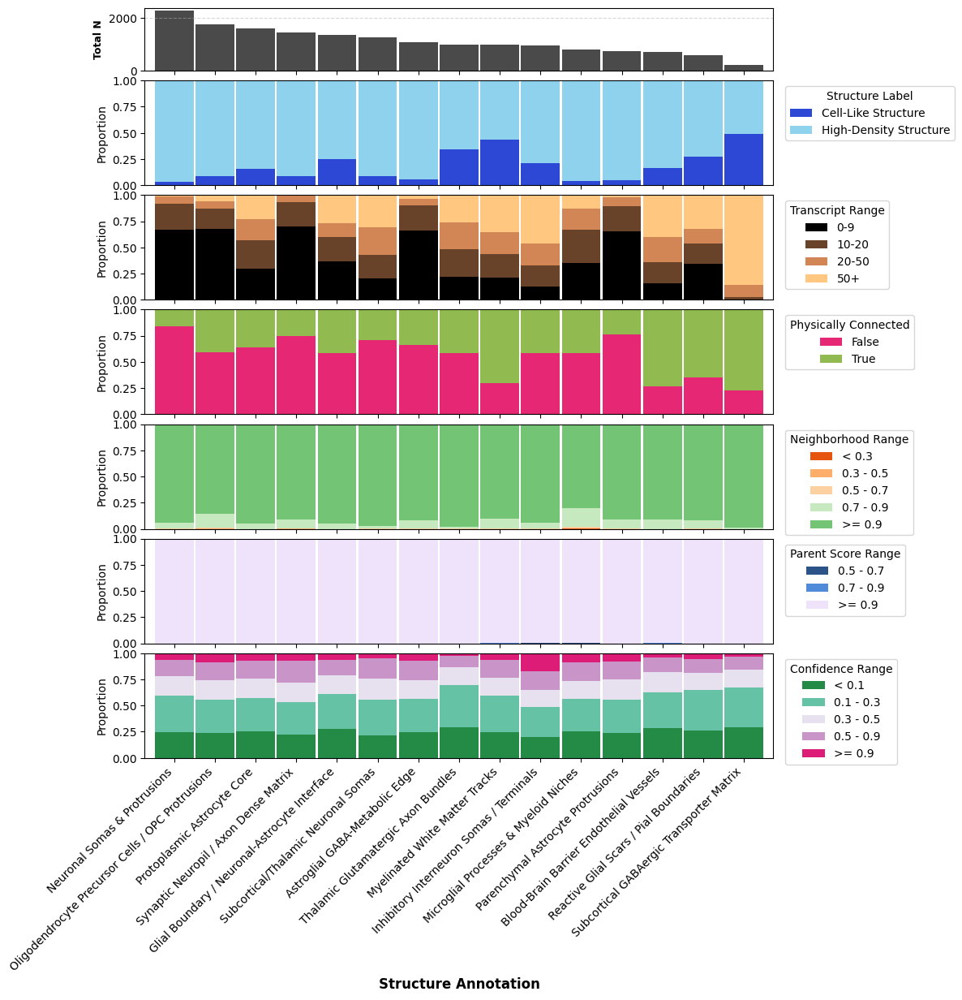

In [50]:
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type globally for editable vector text output (Type 42)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# --- 1. DATA PROCESSING & VARIABLE CREATION ---

# Clean structure_annotation strings (remove text in parentheses)
short_anno = (
    sdata["structure_table"]
    .obs["structure_annotation"]
    .astype(str)
    .str.replace(r"\s*\(.*?\)", "", regex=True)
)

# Total counts per structural annotation for the top tracking bar
total_counts = short_anno.value_counts()

# Bin n_transcripts into custom categorical ranges
transcript_bins = pd.cut(
    sdata["structure_table"].obs["n_transcripts"],
    bins=[-float("inf"), 9, 20, 50, float("inf")],
    labels=["0-9", "10-20", "20-50", "50+"],
)

# Bin neighborhood scores into custom intervals
score_bins = pd.cut(
    sdata["structure_table"].obs["neighborhood_score"],
    bins=[-float("inf"), 0.3, 0.5, 0.7, 0.9, float("inf")],
    labels=["< 0.3", "0.3 - 0.5", "0.5 - 0.7", "0.7 - 0.9", ">= 0.9"],
)

# Bin parent scores into custom intervals
parent_score_bins = pd.cut(
    sdata["structure_table"].obs["parent_score"],
    bins=[-float("inf"), 0.3, 0.5, 0.7, 0.9, float("inf")],
    labels=["< 0.3", "0.3 - 0.5", "0.5 - 0.7", "0.7 - 0.9", ">= 0.9"],
)

# Bin assignment confidence into custom intervals
conf_bins = pd.cut(
    sdata["structure_table"].obs["assignment_confidence"],
    bins=[-float("inf"), 0.1, 0.3, 0.5, 0.9, float("inf")],
    labels=["< 0.1", "0.1 - 0.3", "0.3 - 0.5", "0.5 - 0.9", ">= 0.9"],
)

# --- 2. GENERATE AND NORMALIZE ALL CROSS-TABULATIONS ---

# Ensure consistent index order across all structures based on total counts
structure_order = total_counts.index

def get_normalized_crosstab(v2):
    ct = pd.crosstab(short_anno, v2)
    ct = ct.reindex(structure_order)
    return ct.div(ct.sum(axis=1), axis=0)

df_label = get_normalized_crosstab(sdata["structure_table"].obs["structure_label"])
df_trans = get_normalized_crosstab(transcript_bins)
df_conn  = get_normalized_crosstab(sdata["structure_table"].obs["is_physically_connected"])
df_neigh = get_normalized_crosstab(score_bins)
df_paren = get_normalized_crosstab(parent_score_bins)
df_conf  = get_normalized_crosstab(conf_bins)

# --- 3. RENDER COMPACT PLOT (SHARED X-AXIS) ---

# 1 Top metadata bar + 6 relative panels. Height ratios make the top bar much thinner.
fig, axes = plt.subplots(
    7, 1, figsize=(10, 12), sharex=True, 
    gridspec_kw={'height_ratios': [0.6, 1, 1, 1, 1, 1, 1]}
)
width_val = 0.95

# Panel 0: Top Total Counts indicator bar (Raw values plotted, but kept small)
total_counts.reindex(structure_order).plot(kind="bar", color="#4a4a4a", width=width_val, ax=axes[0])
axes[0].set_ylabel("Total N", fontsize=9, weight="bold")
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Panel 1: Structure Label
df_label.plot(kind="bar", stacked=True, width=width_val, ax=axes[1], color=["#2c48d4", "#8ed2ed"])
axes[1].legend(title="Structure Label", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 2: Transcript Ranges
df_trans.plot(kind="bar", stacked=True, width=width_val, ax=axes[2], cmap="copper")
axes[2].legend(title="Transcript Range", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 3: Physical Connection
df_conn.plot(kind="bar", stacked=True, width=width_val, ax=axes[3], color=["#e62773", "#91ba50"])
axes[3].legend(title="Physically Connected", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 4: Neighborhood Score
custom_colors_neighborhood = ["#e6550d", "#fdae6b", "#fdd0a2", "#c7e9c0", "#74c476"]
df_neigh.plot(kind="bar", stacked=True, width=width_val, ax=axes[4], color=custom_colors_neighborhood)
axes[4].legend(title="Neighborhood Range", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 5: Parent Score
custom_colors_parent = ["#2b5387", "#508bd9", "#efe3fc", "#b34f75", "#82113c"]
df_paren.plot(kind="bar", stacked=True, width=width_val, ax=axes[5], color=custom_colors_parent)
axes[5].legend(title="Parent Score Range", bbox_to_anchor=(1.01, 1), loc="upper left")

# Panel 6: Assignment Confidence (Cool-to-warm teal-to-plum variant palette)
custom_colors_conf = ["#238b45", "#66c2a4", "#e7e1ef", "#c994c7", "#dd1c77"]
df_conf.plot(kind="bar", stacked=True, width=width_val, ax=axes[6], color=custom_colors_conf)
axes[6].legend(title="Confidence Range", bbox_to_anchor=(1.01, 1), loc="upper left")

# Standardize y-labels for all relative distribution plots
for ax in axes[1:]:
    ax.set_ylabel("Proportion", fontsize=10)
    ax.set_ylim(0, 1)

# Format bottom shared layout plane
axes[-1].set_xlabel("Structure Annotation", fontsize=12, weight="bold")
plt.xticks(rotation=45, ha="right")

# Adjust spaces tightly since titles are eliminated
plt.subplots_adjust(hspace=0.10)

# --- 4. EXPORT ---
output_filename = "compact_relative_structure_metrics_dashboard.pdf"
plt.savefig(
    os.path.join(saving_path, output_filename),
    bbox_inches="tight",
    format="pdf",
    dpi=300,
)
plt.show()

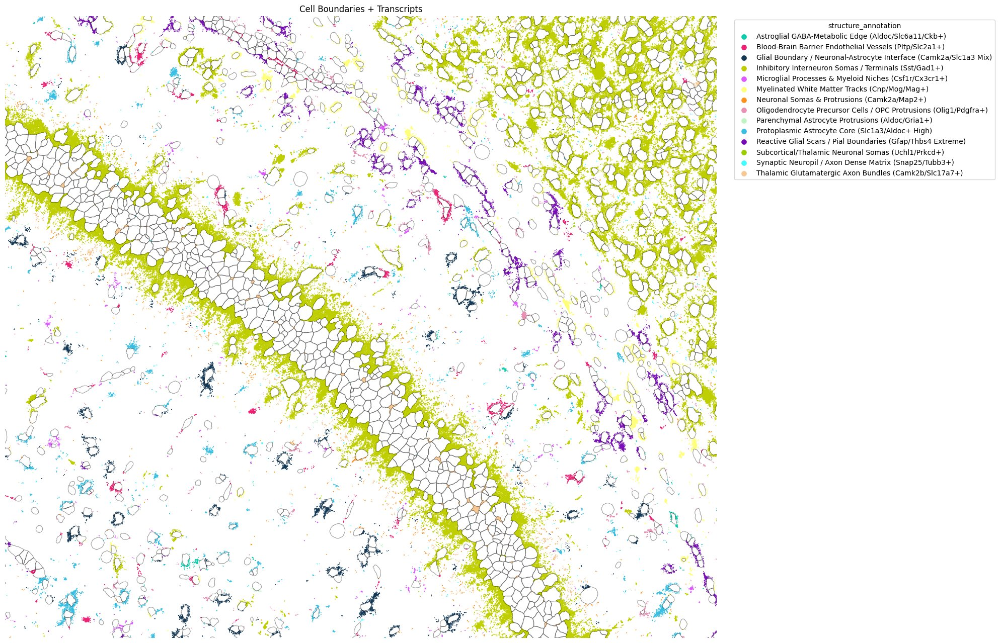

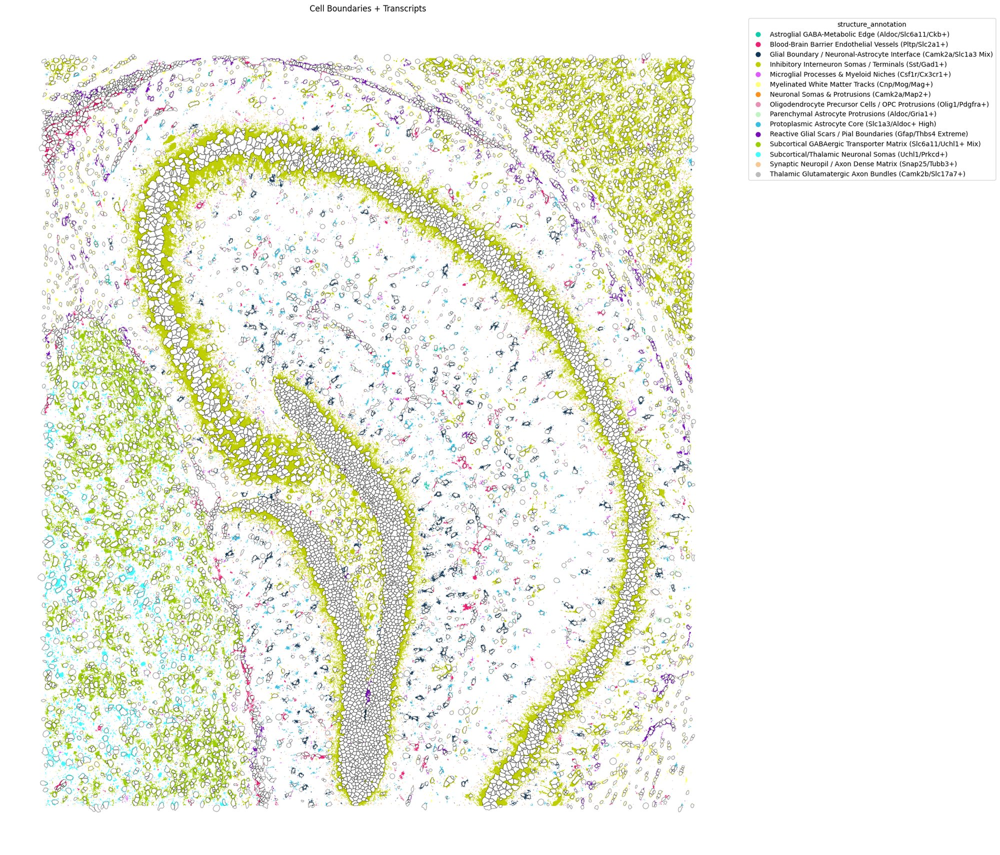

In [26]:
sdata['structure_table'].obs['structure_annotation']=sdata['structure_table'].obs['structure_annotation'].astype(str)
fig=pl.spatial_transcripts(
    sdata,
    color_key="structure_annotation",
    scatter_size=0.5,use_roi=True, roi=(4900, 5700, 2100, 2800),figsize=(20,20),boundary_linewidth=0.8,
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1)
plt.savefig(os.path.join(saving_path,'spatial_transcripts_structure_annotation_roi.pdf'))

sdata['structure_table'].obs['structure_annotation']=sdata['structure_table'].obs['structure_annotation'].astype(str)
fig=pl.spatial_transcripts(
    sdata,
    color_key="structure_annotation",
    scatter_size=0.1,use_roi=False,figsize=(20,20),boundary_linewidth=0.8,
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1)
plt.savefig(os.path.join(saving_path,'spatial_transcripts_structure_annotation.pdf'))

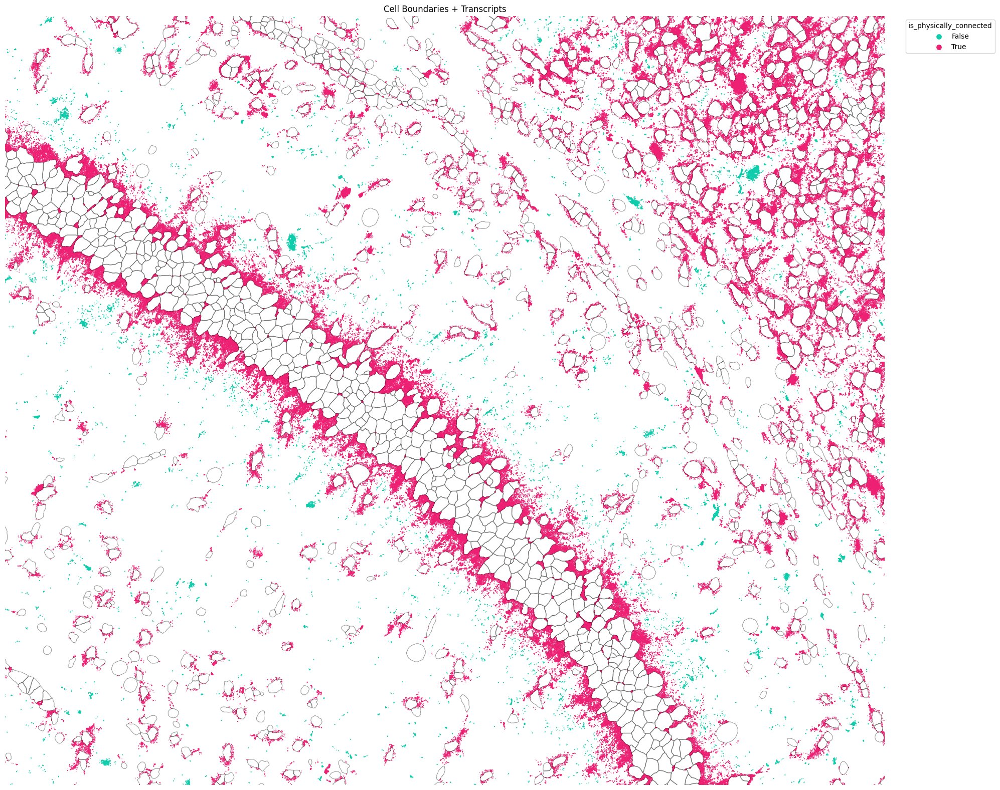

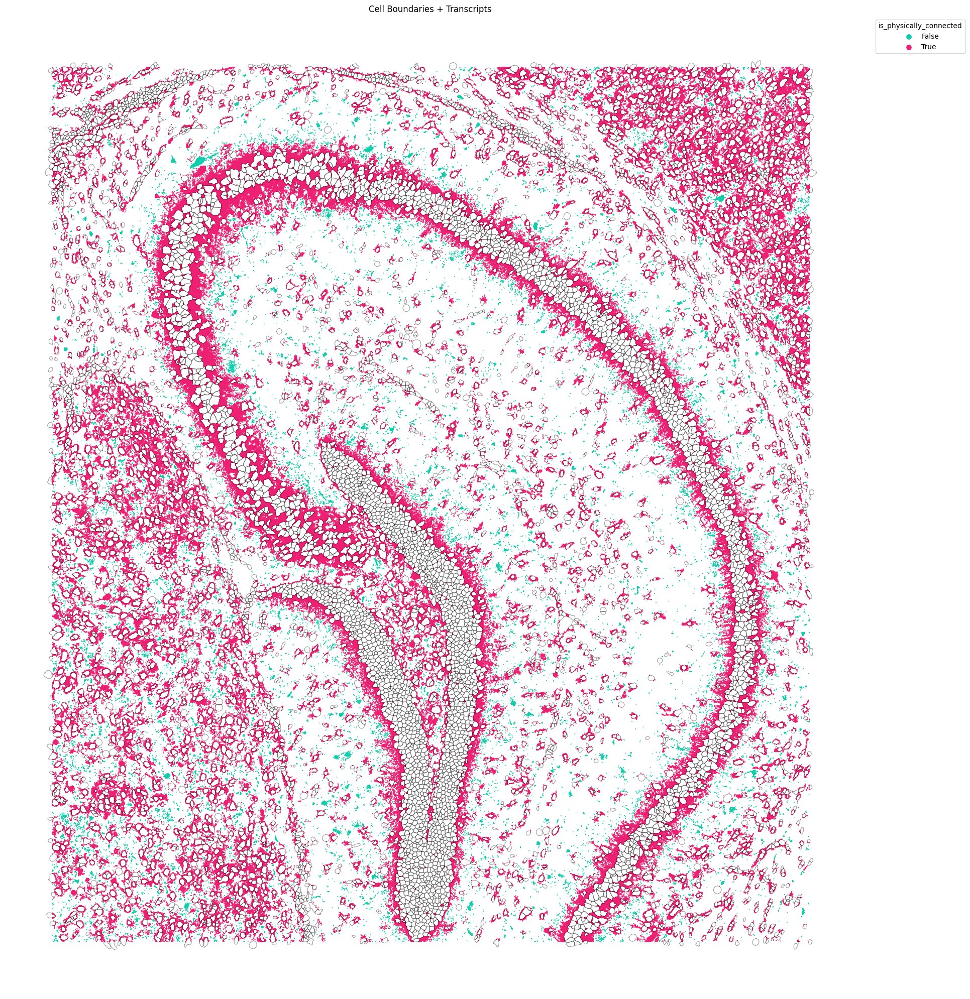

In [29]:
sdata['structure_table'].obs['structure_annotation']=sdata['structure_table'].obs['structure_annotation'].astype(str)
sdata['structure_table'].obs['is_physically_connected']=sdata['structure_table'].obs['is_physically_connected'].astype(str)
fig=pl.spatial_transcripts(
    sdata,
    color_key="is_physically_connected",
    scatter_size=0.6,use_roi=True, roi=(4900, 5700, 2100, 2800),figsize=(20,20),boundary_linewidth=0.8,
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1,continuous_colormap='winter')
plt.savefig(os.path.join(saving_path,'spatial_transcripts_physically_connected_roi.pdf'))

sdata['structure_table'].obs['structure_annotation']=sdata['structure_table'].obs['structure_annotation'].astype(str)
sdata['structure_table'].obs['is_physically_connected']=sdata['structure_table'].obs['is_physically_connected'].astype(str)
fig=pl.spatial_transcripts(
    sdata,
    color_key="is_physically_connected",
    scatter_size=0.4,use_roi=False, roi=(4900, 5700, 2100, 2800),figsize=(20,20),boundary_linewidth=0.8,
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1,continuous_colormap='winter')
plt.savefig(os.path.join(saving_path,'spatial_transcripts_physically_connected.pdf'))


Processing Region 1/10 | Target Index: struct_8
 -> Score: 0.4120 | Total Transcripts: 725603 | (Inhibitory Interneuron Somas / Terminals (Sst/Gad1+))
 -> Local High-Expression Feature Match: 'Camk2a' (0.08829019218683243 counts)


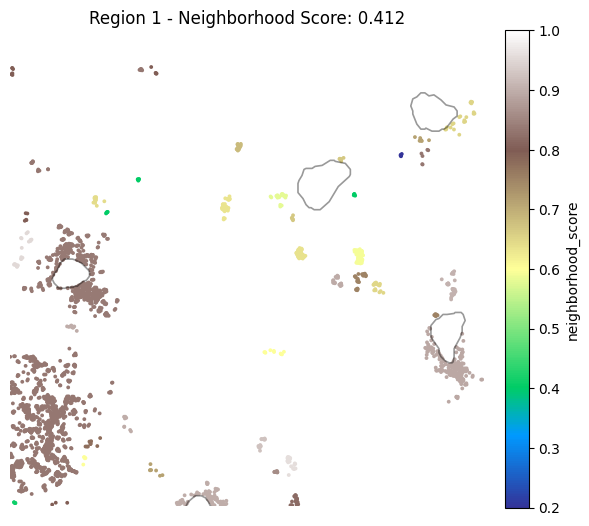

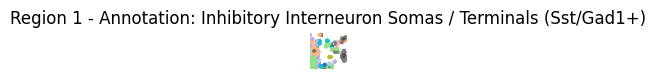

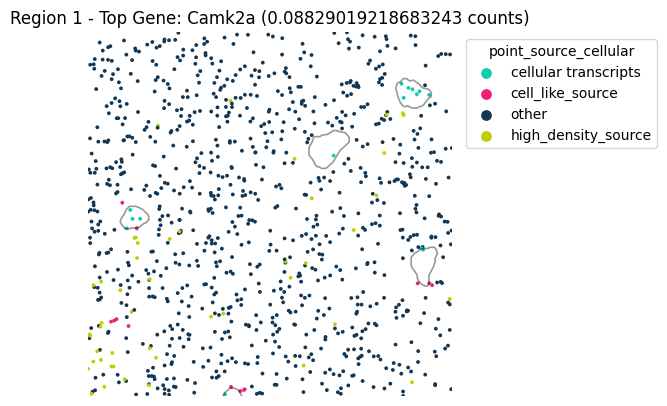


Processing Region 2/10 | Target Index: struct_29789
 -> Score: 0.5238 | Total Transcripts: 23 | (Protoplasmic Astrocyte Core (Slc1a3/Aldoc+ High))
 -> Local High-Expression Feature Match: 'Celsr1' (0.4559532105922699 counts)


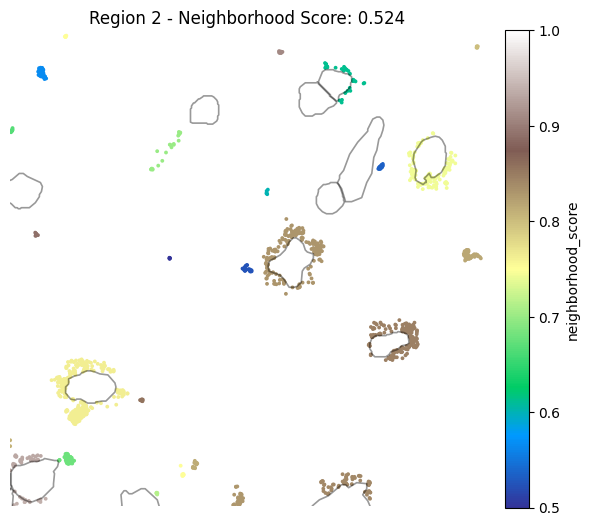

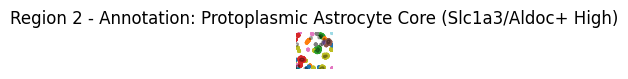

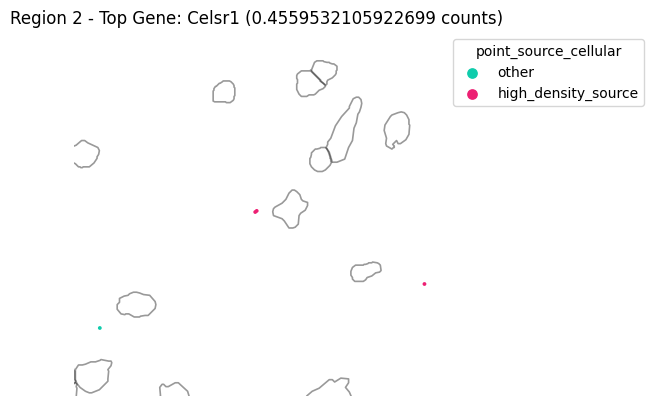


Processing Region 3/10 | Target Index: struct_0
 -> Score: 0.5439 | Total Transcripts: 422800 | (Inhibitory Interneuron Somas / Terminals (Sst/Gad1+))
 -> Local High-Expression Feature Match: 'Snap25' (0.06637424230575562 counts)


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7ff4db7443d0>>
Traceback (most recent call last):
  File "/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


KeyboardInterrupt: 

In [50]:
import numpy as np
import os
import matplotlib.pyplot as plt

# --- CONFIGURATION ---
n_regions = 10
half_side = 100 / 2  # Creates a 100x100 window bounding box
figsize_val = (6, 6) # Smaller, more compact figure window size
dot_size = 5.0       # Increased from 2.5 for better spot visibility

# Setup the specific subfolder path
output_subfolder = os.path.join(saving_path, 'low_neighborhood_analysis')
os.makedirs(output_subfolder, exist_ok=True)

# Force clean types and pull working copies
obs_df = sdata['structure_table'].obs.copy()
sdata['structure_table'].obs['neighborhood_score'] = obs_df['neighborhood_score'].astype(float)
sdata['structure_table'].obs['structure_annotation'] = obs_df['structure_annotation'].astype(str)

# 1. Filter targets: Must have at least 20 counts, then select the 10 lowest neighborhood scores
filtered_df = obs_df[(obs_df['n_transcripts'] >= 20) & (obs_df['neighborhood_score'].notna())]
low_score_indices = filtered_df['neighborhood_score'].nsmallest(n_regions).index

# --- ITERATIVE COHORT PROCESSING ---
for i, target_idx in enumerate(low_score_indices):
    low_score_val = obs_df.loc[target_idx, 'neighborhood_score']
    annotation_name = obs_df.loc[target_idx, 'structure_annotation']
    total_transcripts = obs_df.loc[target_idx, 'n_transcripts']
    
    print(f"\nProcessing Region {i+1}/{len(low_score_indices)} | Target Index: {target_idx}")
    print(f" -> Score: {low_score_val:.4f} | Total Transcripts: {total_transcripts} | ({annotation_name})")
    
    # 2. Extract Center Coordinates
    if 'spatial' in sdata['structure_table'].obsm:
        coords = sdata['structure_table'].obsm['spatial']
        if hasattr(coords, 'loc'):
            center_x, center_y = coords.loc[target_idx].iloc[0], coords.loc[target_idx].iloc[1]
        else:
            pos = obs_df.index.get_loc(target_idx)
            center_x, center_y = coords[pos][0], coords[pos][1]
    elif 'x' in obs_df.columns and 'y' in obs_df.columns:
        center_x, center_y = obs_df.loc[target_idx, 'x'], obs_df.loc[target_idx, 'y']
    else:
        print(f"Skipping index {target_idx}: Spatial coordinates missing.")
        continue

    # Define ROI bounding window coordinates
    target_roi = (center_x - half_side, center_x + half_side, center_y - half_side, center_y + half_side)

    # 3. Find Top Expressed Gene Specially Linked inside this Structural Row Entry
    pos_idx = obs_df.index.get_loc(target_idx)
    if hasattr(sdata['structure_table'].X, "toarray"):
        expression_vector = sdata['structure_table'].X[pos_idx, :].toarray().flatten()
    else:
        expression_vector = sdata['structure_table'].X[pos_idx, :].flatten()
        
    top_gene_feature_idx = np.argmax(expression_vector)
    top_gene_name = sdata['structure_table'].var_names[top_gene_feature_idx]
    max_count = expression_vector[top_gene_feature_idx]
    print(f" -> Local High-Expression Feature Match: '{top_gene_name}' ({max_count} counts)")

    # --- Plot 1: Neighborhood Score Gradient ---
    fig, ax = pl.spatial_transcripts(
        sdata, color_key="neighborhood_score", scatter_size=dot_size, use_roi=True, roi=target_roi,
        figsize=figsize_val, boundary_linewidth=1.2, alpha=1, rasterize=True, missing_val_sentinel=-1, 
        continuous_colormap='terrain', title=f"Region {i+1} - Neighborhood Score: {low_score_val:.3f}"
    )
    plt.savefig(os.path.join(output_subfolder, f"region_{i+1}_id_{target_idx}_1_neighborhood_score.pdf"), bbox_inches='tight')
    plt.show()
    plt.close()

    # --- Plot 2: Structure Annotation (Legend Completely Blocked Internally) ---
    fig, ax = pl.spatial_transcripts(
        sdata, color_key="structure_annotation", scatter_size=dot_size, use_roi=True, roi=target_roi,
        figsize=figsize_val*5, boundary_linewidth=1.2, alpha=1, rasterize=True, missing_val_sentinel=-1,
        colormap='none',  # Stops troutpy from building a giant palette/legend that squishes the axis
        title=f"Region {i+1} - Annotation: {annotation_name}"
    )
    
    # Cleanup any residual empty legend frames just in case
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    for lgd in fig.legends:
        lgd.remove()
            
    plt.savefig(os.path.join(output_subfolder, f"region_{i+1}_id_{target_idx}_2_structure_annotation.pdf"), bbox_inches='tight')
    plt.show()
    plt.close()

    # --- Plot 3: Target Gene Expression Map ---
    fig, ax = pl.spatial_transcripts(
        sdata, 
        gene_list=[top_gene_name],           # Filters down explicitly to just show this targeted gene
        color_key="point_source_cellular",   # Standard discrete background vs cell status colors
        scatter_size=dot_size, use_roi=True, roi=target_roi,
        figsize=figsize_val, boundary_linewidth=1.2, alpha=1, rasterize=True, missing_val_sentinel=-1,
        title=f"Region {i+1} - Top Gene: {top_gene_name} ({max_count} counts)"
    )
    plt.savefig(os.path.join(output_subfolder, f"region_{i+1}_id_{target_idx}_3_top_gene_{top_gene_name}.pdf"), bbox_inches='tight')
    plt.show()
    plt.close()
    
print(f"\nDone! All processed outputs are saved inside subfolder: '{output_subfolder}'")

- spatial crops (connected, low neigh score analysis,structure label)
- multimodal analysis
- 

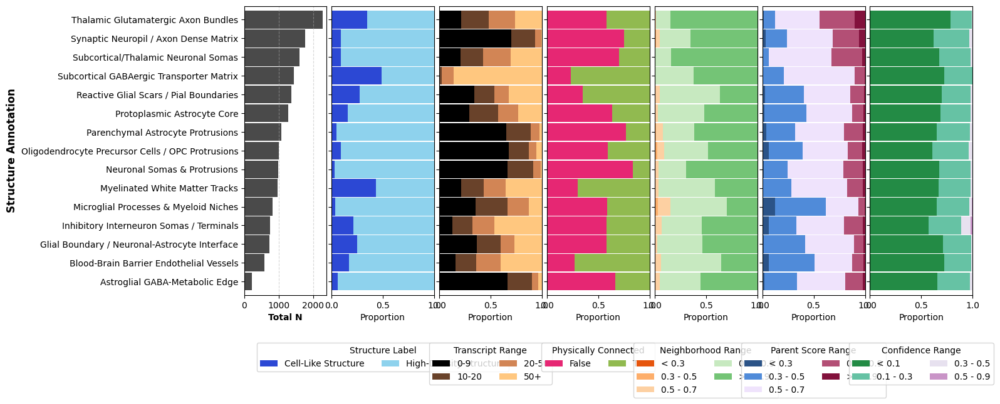

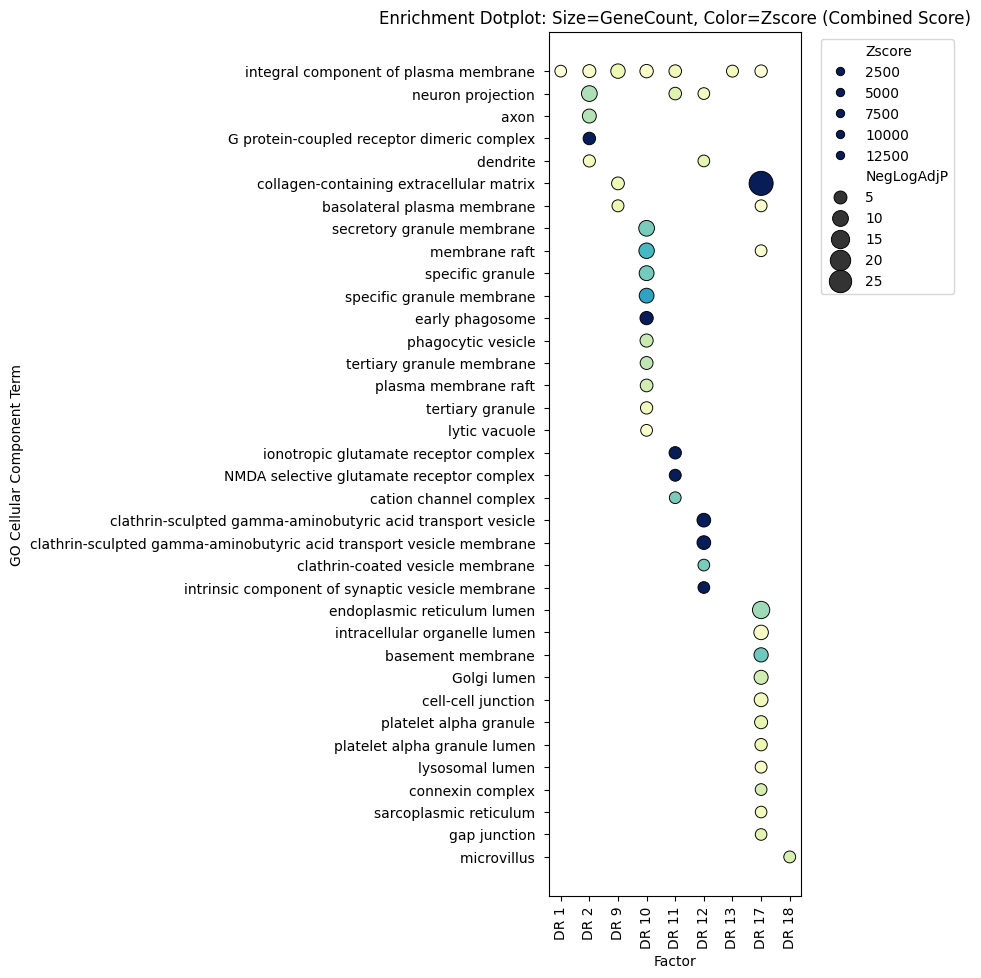

In [14]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize, TwoSlopeNorm
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import box
from shapely.affinity import affine_transform

def spatial_transcripts_structures(
    sdata, 
    color_key: str = "leiden",            
    gene_list: str | list[str] | None = None, 
    gene_key: str = "gene",                
    use_roi: bool = False,
    roi: tuple[float, float, float, float] | None = None, 
    padding: float = 0,           
    point_size: float = 0.1, 
    fig_bg_color: str = 'white', 
    ambient_color: str = 'lightgrey', 
    palette: str | None = None,            
    shapes_key: str = "cell_boundaries",
    boundary_linewidth: float = 0.5,
    boundary_zorder: int = 4,
    axis_numbers: bool = False,
    table_key: str = "table",                   # Main cell table key
    structure_table_key: str = "structure_table" # Structure table key
):
    # --------------------------------------------------------------------------
    # 1. Resolve which table holds our metadata/DR keys and find the join key
    # --------------------------------------------------------------------------
    chosen_table_key = None
    id_column_needed = "structure_id"  # fallback default
    
    # Check structure_table first
    if structure_table_key in sdata.tables:
        st = sdata[structure_table_key]
        if color_key in st.obs.columns or ("drvi_dr_stats" in st.uns and color_key in st.uns["drvi_dr_stats"].get("title", pd.Series()).values):
            chosen_table_key = structure_table_key
            id_column_needed = "structure_id"

    # Check cell table second if not found in the structure table
    if chosen_table_key is None and table_key in sdata.tables:
        ct = sdata[table_key]
        if color_key in ct.obs.columns or ("drvi_dr_stats" in ct.uns and color_key in ct.uns["drvi_dr_stats"].get("title", pd.Series()).values):
            chosen_table_key = table_key
            # Cell tables map via cell_id if present in points, otherwise fallback to structure_id
            id_column_needed = "cell_id" if "cell_id" in sdata.points["transcripts"].columns else "structure_id"

    # Absolute fallback to maintain original structural behavior safely if completely missing
    if chosen_table_key is None:
        chosen_table_key = structure_table_key
        id_column_needed = "structure_id"

    # --------------------------------------------------------------------------
    # 2. Fetch only the strictly required columns dynamically from Dask points
    # --------------------------------------------------------------------------
    required_cols = ['x', 'y', gene_key, id_column_needed]
    # Keep only the tracking identifiers that exist in the underlying point dataframe
    available_cols = [c for c in required_cols if c in sdata.points["transcripts"].columns]
    transcripts_lazy = sdata.points["transcripts"][available_cols]
    
    if gene_list is not None:
        if isinstance(gene_list, str):
            gene_list = [gene_list]
        transcripts_lazy = transcripts_lazy[transcripts_lazy[gene_key].isin(gene_list)]

    all_transcripts = transcripts_lazy.compute()
    all_transcripts.index = all_transcripts.index.astype(int)
    
    if all_transcripts.empty:
        print("No transcripts found matching selection criteria.")
        return None, None

    # --------------------------------------------------------------------------
    # 3. Extract Metadata / DR Expression Matrices
    # --------------------------------------------------------------------------
    active_table = sdata[chosen_table_key]
    table_obs = active_table.obs
    
    is_dr = False
    is_numeric = False
    
    if color_key in table_obs.columns:
        structure_values = table_obs[color_key]
        is_numeric = pd.api.types.is_numeric_dtype(structure_values)
    elif "drvi_dr_stats" in active_table.uns:
        dr_stats = active_table.uns["drvi_dr_stats"]
        if "title" in dr_stats.columns and color_key in dr_stats["title"].values:
            dr_idx = list(dr_stats["title"].values).index(color_key)
            dr_vector = active_table.obsm["X_drvi"][:, dr_idx]
            structure_values = pd.Series(dr_vector, index=table_obs.index)
            is_dr = True
            is_numeric = True
        else:
            raise KeyError(f"'{color_key}' not found in {chosen_table_key}.obs columns or drvi_dr_stats titles.")
    else:
        raise KeyError(f"'{color_key}' not found in {chosen_table_key}.obs and no DR metadata is initialized.")

    # --------------------------------------------------------------------------
    # 4. Perform Transcript-to-Table Index Linkage
    # --------------------------------------------------------------------------
    df_roi = all_transcripts.copy()
    
    # --- FIX CRITICAL VALUE ERROR ---
    # Coerce any non-numeric labels like 'UNASSIGNED' to NaN, then cast safely to integer -1
    numeric_ids = pd.to_numeric(df_roi[id_column_needed], errors='coerce').fillna(-1).astype(int)
    
    # Check if target table index uses prefixed strings (e.g. 'struct_12') or clean numeric indices
    sample_idx = str(table_obs.index[0])
    if sample_idx.startswith('struct_') and id_column_needed == 'structure_id':
        df_roi['lookup_key'] = 'struct_' + numeric_ids.astype(str)
    else:
        df_roi['lookup_key'] = numeric_ids.astype(str)
    
    is_assigned = (numeric_ids != -1) & (df_roi['lookup_key'].isin(table_obs.index))
    
    df_roi['color_value'] = np.nan
    df_roi.loc[is_assigned, 'color_value'] = df_roi.loc[is_assigned, 'lookup_key'].map(structure_values)

    # --------------------------------------------------------------------------
    # 5. Handle Viewport / Regions of Interest (ROI)
    # --------------------------------------------------------------------------
    if use_roi and roi is not None:
        x_min, x_max, y_min, y_max = roi
    elif padding > 0:
        x_min, x_max = df_roi['x'].min() + padding, df_roi['x'].max() - padding
        y_min, y_max = df_roi['y'].min() + padding, df_roi['y'].max() - padding
    else:
        x_min, x_max = df_roi['x'].min(), df_roi['x'].max()
        y_min, y_max = df_roi['y'].min(), df_roi['y'].max()

    df_roi = df_roi[df_roi.x.between(x_min, x_max) & df_roi.y.between(y_min, y_max)].copy()
    
    # Refresh tracking masks for inside the visual window
    numeric_ids_roi = pd.to_numeric(df_roi[id_column_needed], errors='coerce').fillna(-1).astype(int)
    is_assigned_roi = (numeric_ids_roi != -1) & (df_roi['lookup_key'].isin(table_obs.index))
    ambient_mask = ~is_assigned_roi

    # --------------------------------------------------------------------------
    # 6. Geometric Borders Processing
    # --------------------------------------------------------------------------
    gdf = None
    if shapes_key in sdata:
        cb = sdata[shapes_key]
        df_shapes = cb.copy()
        try:
            from spatialdata import get_transformation
            trans = get_transformation(cb)
            if hasattr(trans, "matrix") and trans.matrix is not None:
                m = trans.matrix 
                params = [m[0,0], m[0,1], m[1,0], m[1,1], m[0,2], m[1,2]]
                df_shapes["geometry"] = df_shapes["geometry"].apply(lambda g: affine_transform(g, params))
        except: 
            pass
            
        gdf = gpd.GeoDataFrame(df_shapes, geometry="geometry")
        roi_poly = box(x_min, y_min, x_max, y_max)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]

    # --------------------------------------------------------------------------
    # 7. Canvas Setup & Plotting Execution
    # --------------------------------------------------------------------------
    text_color = 'white' if fig_bg_color in ['black', '#000000', '#252525'] else 'black'
    fig, ax = plt.subplots(figsize=(20, 20), facecolor=fig_bg_color)
    ax.set_facecolor(fig_bg_color)

    # --- Plane A: Ambient Unassigned Scatter Plane ---
    ax.scatter(
        df_roi.loc[ambient_mask, 'x'], df_roi.loc[ambient_mask, 'y'], 
        c=ambient_color, s=point_size, alpha=0.15, edgecolors='none', zorder=0
    )

    # --- Plane B: Structurally Expressive Signal Render Layer ---
    assigned_df = df_roi[is_assigned_roi]
    
    if is_numeric:
        v_data = assigned_df['color_value'].astype(float)
        
        if is_dr:
            cmap_name = palette if palette else 'coolwarm'
            max_abs = max(abs(v_data.min()), abs(v_data.max()))
            norm = TwoSlopeNorm(vcenter=0.0, vmin=-max_abs if max_abs > 0 else -1, vmax=max_abs if max_abs > 0 else 1)
        else:
            cmap_name = palette if palette else 'viridis'
            norm = Normalize(vmin=v_data.min(), vmax=v_data.max())
            
        scatter = ax.scatter(
            assigned_df['x'], assigned_df['y'], 
            c=v_data, cmap=cmap_name, norm=norm, 
            s=point_size * 2, edgecolors='none', zorder=2
        )
        cbar = fig.colorbar(scatter, ax=ax, shrink=0.4, pad=0.02)
        cbar.ax.yaxis.set_tick_params(color=text_color, labelcolor=text_color)
        cbar.set_label(label=color_key, color=text_color, fontsize=12)
        cbar.outline.set_edgecolor(text_color)
        
    else:
        unique_cats = sorted(list(assigned_df['color_value'].dropna().unique()))
        cmap = plt.get_cmap(palette if palette else 'tab20')
        
        for i, cat in enumerate(unique_cats):
            cat_subset = assigned_df[assigned_df['color_value'] == cat]
            color = cmap(i / max(1, len(unique_cats) - 1))
            ax.scatter(
                cat_subset['x'], cat_subset['y'], 
                color=color, s=point_size * 2, 
                label=f"{cat}", edgecolors='none', zorder=2
            )
        ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), facecolor=fig_bg_color, 
                  edgecolor=text_color, labelcolor=text_color, markerscale=5)

    # --- Plane C: Vector Borders Overlays ---
    if gdf is not None and not gdf.empty:
        border_color = 'black' if fig_bg_color == 'white' else 'white'
        gdf.plot(
            ax=ax, facecolor="none", edgecolor=border_color, 
            linewidth=boundary_linewidth, alpha=0.35, zorder=boundary_zorder
        )

    # Clean Up Plot Decorators & Axis Toggle
    title_suffix = f" | Subsetting for {', '.join(gene_list)}" if gene_list is not None else ""
    ax.set_title(f"Assignments [{chosen_table_key}]: Feature mapping [{color_key}]{title_suffix}", color=text_color, fontsize=16)
    ax.set_aspect('equal')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    
    if axis_numbers:
        ax.axis('on')
        ax.tick_params(colors=text_color, labelsize=10)
        for spine in ax.spines.values():
            spine.set_color(text_color)
    else:
        ax.axis('off')
    
    return fig, ax

(<Figure size 2000x2000 with 1 Axes>,
 <Axes: title={'center': 'Assignments [table]: Feature mapping [cell_type]'}>)

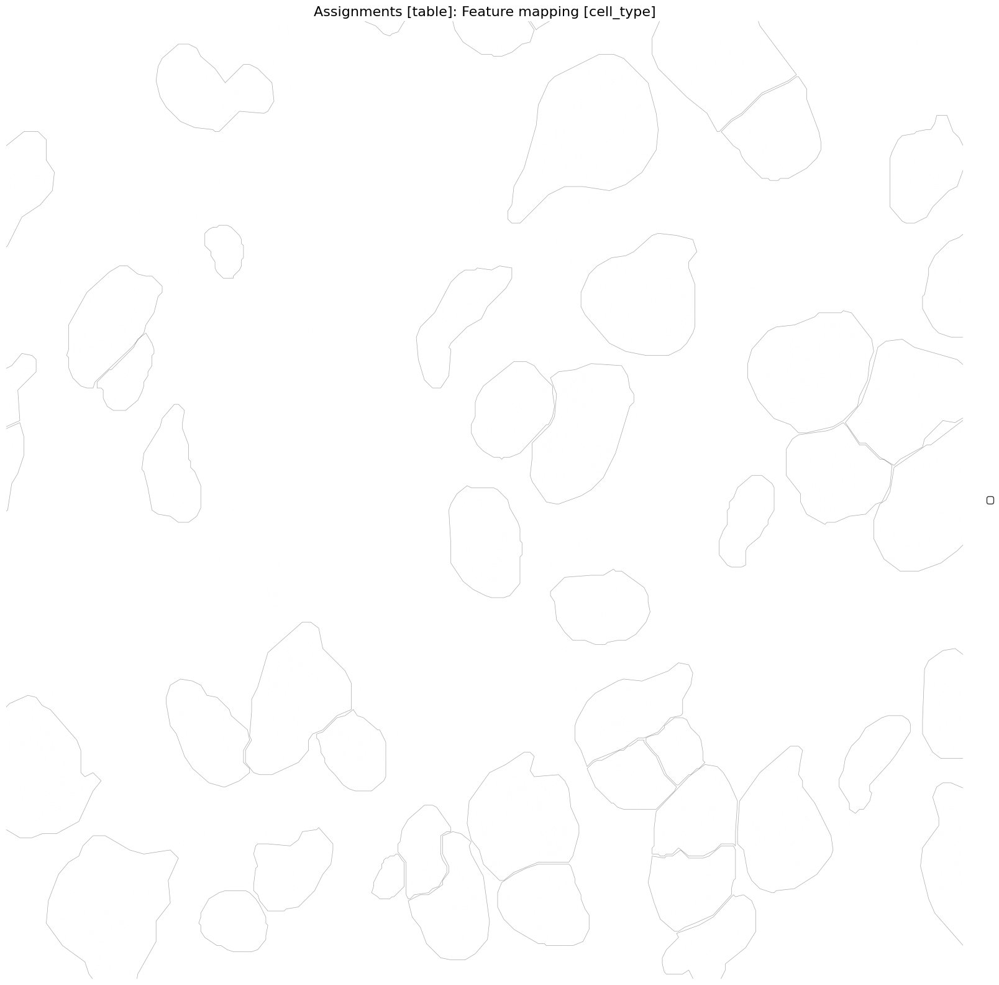

In [53]:
spatial_transcripts_structures(sdata,color_key='cell_type',use_roi=True, roi=target_roi) #(sdata

In [52]:
import gseapy as gp
neg_eff=traverse_adata.varm['combined_score_traverse_effect_neg'].loc[:,embed_filt.var.index]
pos_eff=traverse_adata.varm['combined_score_traverse_effect_pos'].loc[:,embed_filt.var.index]
pos_eff.columns=embed_filt.var['title']
neg_eff.columns=embed_filt.var['title']

records = []
threshold=1
# Collect enrichment data for all factors, preserving order

for dr in pos_eff.columns:
    print(dr)
    sel=pos_eff.index[pos_eff.loc[:,dr]>threshold]
    sel2=neg_eff.index[neg_eff.loc[:,dr]>threshold]
    top_genes=list(sel)+list(sel2)
    
    enr = gp.enrichr(
        gene_list=top_genes,
        gene_sets=['GO_Cellular_Component_2021'],
        organism='Mouse',
        outdir=None,
        cutoff=0.5
    )
    df = enr.results
    if df.empty:
        continue
    
    # Filter by significance threshold, e.g., adjusted p-value < 0.05
    sig_df = df[df['Adjusted P-value'] < 0.01].sort_values('Adjusted P-value').reset_index(drop=True)
    #df = df.sort_values('Adjusted P-value').head(5).reset_index(drop=True)
    
    # Only keep significant terms, no fixed number limit
    for order, row in sig_df.iterrows():
        records.append({
            'Factor': dr,
            'Term': row['Term'],
            'AdjP': row['Adjusted P-value'],
            'NegLogAdjP': -np.log10(row['Adjusted P-value']),
            'GeneCount': int(row['Overlap'].split('/')[0]),  # extract numerator of overlap "x/y"
            'Zscore': row['Combined Score'],
            'Order': order  # preserve order within factor
        })

AxisArrays with keys: gene_loadings_positive, gene_loadings_negative

In [ ]:
enrich_df=pd.DataFrame(records)

enrich_df=enrich_df[enrich_df['AdjP']<0.001]

simple_term=[term.split('(')[0] for term in enrich_df['Term']]
enrich_df['simple_term']=simple_term

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
from matplotlib.colors import Normalize

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Define vmax for Zscore coloring, e.g., cap at 10
vmax_value = 1000

norm = Normalize(vmin=enrich_df['Zscore'].min(), vmax=vmax_value)

plt.figure(figsize=(10, 0.2 * enrich_df.shape[0]))
scatter = sns.scatterplot(
    data=enrich_df,
    x='Factor',
    y='simple_term',
    size='NegLogAdjP',
    hue='Zscore',
    palette='YlGnBu',
    sizes=(70, 300),
    edgecolor='black',
    hue_norm=norm  # <-- this applies the normalization (vmax)
)

plt.xlabel('Factor')
plt.ylabel('GO Cellular Component Term')
plt.title('Enrichment Dotplot: Size=GeneCount, Color=Zscore (Combined Score)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(False)
plt.tight_layout()
plt.xticks(rotation=90)

plt.savefig(os.path.join(saving_path, 'gsea_compartment_brain.pdf'))
plt.show()


# Staining  Intestities

In [111]:
import pandas as pd
import scanpy as sc
import numpy as np

# 1. Pull down the transcript mapping information from Dask points
# We only load the structure assignment identifier to save memory
transcripts_df = sdata['transcripts'][['structure_id']].compute()

# 2. Extract the intensity values and staining channels from the AnnData object
intensity_adata = sdata['image_intensity_per_transcript']

# Handle sparse matrix conversions if .X is not a dense numpy array
if isinstance(intensity_adata.X, np.ndarray):
    intensities = intensity_adata.X
else:
    intensities = intensity_adata.X.toarray()

staining_channels = intensity_adata.var_names

# 3. Combine into a temporary DataFrame for aggregation
df_intensities = pd.DataFrame(intensities, columns=staining_channels)
df_intensities['structure_id'] = transcripts_df['structure_id'].values

# 4. Filter out unassigned transcripts (where structure_id == -1 or NaN)
df_assigned = df_intensities[df_intensities['structure_id'].astype(int) != -1]

# 5. Compute the mean intensity per structure across all stainings
# This creates a DataFrame where Index = structure_id, Columns = Staining Channels
mean_intensity_f = df_assigned.groupby('structure_id')[staining_channels].mean()

# 6. Align the results with sdata['structure_table'] to keep metadata intact
# This ensures even structures with no transcripts get a row (filled with NaNs or 0)

structure_metadata = sdata['structure_table'].obs[['urna_cluster']].copy()

# The structure table index is likely formatted as strings (e.g., 'struct_12')
# or purely numeric. We dynamically parse it to match the grouped integer IDs.
sample_idx = str(structure_metadata.index[0])
if sample_idx.startswith('struct_'):
    # Map back using 'struct_' prefix formatting
    mean_intensity_df.index = 'struct_' + mean_intensity_df.index.astype(int).astype(str)
else:
    mean_intensity_df.index = mean_intensity_df.index.astype(str)

# Combine the cluster metadata with the calculated mean intensities
final_structure_intensities = structure_metadata.join(mean_intensity_df, how='left')

# 7. Convert the structured result into a fresh AnnData object for sdata storage
intensity_per_structure_adata = sc.AnnData(
    X=final_structure_intensities[staining_channels].values,
    obs=final_structure_intensities[['urna_cluster']],
    var=pd.DataFrame(index=staining_channels)
)

# 8. Save directly to your SpatialData object
sdata['intensity_per_structure'] = intensity_per_structure_adata

print(f"Successfully saved mean intensities for {intensity_per_structure_adata.n_obs} structures.")
print(f"Shape of stored data: {sdata['intensity_per_structure'].shape}")

0      0.000000
1      6.450787
2      0.000000
3      0.000000
4      0.000000
         ...   
123    0.000000
124    0.000000
125    0.000000
126    0.000000
127    0.000000
Length: 128, dtype: float64

Computed background baseline from 50000 non-overlapping transcripts.
Custom background-referenced Z-scores updated inside sdata['intensity_per_structure'].layers['bg_zscore']


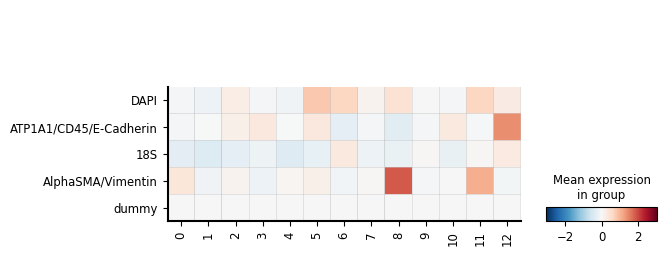

In [46]:
import pandas as pd
import scanpy as sc
import numpy as np

# ==============================================================================
# 1. FETCH TRANSCRIIPT METADATA AND INTENSITIES
# ==============================================================================
# Load structure assignments and cellular overlap flags from Dask points
transcripts_df = sdata['transcripts'][['structure_id', 'overlaps_cell']].compute()
intensity_adata = sdata['image_intensity_per_transcript']

# Handle sparse vs dense arrays safely
if isinstance(intensity_adata.X, np.ndarray):
    intensities = intensity_adata.X
else:
    intensities = intensity_adata.X.toarray()

staining_channels = intensity_adata.var_names

# Create our base calculation dataframe
df_trans = pd.DataFrame(intensities, columns=staining_channels)
df_trans['structure_id'] = transcripts_df['structure_id'].values
df_trans['overlaps_cell'] = transcripts_df['overlaps_cell'].values

# ==============================================================================
# 2. SAMPLE BACKGROUND TRANSCRIPTS FOR BASELINE STATISTICS
# ==============================================================================
# Filter for transcripts that strictly do not overlap a cell body boundary
bg_pool = df_trans[df_trans['overlaps_cell'].astype(str).str.lower() == 'false']

# Extract a random representative subset (e.g., up to 50,000 transcripts) to define the baseline
sample_size = min(50000, len(bg_pool))
bg_sample = bg_pool.sample(n=sample_size, random_state=42)

# Compute baseline background mean and standard deviation for every channel
bg_means = bg_sample[staining_channels].mean()
bg_stds = bg_sample[staining_channels].std().replace(0, 1) # Prevent division by zero

print(f"Computed background baseline from {sample_size} non-overlapping transcripts.")

# ==============================================================================
# 3. COMPUTE MEAN RAW INTENSITY PER STRUCTURE
# ==============================================================================
df_assigned = df_trans[df_trans['structure_id'].astype(int) != -1]
mean_intensity_df = df_assigned.groupby('structure_id')[staining_channels].mean()

# Align structural IDs with the structure table index
structure_metadata = sdata['structure_table'].obs[['urna_cluster']].copy()
sample_idx = str(structure_metadata.index[0])

if sample_idx.startswith('struct_'):
    mean_intensity_df.index = 'struct_' + mean_intensity_df.index.astype(int).astype(str)
else:
    mean_intensity_df.index = mean_intensity_df.index.astype(str)

final_raw_df = structure_metadata.join(mean_intensity_df, how='left')
raw_matrix = final_raw_df[staining_channels].values

# ==============================================================================
# 4. TRANSLATE RAW VALUES INTO BACKGROUND Z-SCORES
# ==============================================================================
# Broad-cast subtract background mean and divide by background standard deviation
z_score_matrix = (raw_matrix - bg_means.values) / bg_stds.values

# Save back to your intensity_per_structure AnnData object
sdata['intensity_per_structure'].X = raw_matrix  # keeps raw values intact in default slot
sdata['intensity_per_structure'].layers['bg_zscore'] = z_score_matrix  # stores custom z-scores

print("Custom background-referenced Z-scores updated inside sdata['intensity_per_structure'].layers['bg_zscore']")

# ==============================================================================
# 5. MATRIXPLOT VISUALIZATION
# ==============================================================================
# Plot the computed z-score layer directly
sc.pl.matrixplot(
    sdata['intensity_per_structure'],
    var_names=sdata['intensity_per_structure'].var.index,
    groupby='urna_cluster',
    swap_axes=True,
    layer='bg_zscore',      # <--- Direct Scanpy to plot your calculated Z-score matrix layer
    cmap='RdBu_r',          # <--- Symmetrical color split: Red = enriched over background, Blue = lower than background
    vmin=-3, vmax=3         # <--- Centered at 0; limits visualization range to +/- 3 standard deviations
)

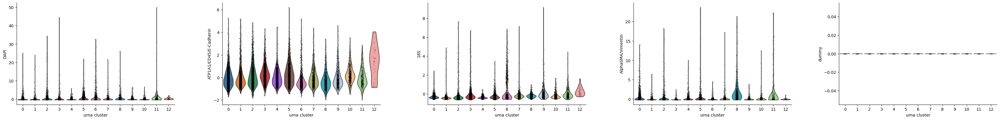

In [51]:
sc.pl.violin(
    sdata['intensity_per_structure'],
    keys=sdata['intensity_per_structure'].var.index,
    groupby='urna_cluster',
    layer='bg_zscore',      # <--- Direct Scanpy to plot your calculated Z-score matrix layer
    cmap='RdBu_r',          # <--- Symmetrical color split: Red = enriched over background, Blue = lower than background
)

NameError: name 'saving_path' is not defined

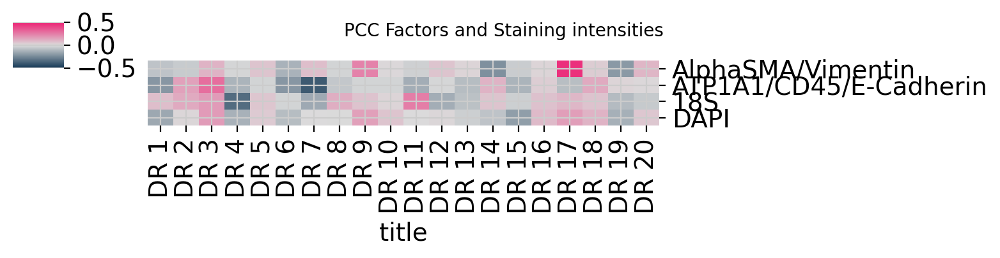

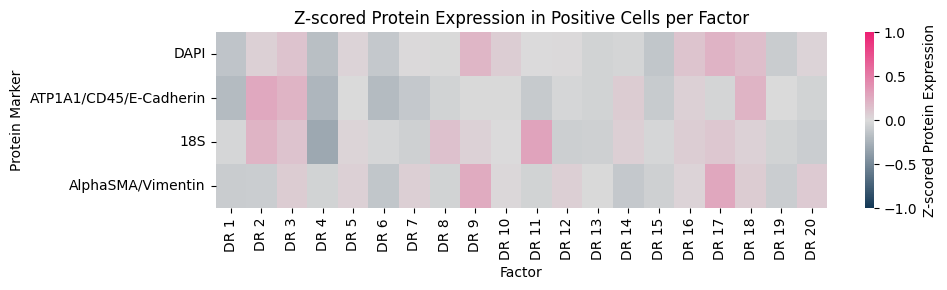

In [81]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import scale

# Set threshold for selecting positive cells
threshold = 0.1  # Adjust if needed

approximated_adata=approximated_adata[:,~approximated_adata.var.index.isin(['dummy'])]
# Compute global mean protein expression (across all cells)
global_means = np.asarray(approximated_adata.X.mean(axis=0)).ravel()

# Compute per-factor mean expression for positive cells
mean_exprs = []
valid_factors = []

for factor in factor_loadings.columns:
    positive_cells = factor_loadings[factor] > threshold
    if positive_cells.sum() == 0:
        continue
    mean_expr = np.asarray(approximated_adata.X[positive_cells, :]).mean(axis=0)
    mean_exprs.append(mean_expr)
    valid_factors.append(factor)

# Build DataFrame of mean expressions
mean_exprs_df = pd.DataFrame(mean_exprs, index=valid_factors, columns=approximated_adata.var_names)

# Remove 'dummy' markers if present
mean_exprs_df = mean_exprs_df.loc[:, ~mean_exprs_df.columns.isin(['dummy'])]
global_means = pd.Series(global_means, index=approximated_adata.var_names)
global_means = global_means[mean_exprs_df.columns]  # align columns

# ==== Z-score per marker ====
zscored_df = (mean_exprs_df - global_means) / np.std(approximated_adata.X, axis=0)

# Plot heatmap (choose either DataFrame)
plt.figure(figsize=(10, 3))
sns.heatmap(
    zscored_df.transpose(),  # or mean_centered_df
    cmap=troutpy.pl.get_colormap('BuPi'),
    center=0,
    cbar_kws={"label": "Z-scored Protein Expression"}, vmax=1, vmin=-1
)
plt.ylabel("Protein Marker")
plt.xlabel("Factor")
plt.title("Z-scored Protein Expression in Positive Cells per Factor")
plt.tight_layout()
plt.grid(False)
plt.savefig(os.path.join(saving_path, 'protein_expression_contextualized_msbrain_zscore.pdf'))
plt.show()


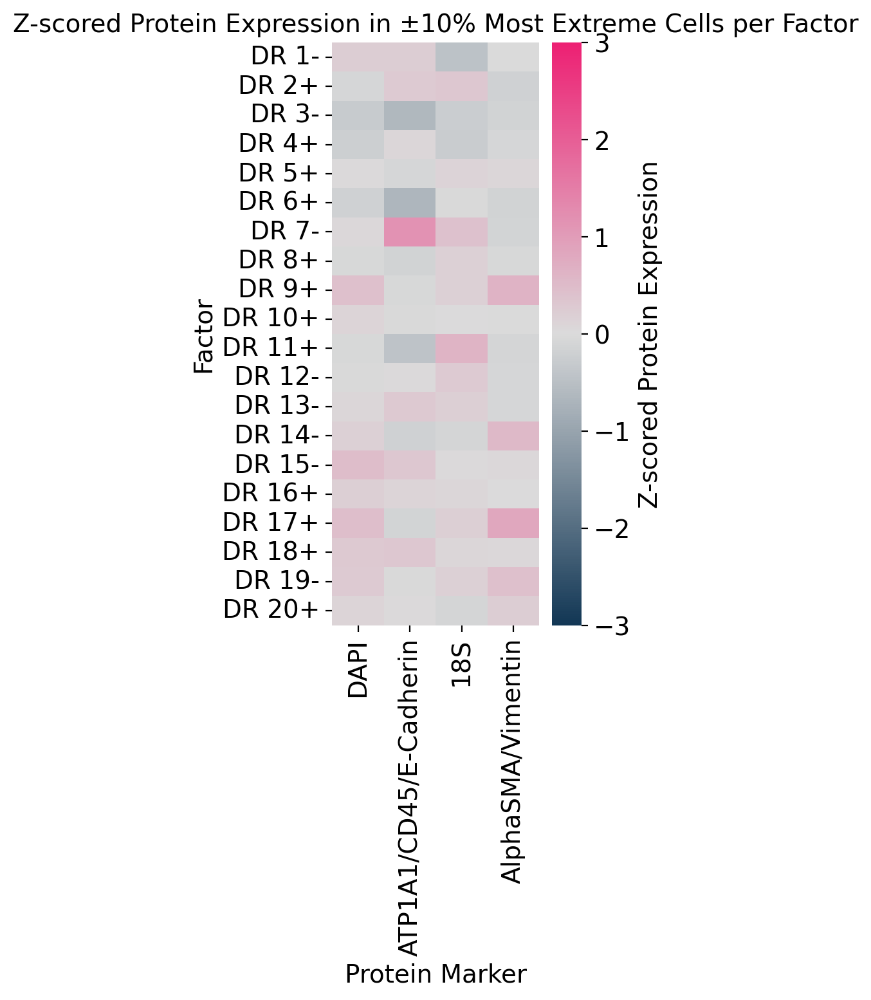

Saved factor directions to: results/factor_directions.csv


In [42]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import scale

# ===============================
# Parameters
# ===============================
top_fraction = 0.1  # Select top 10% of most extreme cells per factor
saving_path = "results"  # change as needed

os.makedirs(saving_path, exist_ok=True)

# Remove 'dummy' markers if present
approximated_adata = approximated_adata[:, ~approximated_adata.var.index.isin(['dummy'])]

# Compute global mean protein expression (across all cells)
global_means = np.asarray(approximated_adata.X.mean(axis=0)).ravel()

# ===============================
# Compute per-factor mean expression for most extreme cells
# ===============================
mean_exprs = []
valid_factors = []
factor_directions = {}

for factor in factor_loadings.columns:
    loadings = factor_loadings[factor]
    n_cells = len(loadings)
    
    # Compute mean positive and negative loadings
    pos_mean = loadings[loadings > 0].mean() if (loadings > 0).any() else 0
    neg_mean = loadings[loadings < 0].mean() if (loadings < 0).any() else 0
    
    # Determine dominant direction (absolute value comparison)
    if abs(pos_mean) >= abs(neg_mean):
        direction = "+"
        n_select = max(1, int(n_cells * top_fraction))
        selected_cells = loadings.nlargest(n_select).index
    else:
        direction = "-"
        n_select = max(1, int(n_cells * top_fraction))
        selected_cells = loadings.nsmallest(n_select).index
    
    factor_directions[factor] = direction
    
    # Add direction to factor name with + or -
    factor_name = f"{factor}{direction}"

    # Convert to boolean mask aligned with adata.obs_names
    selected_mask = approximated_adata.obs_names.isin(selected_cells)
    
    # Compute mean expression for selected cells
    mean_expr = np.asarray(approximated_adata.X[selected_mask, :]).mean(axis=0)
    mean_exprs.append(mean_expr)
    valid_factors.append(factor_name)

# ===============================
# Build DataFrame of mean expressions
# ===============================
mean_exprs_df = pd.DataFrame(mean_exprs, index=valid_factors, columns=approximated_adata.var_names)

# Remove 'dummy' markers if present
mean_exprs_df = mean_exprs_df.loc[:, ~mean_exprs_df.columns.isin(['dummy'])]

# Align global means
global_means = pd.Series(global_means, index=approximated_adata.var_names)
global_means = global_means[mean_exprs_df.columns]

# ===============================
# Z-score per marker
# ===============================
zscored_df = (mean_exprs_df - global_means) / np.std(approximated_adata.X, axis=0)

# ===============================
# Plot heatmap
# ===============================

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
from matplotlib.colors import Normalize

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
plt.figure(figsize=(4, 8))
sns.heatmap(
    zscored_df,
    cmap=troutpy.pl.get_colormap('BuPi'),
    center=0,
    cbar_kws={"label": "Z-scored Protein Expression"},
    vmax=3, vmin=-3
)
plt.xlabel("Protein Marker")
plt.ylabel("Factor")
plt.title(f"Z-scored Protein Expression in ±{int(top_fraction*100)}% Most Extreme Cells per Factor")
plt.tight_layout()
plt.grid(False)

# Save figure
plt.savefig(os.path.join(saving_path, 'protein_expression_contextualized_msbrain_zscore_2.pdf'))
plt.show()

# ===============================
# Save factor directions for interpretation
# ===============================
factor_directions_df = pd.DataFrame.from_dict(factor_directions, orient="index", columns=["direction"])
factor_directions_df.to_csv(os.path.join(saving_path, "factor_directions.csv"))
print("Saved factor directions to:", os.path.join(saving_path, "factor_directions.csv"))


In [34]:
os.path.join(saving_path, 'protein_expression_contextualized_msbrain_zscore_2.pdf')

'results/protein_expression_contextualized_msbrain_zscore_2.pdf'

In [35]:
saving_path

'results'

In [7]:
from matplotlib.colors import ListedColormap, Normalize
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.affinity import affine_transform
from shapely.geometry import box
import numpy as np
import pandas as pd


def spatial_transcripts(
    sdata: SpatialData,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "transcript_type",
    shapes_key: str = "cell_boundaries",
    colormap: str = "30colors",
    boundary_linewidth: float = 0.5,
    scatter_size: float = 1.0,
    alpha: float = 0.8,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
) -> tuple[plt.Figure, plt.Axes]:
    """
    Plot cell boundary polygons and transcript points, colored by a categorical variable
    or a numeric variable, scaling geometries by an affine matrix from get_transformation.

    Parameters
    ----------
    sdata
        A SpatialData object containing:
          - sdata[shapes_key]  including a 'geometry' column of shapely Polygons
          - sdata['transcripts'] including `gene_key` and `color_key`
    gene_key: str
        Column in transcripts to filter by gene_list.
    gene_list: Optional[List[str]]
        List of genes to keep. If None, all transcripts are used.
    color_key: str
        Column in transcripts used for coloring points. Can be categorical or numeric.
    shapes_key: str
        Key in sdata for your polygon boundaries layer.
    colormap: str
        Name of a Matplotlib colormap or troutpy palette name.
    boundary_linewidth: float
        Line width of cell boundary outlines.
    scatter_size: float
        Marker size for transcript points.
    alpha: float
        Transparency for transcript points.
    use_roi: bool
        If True, restrict both polygons and points to the bounding box given by `roi`.
    roi: Tuple[float, float, float, float]
        (xmin, xmax, ymin, ymax) bounds to clip to when `use_roi=True`.
    figsize: Tuple[float, float]
        Width and height of the figure.
    title: str
        Title string placed above the plot.

    Returns
    -------
    fig, ax
        The Matplotlib figure and axes objects.
    """
    # 1) Filter transcripts by gene_list
    trans_ad = sdata["transcripts"].compute()
    if gene_list is not None:
        trans_ad = trans_ad[trans_ad[gene_key].isin(gene_list)]

    # annotate transcript types
    trans_ad["segstatus"] = trans_ad["overlaps_cell"].astype(str) + "_" + trans_ad["extracellular"].astype(str)
    stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}
    trans_ad["transcript_type"] = trans_ad["segstatus"].map(stat2lab)

    # 2) Prepare color values based on type (categorical or numeric)
    trans_df = trans_ad.copy()
    if pd.api.types.is_numeric_dtype(trans_df[color_key]):
        is_numeric = True
        color_values = trans_df[color_key].astype(float)
        cmap = plt.get_cmap(colormap)
        norm = Normalize(vmin=color_values.min(), vmax=color_values.max())
    else:
        is_numeric = False
        cats = trans_df[color_key].astype("category")
        color_values = cats.cat.codes.values
        n_cats = len(cats.cat.categories)
        try:
            import troutpy
            pal = troutpy.pl.get_palette(colormap, n_cats)
            cmap = ListedColormap(pal)
        except Exception:
            cmap = plt.get_cmap(colormap, n_cats)

    # 3) Obtain affine transformation and apply to geometries and points
    cb = sdata[shapes_key]
    df = cb.copy()
    trans = get_transformation(cb)
    
    if hasattr(trans, "matrix") and trans.matrix is not None:
        try:
            matrix = trans.matrix  # expected 3x3 or 2x3 affine
            a, b, xoff = matrix[0]
            d, e, yoff = matrix[1]
            params = [a, b, d, e, xoff, yoff]
            df["geometry"] = df["geometry"].apply(lambda geom: affine_transform(geom, params))
        except Exception as e:
            print(f"Transformation could not be applied: {e}")
    else:
        print("No transformation matrix found. Proceeding without transformation.")

    gdf = gpd.GeoDataFrame(df, geometry="geometry", crs=None)

    # 4) Optionally clip to ROI
    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        color_values = color_values[mask]  # mask color values too

    # 5) Plot
    fig, ax = plt.subplots(figsize=figsize)
    gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=boundary_linewidth)
    scatter = ax.scatter(
        trans_df["x"],
        trans_df["y"],
        c=color_values,
        cmap=cmap,
        s=scatter_size,
        edgecolor="none",
        alpha=alpha,
        norm=norm if is_numeric else None,
    )

    # 6) Legend or colorbar
    if is_numeric:
        cbar = fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
    else:
        for idx, cat in enumerate(cats.cat.categories):
            ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
        ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax


In [8]:
print('hi')

hi


No transformation matrix found. Proceeding without transformation.


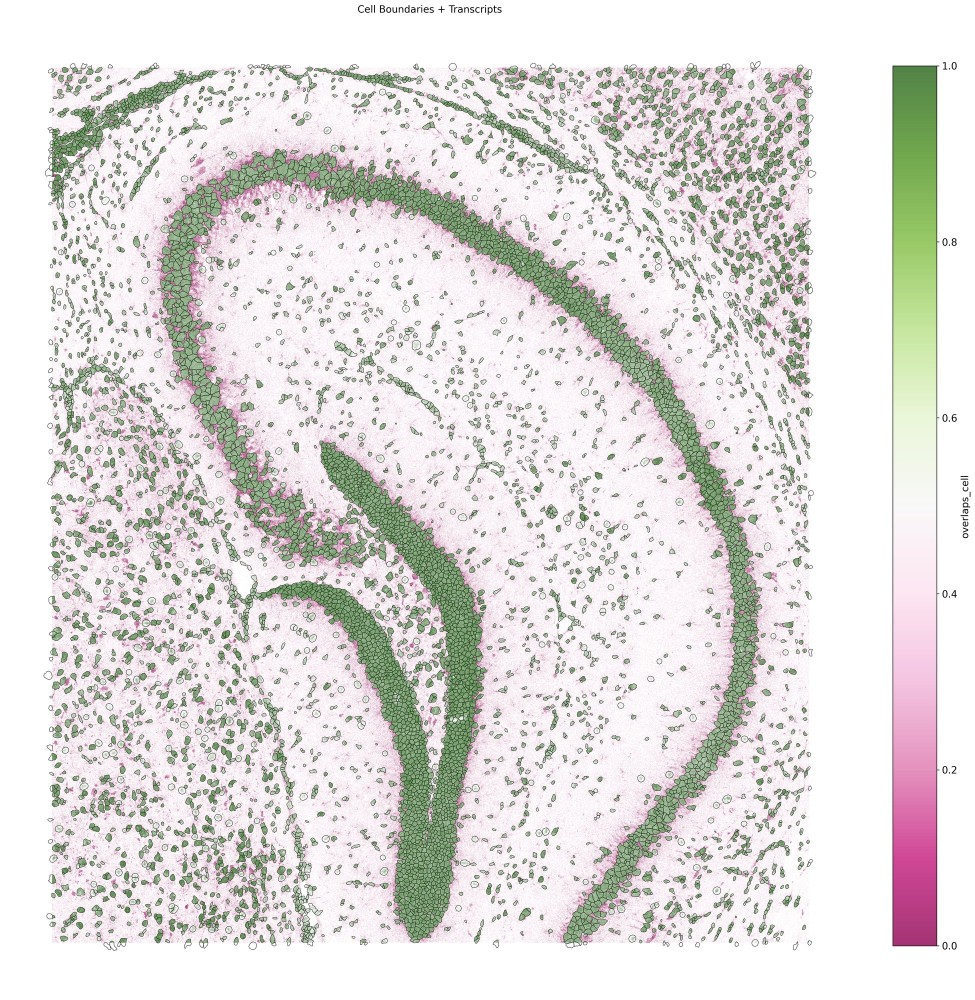

In [14]:
spatial_transcripts(sdata,figsize=(20,20),boundary_linewidth=0.5,scatter_size=0.02,color_key='overlaps_cell',colormap='PiYG')
plt.savefig('../../overlaps_cells.png',dpi=500)